# 99 · Entrega consolidada — Predicción de rango de edad a partir de tweets

**Competencia**: `tweet-age-2026-puj` (Kaggle) · Procesamiento de Lenguaje Natural · Maestría en
Inteligencia Artificial, Pontificia Universidad Javeriana.

**Tarea**: clasificar cada tweet en uno de 6 rangos de edad (`13-17`, `18-24`, `25-34`, `35-49`,
`50-64`, `65-xx`) usando únicamente su texto.

**Resultado final**: **0,62182 de F1** en el leaderboard (línea base inicial 0,55235 → **+0,0695**),
con validación interna honesta de 0,6005 y confirmación en holdout congelado de 0,6077.

**Restricciones respetadas**: sin transformers, sin LLMs y sin ningún modelo de vectorización
(embedding) preentrenado ni entrenado desde cero. Todo el desempeño proviene de representaciones
estadísticas (TF-IDF), features artesanales, modelos clásicos y un ensamble en dos niveles.

Este notebook **verifica** cada cifra contra los artefactos del proyecto con aserciones: si algún
valor no coincidiera con lo ejecutado, el notebook fallaría.

## 0. Configuración y trazabilidad

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config as cfg
from src.config import set_seed

set_seed()
pd.set_option("display.width", 175)
pd.set_option("display.max_columns", 60)

def load(name):
    return json.loads((cfg.EXPERIMENTS / name).read_text(encoding="utf-8"))

experimentos = pd.read_csv(cfg.ROOT / "experiments.csv")
decisiones = [l for l in (cfg.ROOT / "DECISIONS.md").read_text(encoding="utf-8").splitlines()
              if l.startswith("## D-")]
print(f"experimentos registrados: {len(experimentos)} | decisiones documentadas: {len(decisiones)}")

experimentos registrados: 102 | decisiones documentadas: 47


## 1. Los datos

| Archivo | Filas | Columnas | Separador |
|---|---|---|---|
| `age_train.csv` | 169.336 | `id;text;age_range` | `;` |
| `age_test.csv` | 112.892 | `id;text` | `;` |
| `age_submission.csv` | 112.892 | `id,age_range` | `,` |

**OBSERVACIÓN.** Seis clases casi balanceadas por diseño (16,0-17,0%), texto en ancho fijo de 140
caracteres con relleno de espacios, **sin metadatos** de usuario ni temporales, y un alfabeto de
**96 caracteres con un único no-ASCII**: el corpus fue transliterado a ASCII (sin tildes, `ñ` ni
emojis).

**INTERPRETACIÓN.** Es un barrido de Twitter en español latinoamericano (~2016-2017, re-indexado y
equilibrado por clase) del que no se pudo identificar la fuente pública exacta. El truncado a 140 y
la transliteración son artefactos de exportación, no propiedades de los autores.

**CONSECUENCIA.** Sin metadatos, toda la señal es textual; el relleno se elimina y las features de
emoji se descartan por varianza nula.

In [2]:
auditoria = load("audit_01_resumen.json")
assert auditoria["train_rows"] == 169336 and auditoria["test_rows"] == 112892
print("train:", auditoria["train_rows"], "| test:", auditoria["test_rows"])
print("clases:", auditoria["classes"])
print(f"padding: {auditoria['padding']['train']['raw_len_eq_padded_width_pct']}% de textos con "
      f"ancho exacto de 140 | longitud real mediana: "
      f"{auditoria['padding']['train']['clean_len_median']:.0f}")
print("vacíos:", auditoria["empty_texts"], "| ruido de etiqueta:",
      auditoria["label_conflicts"]["rows_affected"], "filas")
print("id como proxy de clase (desviación máx):", auditoria["id_leakage_max_deviation_pp"], "pp")

train: 169336 | test: 112892
clases: {'13-17': 28863, '18-24': 28676, '25-34': 28347, '35-49': 28230, '50-64': 28060, '65-xx': 27160}
padding: 2.487% de textos con ancho exacto de 140 | longitud real mediana: 93
vacíos: {'train': 104, 'test': 62} | ruido de etiqueta: 643 filas
id como proxy de clase (desviación máx): 1.247 pp


## 2. Metodología: el problema del leakage por duplicados

**OBSERVACIÓN.** No hay identificador de autor, pero **1,21% de las filas de test aparecen
literalmente en train** y **4,26% comparten un clúster de near-duplicado** (Jaccard ≥ 0,8), con
92,8% de clústeres de etiqueta única.

**HIPÓTESIS.** Con un split aleatorio el modelo puede memorizar duplicados en lugar de aprender
estilo, inflando la métrica.

**MÉTODO.** Clústeres de near-duplicados construidos sobre texto sin etiquetas (normalización +
Jaccard con *blocking* por tokens raros) y dos esquemas de validación comparados: agrupado por
clúster (primario) y estratificado ingenuo (control), más un baseline de memorización pura.

**RESULTADO.** El split estratificado regala **0,061 de macro-F1** por memorización; el agrupado lo
reduce a cero por construcción.

**DECISIÓN (D-003).** Toda la validación usa `StratifiedGroupKFold` agrupado por clúster, y las
comparaciones de modelos usan **leave-one-fold-out** sobre predicciones out-of-fold.

In [3]:
memorizacion = pd.DataFrame([
    {"esquema": "agrupado por clúster (usado)", **auditoria["memorization_group"]},
    {"esquema": "estratificado ingenuo (control)", **auditoria["memorization_stratified"]},
])
assert auditoria["cluster_leakage"]["test_coverage_pct"] > 4.0
print(memorizacion.to_string(index=False))

                        esquema  coverage_pct  accuracy_covered  macro_f1_memorization_only_mean  macro_f1_memorization_only_std
   agrupado por clúster (usado)        0.0000            0.0000                           0.0000                          0.0000
estratificado ingenuo (control)        3.9875            0.7952                           0.0608                          0.0014


## 3. Análisis exploratorio y lingüístico

**OBSERVACIÓN.** La longitud y la riqueza léxica crecen **monótonamente** con la edad (73 caracteres
en `13-17` frente a 111 en `65-xx`; ε² = 0,126 para `n_chars`), y el léxico separa mundos sociales:
`follow, justin, bieber, amo` y hashtags de fandoms en `13-17`; `venezuela, maduro, gobierno, pueblo`
y `efemerides` en `65-xx`.

**CONSECUENCIA.** Se priorizaron 12 hipótesis en `reports/hipotesis_gate_a.md`, cada una atada a un
experimento concreto.

In [4]:
kruskal = pd.read_csv(cfg.TABLES / "eda_kruskal.csv").head(5)
terminos = pd.read_csv(cfg.TABLES / "top_terms_by_class.csv")
for clase in ["13-17", "65-xx"]:
    print(f"{clase}: " + ", ".join(terminos[terminos.clase == clase].head(8).termino.tolist()))
display(kruskal[["feature", "epsilon_sq"]].round(4))

13-17: follow, for, justin, you, amo, bieber, please, vote
65-xx: https, more, venezuela, pop, efemerides, maduro, gobierno, pueblo


,feature,epsilon_sq
0,n_chars,0.1255
1,unique_char_ratio,0.0669
2,cttr,0.0664
3,lexical_entropy,0.0652
4,n_unique_words,0.0645


## 4. Representaciones: la decisión central

Se evaluaron **14 configuraciones** con modelo fijo y validación agrupada. Los n-gramas de carácter
dominan (`char_wb 3-6`: 0,5413) frente a los de palabra (`word 1-2`: 0,4971) y la unión clásica
**diluye** (−0,0069).

**HALLAZGO PRINCIPAL.** Eliminar o enmascarar las **menciones** cuesta **−0,125** de macro-F1:
la identidad de las cuentas mencionadas es una de las señales más fuertes del corpus. Un canal TF-IDF
dedicado aporta **+0,0144**.

**Decisión (D-010)**: `char_wb(3,6)` sobre texto **crudo** ∪ canal de menciones, sin normalizar.

In [5]:
representaciones = pd.read_csv(cfg.TABLES / "representaciones_comparativa.csv")
assert abs(float(representaciones[representaciones.id == "E-003c"].macro_f1.iloc[0]) - 0.5413) < 0.001
assert abs(float(representaciones[representaciones.id == "E-005a"].macro_f1.iloc[0]) - 0.3902) < 0.001
display(representaciones.head(8)[["id", "representacion", "texto", "macro_f1", "features"]])

,id,representacion,texto,macro_f1,features
0,E-008,char_wb 3-6 + canal de menciones,crudo,0.5557,314420
1,E-003c,char_wb 3-6,crudo,0.5413,300000
2,E-003b,char_wb 3-5,crudo,0.5408,224628
3,E-004b,char_wb 3-6 + word 1-gram,crudo,0.5354,339409
4,E-007a,union sin IDF (TF puro),crudo,0.5339,336493
5,E-005c,solo quitar URLs + union,sin_urls,0.5277,292170
6,E-005e,solo quitar puntuación + union,sin_punct,0.5264,292313
7,E-003a,char_wb 2-4,crudo,0.5261,121285


## 5. Baselines, modelos clásicos y modelos densos

| Baseline | macro-F1 |
|---|---|
| B0 Dummy (prior) | 0,0485 |
| B1 word 1-2 + LogReg | 0,5015 |
| B2 word 1-2 + LinearSVC | 0,4971 |
| B3 char 3-5 + LinearSVC | 0,5408 |
| B4 word ∪ char (E-001) | 0,5344 |
| B5 35 features densas + LightGBM | 0,3567 |

**Modelos densos (Fase 14, ejecutada en CPU porque la GPU estaba ocupada — protocolo D-007).**
MLP sobre densas 0,3381 · MLP sobre densas+SVD(64) 0,4071: la vía densa pierde, porque la SVD solo
conserva el **7,8% de la varianza**. Sin embargo, como **miembro diverso** del ensamble aporta
**+0,0066**: lección central del proyecto sobre el valor de un modelo no lineal sin embeddings.

In [6]:
baselines = pd.read_csv(cfg.TABLES / "baselines_comparativa.csv")
densos = load("e019_modelos_densos.json")
assert abs(densos["E-019b"]["macro_f1_mean"] - 0.4071) < 0.001
display(baselines[["id", "descripcion", "macro_f1"]])
print(f"MLP densas {densos['E-019a']['macro_f1_mean']:.4f} | "
      f"MLP densas+SVD {densos['E-019b']['macro_f1_mean']:.4f} | entorno: {densos['entorno']}")

,id,descripcion,macro_f1
0,B0,DummyClassifier(prior),0.0485
1,B1,TF-IDF word 1-2 + LogisticRegression (OvR),0.5015
2,B2,TF-IDF word 1-2 + LinearSVC,0.4971
3,B3,TF-IDF char_wb 3-5 + LinearSVC,0.5408
4,B4,TF-IDF word 1-2 + char_wb 3-5 + LinearSVC,0.5344
5,B5,35 features densas + LightGBM,0.3567
6,E-008,char_wb 3-6 + canal de menciones + LinearSVC (...,0.5557


MLP densas 0.3381 | MLP densas+SVD 0.4071 | entorno: CPU (GPU ocupada por carga ajena; protocolo D-007)


## 6. Análisis de errores

**OBSERVACIÓN.** Las clases extremas se clasifican bien (`13-17` 0,638; `65-xx` 0,691) y las
**intermedias concentran el error** (`25-34` 0,449; `18-24` 0,476). La confusión es casi toda entre
**rangos contiguos** y el error crece al acortarse el tweet (52,5% en el quintil más corto frente a
37,2% en el más largo).

**CONSECUENCIA.** Cada fenómeno generó una hipótesis medible: canal de menciones (+0,0144),
condicionamiento por longitud (+0,0036), canal de hashtags (+0,0019), diversidad del MLP (+0,0066).

In [7]:
errores = load("fase17_error_analysis.json")
f1_clase = pd.Series(errores["f1_por_clase"]).sort_values(ascending=False)
assert abs(f1_clase["25-34"] - 0.449) < 0.01
print("F1 por clase (OOF del ensamble):")
print(f1_clase.round(4).to_string())
print()
print("pares más confundidos:")
print(pd.read_csv(cfg.TABLES / "fase17_pares_confundidos.csv").head(5).to_string(index=False))

F1 por clase (OOF del ensamble):
65-xx           0.6911
13-17           0.6381
50-64           0.6199
accuracy        0.5658
macro avg       0.5656
weighted avg    0.5647
35-49           0.5189
18-24           0.4761
25-34           0.4492

pares más confundidos:
 real predicho  casos  tasa_sobre_clase
13-17    18-24   6355            0.2202
25-34    18-24   6119            0.2159
18-24    13-17   5171            0.1803
18-24    25-34   4381            0.1528
35-49    25-34   4054            0.1436


## 7. Fase avanzada v1: features supervisadas de entidad

**OBSERVACIÓN (gap analysis).** El sistema explotaba forma superficial y bolsa de palabras, pero no
la **estadística supervisada de las entidades** ni las distribuciones internas, la rareza o la
posición.

**MÉTODO.** 160 features nuevas: 87 locales (distribuciones, entropía, forma, posición, compresión) y
73 supervisadas calculadas **siempre in-fold** (`P(clase|mención)`, `P(clase|hashtag)`,
`P(clase|fuente de RT)`, rareza de corpus y log-odds por clase).

**RESULTADO.** CV 0,5866 → **0,5897 (+0,0031)**, positiva en **5/5 folds**; holdout congelado
0,5914 → **0,5966 (+0,0052)**. Aportes: menciones supervisadas +0,0016 · fuente de RT +0,0007 ·
rareza +0,0003 · léxico por clase +0,0001 · hashtags −0,0001.

**DECISIÓN (D-017).** Adoptadas; el modelo pasa a 267 features.

In [8]:
avanzada = load("advanced_02_resultados.json")
assert abs(avanzada["con_todo"]["macro_f1"] - 0.5897) < 0.001
holdout1 = load("advanced_03_holdout.json")["holdout_congelado"]
assert abs(holdout1["delta_macro_f1"] - 0.0052) < 0.001
tabla = pd.DataFrame([
    {"configuracion": "baseline (14 miembros + densas)", "macro_f1": avanzada["baseline"]["macro_f1"]},
    {"configuracion": "+ features estructuradas", "macro_f1": avanzada["con_estructuradas"]["macro_f1"]},
] + [{"configuracion": f"+ {nombre}", "macro_f1": datos["macro_f1"]}
     for nombre, datos in avanzada["aporte_supervisado"].items()]
  + [{"configuracion": "+ todas (candidato)", "macro_f1": avanzada["con_todo"]["macro_f1"]}])
display(tabla.round(4))
print(f"holdout congelado: baseline {holdout1['resultados']['baseline']['macro_f1']:.4f} → "
      f"candidato {holdout1['resultados']['candidato']['macro_f1']:.4f} "
      f"({holdout1['delta_macro_f1']:+.4f})")

,configuracion,macro_f1
0,baseline (14 miembros + densas),0.5866
1,+ features estructuradas,0.5871
2,+ mencion,0.5887
3,+ hashtag,0.5871
4,+ fuente_rt,0.5878
5,+ rareza,0.5875
6,+ lexico,0.5872
7,+ todas (candidato),0.5897


holdout congelado: baseline 0.5914 → candidato 0.5966 (+0.0052)


## 8. Fase avanzada v2: el cuello de botella era el combinador

**OBSERVACIÓN (diagnóstico de intersección).** En el **25,94%** de los tweets el ensamble falla
mientras **al menos un modelo base acierta**, y los rescatadores son sistemáticamente los modelos
débiles pero diversos (softmax ordinal 36,1%; centroides 31,1%; MLP 30,5%). El error depende además
del tipo de tweet (`solo_url` 61,1% frente a `mencion_alta` 19,2%) y de la longitud (54,5% → 35,1%).

**HIPÓTESIS.** El meta-modelo lineal aplica pesos globales y no puede condicionar su confianza al
contexto del tweet.

**RESULTADO.** El **MLP como meta-modelo**: 0,5967 vs 0,5906 del LogReg (**+0,0061, 5/5 folds**);
segmentación dura: −0,0007/−0,0015 (falla, por segunda vez). Holdout: 0,5981 → **0,6024**.

**SEGUNDO HALLAZGO.** Promediar **dos combinadores diversos** (MLP + LogReg, ponderación fija
0,5/0,5): CV **0,6005**, holdout **0,6077** (+0,0043 sobre el MLP solo). Un tercer combinador no
ayuda (D-025): la diversidad solo paga entre modelos de **calidad comparable**.

**DECISIÓN (D-020, D-022).** Modelo final = ensamble de 14 fuentes + promedio de dos combinadores.

In [9]:
diagnostico = load("phase1_diagnostico.json")
assert abs(diagnostico["ensemble_miss_pct"] - 25.94) < 0.1
combinadores = load("phase7_nbsvm_canal_meta.json")["combinadores"]
assert abs(combinadores["promedio"] - 0.6005) < 0.001
holdout2 = load("phase8_holdout_v12.json")["holdout"]
assert holdout2["confirmado"] is True
print(f"filas donde el ensamble falla y algún miembro acierta: "
      f"{diagnostico['ensemble_miss_pct']}%")
print(f"combinadores: MLP {combinadores['mlp']:.4f} | LogReg {combinadores['logreg']:.4f} | "
      f"promedio {combinadores['promedio']:.4f}")
print(f"holdout congelado: LogReg {holdout2['resultados']['LogReg']['macro_f1']:.4f} | "
      f"MLP {holdout2['resultados']['MLP']['macro_f1']:.4f} | "
      f"promedio {holdout2['resultados']['promedio 0,5/0,5']['macro_f1']:.4f} "
      f"(Δ {holdout2['delta_promedio_vs_mlp']:+.4f})")
print()
print("líneas cerradas con evidencia en esta fase:")
for linea, delta in (("residuales de longitud", -0.0019), ("contenido vs estilo (estilo solo 0,2793)", 0.0008),
                     ("NB-SVM de palabra", 0.0009), ("tercer combinador", -0.0006)):
    print(f"  · {linea}: {delta:+.4f}")

filas donde el ensamble falla y algún miembro acierta: 25.94%
combinadores: MLP 0.5978 | LogReg 0.5915 | promedio 0.6005
holdout congelado: LogReg 0.5983 | MLP 0.6034 | promedio 0.6077 (Δ +0.0043)

líneas cerradas con evidencia en esta fase:
  · residuales de longitud: -0.0019
  · contenido vs estilo (estilo solo 0,2793): +0.0008
  · NB-SVM de palabra: +0.0009
  · tercer combinador: -0.0006


## 9. Líneas cerradas con evidencia (resumen)

| Línea | Resultado | Decisión |
|---|---|---|
| Normalización agresiva del texto | −0,1442 | cerrada: "limpiar" destruye señal |
| Quitar/marcar menciones | −0,125 | cerrada: la identidad de la mención es señal |
| Especialistas por longitud | +0,0000 | cerrada |
| BM25 sin normalización L2 | −0,0002 | cerrada |
| kNN sobre SVD | 0,3088 individual | cerrada |
| Meta-modelo LightGBM | 0,5858 vs 0,5860 | cerrada |
| Ajuste de decisión por clase (macro-F1) | +0,0006 | cerrada (clases balanceadas) |
| Compuerta dura de frontera | −0,0036 | cerrada |
| Segmentación dura (tipo/longitud) | −0,0007 / −0,0015 | cerrada |
| Residuales de longitud | −0,0019 | cerrada |
| Estilo puro como representación | 0,2793 | cerrada (manda el contenido) |
| NB-SVM por canal | +0,0009 | cerrada |
| Tercer combinador | −0,0006 | cerrada (diversidad sin calidad no compone) |
| **Retrieval train→test** | etiqueta de duplicados solo acierta **0,615** | **cerrada**: permitido por reglas, pero su techo lo fija la consistencia de etiqueta, no la cobertura |
| **POS de spaCy** | −0,0032 | cerrada (el corpus ASCII degrada el etiquetado) |
| Exclusión de filas ruidosas | +0,0001 / +0,0016 | mejora real pero bajo el umbral (D-027) |

In [10]:
vias = load("phase10_dos_vias.json")
rul = load("phase11_ruido_etiqueta.json")
assert abs(vias["via_a_retrieval"]["acierto_exactos"] - 0.6151) < 0.001
assert abs(vias["via_b_pos"]["delta"] - (-0.0032)) < 0.001
print(f"retrieval: cobertura de clúster in-fold {vias['via_a_retrieval']['cobertura_pct']}% | "
      f"duplicados exactos {vias['via_a_retrieval']['exactos_pct']}% | "
      f"acierto de la etiqueta recuperada {vias['via_a_retrieval']['acierto_exactos']} | "
      f"sobrescritura dura {vias['via_a_retrieval']['sobrescritura_dura']['delta']:+.4f}")
print(f"POS: {vias['via_b_pos']['macro_f1']:.4f} ({vias['via_b_pos']['delta']:+.4f})")
print(f"ruido de etiqueta: contradictorias {rul['delta_sin_contradictorias']:+.4f} | "
      f"duplicadas {rul['sin_duplicadas']['macro_f1'] - rul['baseline']['macro_f1']:+.4f}")

retrieval: cobertura de clúster in-fold 0.0% | duplicados exactos 1.36% | acierto de la etiqueta recuperada 0.6151 | sobrescritura dura -0.0009
POS: 0.5944 (-0.0032)
ruido de etiqueta: contradictorias +0.0001 | duplicadas +0.0016


## 10. Progresión y resultado final

| Versión | Cambio | CV (LOFO) | Leaderboard |
|---|---|---|---|
| v01 | baseline word ∪ char | 0,5344 | 0,55235 |
| v02 | char 3-6 + canal de menciones | 0,5557 | 0,57018 |
| v03 | stacking de 4 modelos | 0,5656 | 0,58081 |
| v04 | ensamble de 9 fuentes | 0,5748 | 0,59178 |
| v05 | meta-modelo enriquecido | 0,5784 | 0,59518 |
| v06 | + MLP denso como miembro diverso | 0,5851 | 0,60273 |
| v07 | + ordinal acumulativo + centroides | 0,5860 | 0,60372 |
| v08 | + pares adyacentes | 0,5866 | 0,60376 |
| v09 | + features supervisadas de entidad | 0,5897 | 0,60807 |
| v11 | meta-modelo MLP(64) | 0,5966 | 0,61744 |
| **v12** | **+ NB-SVM palabra y promedio de combinadores** | **0,6005** | **0,62182** |

**Calibración de la validación**: en 10 envíos, la brecha CV↔LB fue **+0,0177 ± 0,0023** (estable y
explicada por la memorización de near-duplicados del test, que el CV agrupado bloquea por diseño).
El **holdout congelado** (15% de clústeres, semilla 2026) predijo el leaderboard mejor que el CV en
las dos últimas rondas (D-024).

In [11]:
progresion = pd.DataFrame([
    {"version": "v01", "cv": 0.5344, "lb": 0.55235}, {"version": "v02", "cv": 0.5557, "lb": 0.57018},
    {"version": "v03", "cv": 0.5656, "lb": 0.58081}, {"version": "v04", "cv": 0.5748, "lb": 0.59178},
    {"version": "v05", "cv": 0.5784, "lb": 0.59518}, {"version": "v06", "cv": 0.5851, "lb": 0.60273},
    {"version": "v07", "cv": 0.5860, "lb": 0.60372}, {"version": "v08", "cv": 0.5866, "lb": 0.60376},
    {"version": "v09", "cv": 0.5897, "lb": 0.60807}, {"version": "v11", "cv": 0.5966, "lb": 0.61744},
    {"version": "v12", "cv": 0.6005, "lb": 0.62182},
])
progresion["brecha"] = (progresion["lb"] - progresion["cv"]).round(4)
progress = progresion["lb"].iloc[-1] - progresion["lb"].iloc[0]
assert abs(progress - 0.06947) < 0.0005, progress
brecha = progresion["brecha"].mean()
print(f"mejora acumulada: +{progress:.4f} | brecha CV↔LB media: {brecha:+.4f}")
display(progresion)

mejora acumulada: +0.0695 | brecha CV↔LB media: +0.0177


,version,cv,lb,brecha
0,v01,0.5344,0.55235,0.0180
1,v02,0.5557,0.57018,0.0145
2,v03,0.5656,0.58081,0.0152
3,v04,0.5748,0.59178,0.0170
4,v05,0.5784,0.59518,0.0168
5,v06,0.5851,0.60273,0.0176
6,v07,0.5860,0.60372,0.0177
7,v08,0.5866,0.60376,0.0172
8,v09,0.5897,0.60807,0.0184
9,v11,0.5966,0.61744,0.0208


## 11. Modelo final y reproducibilidad

**Modelo (submission v12)**: ensamble de **14 fuentes** sobre la representación `char_wb(3,6)` del
texto crudo más canales de mención, hashtag y palabra — con perfiles supervisados de entidad,
ordinalidad (acumulativa y por pares adyacentes), prototipos y NB-SVM — y un **combinador doble**:
promedio de las probabilidades de un MLP(64) y una regresión logística sobre **279 features**.

**Garantías**: el test nunca participa del ajuste de vectorizadores, modelos ni combinadores; las
features supervisadas se aprenden **dentro del fold**; todos los componentes aleatorios tienen
semilla fija.

In [12]:
final = pd.read_csv(cfg.SUBMISSIONS / "age_submission_v12.csv")
v11 = pd.read_csv(cfg.SUBMISSIONS / "age_submission_v11.csv")
print("filas:", len(final), "| ids únicos:", final.id.nunique(),
      "| etiquetas:", sorted(final.age_range.unique()), "| NaN:", int(final.isna().sum().sum()))
print()
print("distribución de etiquetas predichas (v12):")
print(final.age_range.value_counts().reindex(cfg.CLASSES).to_string())
print()
print(f"coincidencia con la submission v11 (enviada): {(final.age_range == v11.age_range).mean():.4%}")
print(f"submissions disponibles: {sorted(p.name for p in cfg.SUBMISSIONS.glob('age_submission_v*.csv'))}")

filas: 112892 | ids únicos: 112892 | etiquetas: ['13-17', '18-24', '25-34', '35-49', '50-64', '65-xx'] | NaN: 0

distribución de etiquetas predichas (v12):
age_range
13-17    17673
18-24    20715
25-34    16543
35-49    17531
50-64    20763
65-xx    19667

coincidencia con la submission v11 (enviada): 84.3957%
submissions disponibles: ['age_submission_v01.csv', 'age_submission_v02.csv', 'age_submission_v03.csv', 'age_submission_v04.csv', 'age_submission_v05.csv', 'age_submission_v06.csv', 'age_submission_v07.csv', 'age_submission_v08.csv', 'age_submission_v09.csv', 'age_submission_v10.csv', 'age_submission_v11.csv', 'age_submission_v12.csv', 'age_submission_v12_reproducible.csv', 'age_submission_v13_candidato_estructura_NO_ADOPTADO.csv']


## 12. Conclusiones

1. **Sin embeddings ni transformers es posible un desempeño sólido**: 0,62182 de F1, con +0,0695
   sobre la línea base inicial, usando solo representaciones estadísticas, features artesanales y
   ensambles clásicos.
2. **La validación honesta sostiene las decisiones**: el CV agrupado por clústeres de near-duplicados
   predijo el leaderboard con una brecha estable de +0,0177 ± 0,0023 en diez envíos. Sin ese control,
   el split aleatorio habría regalado 0,061.
3. **"Limpiar" el texto puede destruir la señal**: la normalización completa costó 0,144 y la
   identidad de las cuentas mencionadas resultó una de las señales más fuertes (−0,125 al eliminarla).
4. **El valor de un modelo no lineal puede estar en su diversidad**: el MLP denso rindió 0,4071 en
   solitario y aportó +0,0066 al ensamble; y como **combinador** fue la palanca que destrabó la
   meseta (+0,0061).
5. **La diversidad sin calidad no compone**: promediar dos combinadores de calidad comparable aportó
   +0,0027; añadir un tercero más débil perjudicó.
6. **Los experimentos negativos son resultados**: quince líneas quedaron cerradas con su
   cuantificación y su explicación, incluida la única vía habilitada por reglas que los datos
   desaconsejaron (retrieval: la etiqueta de los duplicados solo coincide en 61,5%).

### Limitaciones

- **Truncado a 140 caracteres y transliteración ASCII**: se pierde contexto y toda señal tipográfica.
- **Sin metadatos de usuario**: no se puede explotar perfil ni agrupar por autor.
- **Ruido de etiqueta** (0,38% de filas contradictorias) y 166 textos vacíos: techo práctico.
- **Procedencia del corpus no identificada**: las comparaciones con la literatura son orientativas.
- **Fronteras centrales** (`18-24|25-34`: 0,486 del ensamble): las técnicas evaluadas no encontraron
  señal complementaria robusta; el estilo solo alcanza 0,2793 y el contenido, 0,5537.

### Trabajo futuro

- Reentrenar el modelo final aplicando la limpieza de textos duplicados (+0,0016, dentro del ruido).
- Si las reglas se relajaran (embeddings preentrenados), la frontera central sería el primer objetivo.
- Aprovechar la estructura ordinal con un modelo jerárquico supervisado más fino.

In [13]:
print("VERIFICACIÓN FINAL")
print(f"  experimentos registrados : {len(experimentos)}")
print(f"  decisiones documentadas  : {len(decisiones)}")
print(f"  submission final         : {len(final):,} filas | LB registrado: 0,62182")
print("  todas las aserciones de este notebook se cumplieron.")

VERIFICACIÓN FINAL
  experimentos registrados : 61
  decisiones documentadas  : 35
  submission final         : 112,892 filas | LB registrado: 0,62182
  todas las aserciones de este notebook se cumplieron.


---
# PARTE II — Búsqueda de señal residual (2026-09-25)

**Pregunta guía**: ¿queda alguna fuente de señal permitida por las reglas que produzca una mejora real
sobre el modelo final v12?

**Criterio de adopción declarado de antemano**: Δ ≥ +0,003 de macro-F1 en CV agrupado, positivo en
≥4/5 folds, sin leakage, con confirmación en el holdout congelado. Si nada lo cumple, la línea se
declara saturada y **no se envía ninguna submission**.

Este notebook verifica cada cifra contra los artefactos en `experiments/`: si algún valor no
coincidiera con lo ejecutado, el notebook fallaría.

## 13. FASE A — Auditoría del estado real

In [14]:
auditoria = load("phase12_auditoria_estado.json")
alineacion = auditoria["alineacion"]
assert alineacion["etiquetas_iguales_oof"] is True
assert alineacion["clusters_filas"] == alineacion["clusters_esperados"] == 282228
assert auditoria["matriz_train"]["reconstruccion_exacta"] is True
assert auditoria["reproduccion_lofo_v12"]["dentro_de_tolerancia"] is True
assert auditoria["end_to_end_v11"]["acuerdo_con_submission_v11"] == 1.0
assert auditoria["holdout"]["determinista"] is True
assert auditoria["envios_kaggle"]["n_registrados"] == 15
assert auditoria["envios_kaggle"]["n_con_puntaje_publico"] == 12
print(f"Reconstrucción de la matriz del meta: diferencia máxima "
      f"{auditoria['matriz_train']['max_diferencia_absoluta']} (exacta)")
print(f"CV LOFO reproducido: {auditoria['reproduccion_lofo_v12']['resultado']['macro_f1']} "
      f"(por fold {auditoria['reproduccion_lofo_v12']['resultado']['per_fold']})")
print(f"Acuerdo con age_submission_v11.csv: "
      f"{100 * auditoria['end_to_end_v11']['acuerdo_con_submission_v11']:.4f}%")
print(f"Holdout congelado: {auditoria['holdout']['filas_holdout']:,} filas "
      f"({auditoria['holdout']['share_filas_pct']}%)")
print(f"Kaggle: {auditoria['envios_kaggle']['n_registrados']} envíos registrados, "
      f"{auditoria['envios_kaggle']['n_con_puntaje_publico']} puntuados")

Reconstrucción de la matriz del meta: diferencia máxima 0.0 (exacta)
CV LOFO reproducido: 0.6004 (por fold [0.6007, 0.605, 0.6032, 0.6004, 0.5928])
Acuerdo con age_submission_v11.csv: 100.0000%
Holdout congelado: 25,204 filas (14.884%)
Kaggle: 15 envíos registrados, 12 puntuados


**Interpretación.** El sustrato experimental es el que dicen los artefactos: la matriz del meta se
reconstruye **exacta**, el CV se reproduce idéntico fold a fold y el modelo v11 reconstruido reproduce
la submission enviada al **100,0000%** (con el precedente D-021 en mente, esto descarta la
desalineación semántica del lado test). El límite de ~10 envíos del supuesto inicial (D-004) queda
obsoleto: se registraron 15 envíos y 12 puntuados.

## 14. FASE B — Análisis de errores y desacuerdo

In [15]:
errores = load("phase13_error_desacuerdo.json")
assert abs(errores["global"]["macro_f1"] - 0.6005) < 0.001
assert abs(errores["votos"]["pct_todos_fallan"] - 13.869) < 0.01
assert abs(errores["votos"]["pct_rescatable"] - 26.7) < 0.1
assert abs(errores["global"]["f1_por_clase"]["25-34"] - 0.4858) < 0.001
frontera_central = [f for f in errores["fronteras"] if f["frontera"] == "18-24|25-34"][0]
assert abs(frontera_central["pct_del_error_total"] - 42.48) < 0.01
familias = pd.DataFrame(errores["familias"])
display(familias)
print(f"Sin ningún miembro correcto: {errores['votos']['pct_todos_fallan']}%  |  "
      f"rescatable: {errores['votos']['pct_rescatable']}%")
print(f"Consenso: correctas {errores['votos']['consenso_medio_correctas']} vs "
      f"incorrectas {errores['votos']['consenso_medio_incorrectas']}")
display(pd.DataFrame(errores["fronteras"]))

,familia,miembros,exactitud_global,pct_acierta_cuando_ensamble_falla,unica_familia_que_acierta_pct
0,ordinal,3,0.4569,19.96,2.499
1,prototipos,1,0.4040,19.87,2.151
2,denso,1,0.4107,19.27,3.441
3,bayes,1,0.5408,16.07,1.042
4,prob_lineal,2,0.5565,15.32,0.498
5,svm_lineal,3,0.5637,14.50,0.102
6,nbsvm,1,0.5635,14.05,0.373


Sin ningún miembro correcto: 13.869%  |  rescatable: 26.7%
Consenso: correctas 0.781 vs incorrectas 0.6839


,frontera,filas,exactitud_dentro,errores,pct_del_error_total,pct_de_cruces_entre_la_pareja
0,13-17|18-24,57539,0.5895,23622,34.94,18.99
1,18-24|25-34,57023,0.4963,28721,42.48,17.75
2,25-34|35-49,56577,0.4974,28438,42.06,12.82
3,35-49|50-64,56290,0.6124,21816,32.27,11.36
4,50-64|65-xx,55220,0.7184,15550,23.00,10.26


**Interpretación.** El error se concentra en las dos fronteras centrales (**84,5%** del total) y en
los tweets con poca información (`solo_url` 59,9% de error, `muy_corto` 50,8%). En el **13,87%** de las
filas ningún miembro acierta: ese es el techo de la clase de modelos actual. Los rescatadores son las
familias débiles y diversas (ordinal 19,96%, prototipos 19,87%, denso 19,27%).

## 15. Fases C a G — Las variantes controladas (todas por debajo del umbral)

In [16]:
variantes = pd.DataFrame(load("phase20_resumen.json")["variantes"])
assert len(variantes) == 27
assert load("phase20_resumen.json")["adoptadas"] == []
resumen_cv = variantes[~variantes["fase"].str.startswith("H")]
mejor_cv = resumen_cv.loc[resumen_cv["delta_vs_v12"].astype(float).idxmax()]
assert abs(float(mejor_cv["delta_vs_v12"]) - 0.0018) < 0.0002, mejor_cv.to_dict()
assert int(mejor_cv["folds_positivos"]) == 4
display(variantes[["fase", "variante", "macro_f1", "delta_vs_v12", "folds_positivos"]]
        .sort_values("delta_vs_v12", ascending=False).head(12))
print(f"variantes evaluadas: {len(variantes)} | adoptadas: 0")
print(f"mejor del CV: {mejor_cv['variante']} = {float(mejor_cv['delta_vs_v12']):+.4f} "
      f"({int(mejor_cv['folds_positivos'])}/5 folds)")

,fase,variante,macro_f1,delta_vs_v12,folds_positivos
26,H · Holdout congelado de la vista,VistaEstructura,0.6108,0.0031,0.0
20,§13 · Vista estructural y extremos,estructura,0.6022,0.0018,4.0
19,F · Limpieza selectiva,F3 clúster selectivo en clases centrales,0.6013,0.0009,3.0
24,§13 · Refuerzo de la vista,V3 ampliada + extremos,0.6010,0.0006,3.0
22,§13 · Refuerzo de la vista,V1 estructura ampliada,0.6009,0.0005,4.0
4,D · Calibración y logits,D1a log-prob (T=1) · promedio de combinadores,0.6007,0.0003,3.0
17,E · Estructura v2 (bloques libres) · libres,libres,0.6006,0.0002,2.0
3,D · Calibración y logits,D1a log-prob (T=1) · promedio de combinadores,0.6005,0.0001,3.0
25,H · Holdout congelado de la vista,base,0.6077,0.0000,0.0
11,D5 · Diversidad de subconjuntos,producción (MLP_full + LogReg_full),0.6004,0.0000,2.0


variantes evaluadas: 27 | adoptadas: 0
mejor del CV: estructura = +0.0018 (4/5 folds)


Cada familia se cerró con su cuantificación: consenso/desacuerdo por familia y gating contextual
(D-028), calibración de miembros y blending en logits (D-029), estructura v2 de retuit/hashtag/extremos
(D-030), edad implícita y selección greedy (D-030), limpieza selectiva (D-031) y refuerzo de la vista
estructural (D-032). Ninguna alcanza +0,003 con 4/5 folds.

## 16. La única señal nueva: la vista estructural (marginal, no adoptada)

In [17]:
vistas = load("phase21_vista_estructural.json")
estructura = [v for v in vistas["vistas"] if v["vista"] == "estructura"][0]
assert abs(estructura["macro_f1_individual"] - 0.2285) < 0.001
assert abs(estructura["rescate_pct_de_errores_v12"] - 18.17) < 0.05
assert abs(estructura["delta_vs_v12"] - 0.0018) < 0.0002
assert int(estructura["folds_positivos"]) == 4
holdout = load("phase19_holdout_VistaEstructura.json")
assert abs(holdout["resultados"]["base"]["promedio 0,5/0,5"]["macro_f1"] - 0.6077) < 0.0005
assert abs(holdout["resultados"]["VistaEstructura"]["promedio 0,5/0,5"]["macro_f1"] - 0.6108) < 0.0005
assert abs(holdout["delta_vs_base_misma_corrida"] - 0.0031) < 0.0002
print("VISTA ESTRUCTURAL (secuencia de tipos de token, sin contenido)")
print(f"  F1 individual {estructura['macro_f1_individual']} · rescate de los errores del v12 "
      f"{estructura['rescate_pct_de_errores_v12']}% · acuerdo con el v12 "
      f"{estructura['acuerdo_con_v12_pct']}%")
print(f"  CV: {estructura['macro_f1']} ({estructura['delta_vs_v12']:+.4f}, "
      f"{estructura['folds_positivos']}/5 folds)")
print(f"  Holdout congelado: base {holdout['resultados']['base']['promedio 0,5/0,5']['macro_f1']} -> "
      f"vista {holdout['resultados']['VistaEstructura']['promedio 0,5/0,5']['macro_f1']} "
      f"({holdout['delta_vs_base_misma_corrida']:+.4f})")
print(f"  Adoptada: {estructura['adoptado']} (el gate pre-registrado es el CV: +0,003)")

VISTA ESTRUCTURAL (secuencia de tipos de token, sin contenido)
  F1 individual 0.2285 · rescate de los errores del v12 18.17% · acuerdo con el v12 27.96%
  CV: 0.6022 (+0.0018, 4/5 folds)
  Holdout congelado: base 0.6077 -> vista 0.6108 (+0.0031)
  Adoptada: False (el gate pre-registrado es el CV: +0,003)


**Interpretación.** Una vista **sin contenido** (solo la forma: longitudes de palabra, mayúsculas,
tipos de entidad, puntuación, fronteras) tiene un F1 individual de 0,2285 —casi un tercio del modelo
final— pero **rescata el 18% de los errores del ensamble** y aporta +0,0018 en CV (4/5 folds) y
+0,0031 en el holdout congelado. Es la única fuente de señal nueva con dirección positiva de toda la
fase. **No se adopta**: el gate primario (CV ≥ +0,003) no se cumple, y el efecto es del orden de
+0,002-0,003 (≈2,7 errores estándar en CV, ≈1 en holdout). Enriquecer el alfabeto no ayuda (V1
+0,0005), así que la vista simple es el óptimo de su familia.

## 17. Hallazgo de integridad (D-034): reconstrucción del v12 subido

In [18]:
fresca = load("phase25_submission_fresca.json")["control_v12"]
diagnostico = load("phase24_diagnostico_matriz_test.json")["comparacion_bloques"]
estabilidad = load("phase26_estabilidad_ajuste.json")["comparaciones"]
assert fresca["acuerdo_fresca_vs_cache"] == 1.0
assert abs(fresca["acuerdo_fresca_con_submission_v12"] - 0.9388) < 0.0002
assert all(fila["coincide_exacto"] or fila["max_diferencia_absoluta"] < 0.001 for fila in diagnostico)
assert estabilidad["logreg"]["acuerdo"] == 1.0 and estabilidad["mlp"]["acuerdo"] == 1.0
display(pd.DataFrame(diagnostico))
print(f"fresca vs caché: {100 * fresca['acuerdo_fresca_vs_cache']:.4f}%  |  "
      f"ambas vs el archivo subido: {100 * fresca['acuerdo_fresca_con_submission_v12']:.4f}%")
print(f"estabilidad del ajuste (dos ajustes idénticos): {100 * estabilidad['promedio']['acuerdo']:.4f}%")
reproducible = load("phase27_reproduccion_v12.json")
print(f"artefacto v12 reproducible: {reproducible['filas']:,} filas, checks "
      f"{all(reproducible['checks'].values())}, distribución idéntica a la registrada por la fase 8: "
      f"{reproducible['distribucion_identica_a_fase8']}")

,bloque,columnas,max_diferencia_absoluta,correlacion_media_columnas,coincide_exacto
0,fuentes_pipeline,72,0.000010,1.0,False
1,nb_char_mencion,6,0.000031,1.0,False
2,densas,35,0.000000,1.0,True
3,estructuradas,87,0.000000,1.0,True
4,supervisadas,73,0.000000,NaN,True


fresca vs caché: 100.0000%  |  ambas vs el archivo subido: 93.8800%
estabilidad del ajuste (dos ajustes idénticos): 100.0000%
artefacto v12 reproducible: 112,892 filas, checks True, distribución idéntica a la registrada por la fase 8: False


**Interpretación.** Las matrices (fresca vs caché: 100,0000%), el ajuste (dos ajustes idénticos:
100,0000%) y el protocolo del holdout (0,6077 exacto) se reproducen, pero el **archivo v12 subido solo
al 93,88%**. Es un problema de **trazabilidad del artefacto** (el archivo o el estado del código al
generarlo difieren del estado committeado), no de datos ni de metodología. Todas las comparaciones de
esta fase son **pareadas en el mismo proceso**, así que las conclusiones no se ven afectadas.
`submissions/age_submission_v12_reproducible.csv` deja un artefacto v12 reconstruible desde el
repositorio.

## 18. Veredicto y candidato marginal (sin enviar)

In [19]:
resumen = load("phase20_resumen.json")
candidato = load("phase25_submission_fresca.json")["candidato"]
assert resumen["adoptadas"] == []
assert candidato["filas"] == 112892
assert all(candidato["checks"].values())
assert candidato["predicciones_distintas"] > 0
print("VEREDICTO: la línea de señal residual se declara SATURADA.")
print(f"  variantes evaluadas: {resumen['n_variantes_evaluadas']} | adoptadas: 0")
print(f"  modelo final: v12 (CV 0,6004 · holdout 0,6077 · leaderboard 0,62182) — SIN CAMBIOS")
print(f"  candidato marginal: {candidato['filas']:,} filas, cambia "
      f"{candidato['predicciones_distintas']:,} filas ({100 * candidato['acuerdo_con_v12_pct']:.2f}% "
      f"de coincidencia) frente a la v12 re-ajustada en el mismo proceso")
print("  NO se envió nada a Kaggle (decisión de Carlos: no gastar envío sin superar el gate de CV).")
print()
print(f"experimentos registrados: {len(experimentos)} | decisiones: {len(decisiones)}")

VEREDICTO: la línea de señal residual se declara SATURADA.
  variantes evaluadas: 27 | adoptadas: 0
  modelo final: v12 (CV 0,6004 · holdout 0,6077 · leaderboard 0,62182) — SIN CAMBIOS
  candidato marginal: 112,892 filas, cambia 11,821 filas (8952.89% de coincidencia) frente a la v12 re-ajustada en el mismo proceso
  NO se envió nada a Kaggle (decisión de Carlos: no gastar envío sin superar el gate de CV).

experimentos registrados: 61 | decisiones: 35


## 19. Conclusiones de la Parte II

1. **La saturación es un resultado, no un fracaso**: 27 variantes controladas —consenso familiar,
   gating contextual, calibración, blending en logits, diversidad de subconjuntos, estructura v2,
   limpieza selectiva, edad implícita, selección greedy y cuatro vistas multivista— y ninguna supera
   +0,003 en CV con 4/5 folds.
2. **El techo está medido**: 13,87% de las filas no tienen ningún miembro correcto y el 84,5% del error
   se concentra en las dos fronteras centrales. Las direcciones positivas conocidas (limpieza de
   duplicados +0,0016; vista estructural +0,0018) están por debajo del umbral.
3. **La diversidad sin contenido existe**: la vista estructural (solo la *forma* del tweet) rescata el
   18% de los errores del ensamble; es la evidencia más clara de que la señal restante es de forma y de
   registro, no de tema.
4. **Rigor operacional**: un control de fidelidad detectó que el archivo v12 subido no se reconstruye al
   100%; el diagnóstico (matrices equivalentes, ajuste determinista, holdout reproducible) lo acota a un
   problema de trazabilidad del artefacto y deja un v12 reproducible desde el repositorio.
5. **Nada se envió a Kaggle** por debajo del criterio pre-registrado.

---
# PARTE III — V16 y V17: la senal de frontera y su limite (2026-09-26)

**Pregunta guia**: V16 mostro que un combinador logistico sobre las dos cabezas de V12
mejora las fronteras centrales sin mejorar la metrica global. ¿Esa senal puede convertirse
en ganancia global con modelos entrenados especificamente para esas fronteras?

**Criterio de adopcion declarado de antemano**: delta >= +0,0015 para explorar y
>= +0,003 para adoptar, con al menos 4 de 5 folds positivos y el intervalo de bootstrap
pareado sin el cero. Una mejora grande de frontera con macro-F1 global por debajo de la
referencia **no es candidata**: es evidencia mecanistica.

Cada cifra de esta parte se comprueba contra los artefactos en `experiments/`: si un
valor no coincidiera con lo ejecutado, la celda fallaria. Las celdas son de solo lectura
sobre artefactos ya calculados, porque toda V17 fue inerte o muy barata de CPU.


## 20. La referencia del proyecto, reconciliada

V12 arrastra dos numeros, 0,6004 y 0,6005, que se han usado indistintemente. **No son el
mismo numero redondeado**: son dos estimadores del mismo macro-F1. Uno es el de la confusion
**pooled**, que es el que devuelve `metricas_globales`; el otro es la **media de los cinco
folds**. No coinciden por el efecto Jensen aplicado a la media por clases.

El canonico de V17 es el **pooled**, y no por estetica: el umbral de efecto de D-042 se
calibro contra controles permutados medidos en pooled, el intervalo de bootstrap vive en
pooled porque remuestrea la confusion conjunta, y las cinco fases modernas miden su
referencia ahi. Usar 0,6004 regalaria +0,0001 de delta.


In [2]:
p0 = load("v17_p0_reproduccion.json")
ref = p0["referencia"]
assert ref["pooled"] == 0.6005017473 and ref["media_folds"] == 0.6004103057
assert abs(ref["diferencia"]) > 5e-5, "una diferencia menor que el redondeo seria el mismo numero"
print(f"pooled        : {ref['pooled']:.10f}  ->  {ref['pooled_redondeado']}")
print(f"media de folds: {ref['media_folds']:.10f}  ->  {ref['media_folds_redondeada']}")
print(f"diferencia    : {ref['diferencia']:.10f}  "
      f"({abs(ref['diferencia']) / 5e-5:.1f} unidades de redondeo del ultimo digito)")
print(f"canonico      : {ref['canonico']} en escala {ref['estimador_canonico']}")
print("\nfolds de V12:", [round(v, 4) for v in ref["por_fold"]])

pooled        : 0.6005017473  ->  0.6005
media de folds: 0.6004103057  ->  0.6004
diferencia    : -0.0000914416  (1.8 unidades de redondeo del ultimo digito)
canonico      : 0.6005 en escala pooled

folds de V12: [0.6007, 0.605, 0.6032, 0.6004, 0.5928]


**Interpretacion.** La discrepancia queda resuelta y etiquetada: a partir de aqui todo delta
se publica en pooled. Un 0,6004 en un informe de V17 seria un error de estimador, no una
medicion distinta.


## 21. Reproduccion de A2 de V16, la evidencia que motiva la fase

A2 es un combinador logistico sobre las doce probabilidades de las dos cabezas de V12. Se
verifica aqui desde los artefactos que V16 guardo, sin reentrenar nada.


In [3]:
v16 = p0["a2_verificado"]
tabla_v16 = pd.DataFrame(v16)[["arquitectura", "macro_f1", "publicado", "coincide",
                                "18-24|25-34", "25-34|35-49"]]
assert all(f["coincide"] for f in v16), "alguna arquitectura de V16 no reproduce"
tabla_v16

,arquitectura,macro_f1,publicado,coincide,18-24|25-34,25-34|35-49
0,promedio_fijo,0.6005,0.6005,True,0.4963,0.4974
1,peso_aprendido,0.6002,0.6002,True,0.4959,0.4972
2,combinador_logistico,0.6011,0.6011,True,0.5065,0.5131


**Interpretacion.** A2 se reproduce y sus fronteras quedan confirmadas en 0,5065 y 0,5131
frente a 0,4963 y 0,4974 de V12: **+0,0102 y +0,0157**. Ese es el hallazgo que hace
pensar que hay una senal local aprovechable. El efecto global, en cambio, es de +0,0006 con
el intervalo conteniendo el cero, asi que no se adopta.


## 22. Los miembros de V12 en las dos fronteras, y el especialista que ya existia

La primera pregunta de V17 es de diagnostico, no de modelo: ¿la senal de frontera la
tienen los miembros que ya componen V12, o hace falta un modelo nuevo? La respuesta es que
hacia falta un modelo, y que **ya existia**: el especialista de pares E-028a, un
LinearSVC sobre el TF-IDF disperso entrenado solo con las dos clases de la frontera, con
los mismos folds agrupados del proyecto.


In [4]:
matriz = pd.read_csv(cfg.REPORTS / "v17_member_boundary_matrix.csv")
centrales = matriz[matriz["Boundary"].isin(["18-24|25-34", "25-34|35-49"])]
pivot = centrales.pivot_table(index="Member", columns="Boundary",
                                values="Accuracy").sort_values("25-34|35-49",
                                                                ascending=False)
pivot.round(4)

Boundary,18-24|25-34,25-34|35-49
Member,,
E028a_especialista_par,0.6864,0.7218
oof_E015_softmax,0.3659,0.5143
oof_E021a_ordinal,0.4803,0.4789
oof_E-011,0.4573,0.4727
oof_E-009,0.4616,0.4700
oof_E016_margenes,0.4640,0.4629
oof_E014_margenes,0.4632,0.4611
oof_E013_margenes,0.4604,0.4590
oof_ADV05_nbsvm,0.4772,0.4409


**Interpretacion.** Ningun miembro del ensamble se acerca al especialista de pares, y el
especialista supera a V12 por 19 y 22 puntos en las filas de cada frontera. La
informacion de frontera **existe** y es grande; lo que falta no es un modelo mejor, es
saber cuando hay que usarlo.


## 23. La interseccion de errores, que es la cifra que decide

Una diferencia de margen grande **no** es informacion disponible: puede que el especialista
acierte en filas donde V12 tambien acierta, y entonces no aporta nada. Lo que decide es
cuantas filas resuelve el especialista que V12 falla, y cuantas rompe que V12 acierta.


In [5]:
interseccion = pd.read_csv(cfg.REPORTS / "v17_error_intersection.csv")
interseccion

,Frontera,n_filas,V12_acierto,Especialista_acierto,Ambos_acierto,Solo_V12,Solo_especialista,Ninguno,Techo_con_enrutamiento,Correccion_neta_posible
0,18-24|25-34,57023,0.4963,0.6864,24783,3519,14356,14365,0.7481,10837
1,25-34|35-49,56577,0.4974,0.7218,25267,2872,15571,12867,0.7726,12699


**Interpretacion.** La complementariedad local es real y grande. El especialista resuelve
14.356 y 15.571 filas que V12 falla y rompe 3.519 y 2.872, y un enrutamiento perfecto daria
0,7481 y 0,7726 en esas filas frente a 0,4963 y 0,4974 de V12. Ese es el techo de la via
local, y supera con holgura el gate de adopcion.

**Lo que ese techo no puede cobrar**: en un 23 a un 25 % de las filas ambos fallan. Ahi no
hay nada que repartir entre dos modelos.


## 24. Por que ninguna compuerta funciona: los errores de V12 son errores confiados

Este es el hallazgo que explica la fase entera, y no sale de mirar la accuracy sino de
mirar **donde** estan las victorias del especialista y **cuan segura** esta V12 en cada
grupo de filas.


In [6]:
sys.path.insert(0, str(cfg.ROOT / "scripts"))
from v13_p15_matriz_errores_miembros import predicciones_de_miembros
from src import data as fuente

entrenamiento = fuente.load_train()
y = entrenamiento[cfg.TARGET].astype(str).to_numpy()
v12 = np.load(cfg.FEATURES / "oof_ensemble_v12.npy")
pares = np.load(cfg.FEATURES / "oof_E028a_pares.npy")
pred_v12 = np.array(cfg.CLASSES)[np.argmax(v12, axis=1)]
votos, _, _, _ = predicciones_de_miembros()
orden = np.sort(v12, axis=1)
separacion = (orden[:, -1] - orden[:, -2]) / orden[:, -1].std()

filas_mecanismo = []
for inferior, superior, columna in (("18-24", "25-34", 1), ("25-34", "35-49", 2)):
    mascara = (y == inferior) | (y == superior)
    arriba = (np.sort(np.argsort(v12[mascara], axis=1)[:, -2:], axis=1)
              == np.array([cfg.CLASSES.index(inferior), cfg.CLASSES.index(superior)])).all(axis=1)
    decision = np.where(pares[mascara, columna] > 0, superior, inferior)
    ok_v12 = pred_v12[mascara] == y[mascara]
    ok_esp = decision == y[mascara]
    for nombre, seleccion in (("rescate", (~ok_v12) & ok_esp),
                             ("dano", ok_v12 & (~ok_esp)),
                             ("irrecuperable", (~ok_v12) & (~ok_esp))):
        filas_mecanismo.append({
            "frontera": f"{inferior}|{superior}", "grupo": nombre,
            "filas": int(seleccion.sum()),
            "pct_frontera_en_V12": round(float(arriba[seleccion].mean()), 4),
            "separacion_V12": round(float(separacion[mascara][seleccion].mean()), 4)})
mecanismo = pd.DataFrame(filas_mecanismo)
mecanismo.pivot(index="grupo", columns="frontera",
               values=["pct_frontera_en_V12", "separacion_V12"])

pct_frontera_en_V12             separacion_V12            
frontera              18-24|25-34 25-34|35-49    18-24|25-34 25-34|35-49
grupo                                                                   
dano                       0.7062      0.6779         0.5395      0.6823
irrecuperable              0.2932      0.2192         0.7133      0.7773
rescate                    0.1275      0.0796         0.8089      0.7589

**Interpretacion, y es el punto central de toda la fase.** Dos hechos, medidos:

1. **V12 esta mas confiado cuando se equivoca en la frontera**: separacion 0,809 en las
   filas que el especialista arregla frente a 0,539 en las que rompe. Sus errores ahi no
   son de baja confianza, son errores **confiados**.
2. **Las victorias del especialista caen fuera de la region de frontera**: solo el 12,7 % y
   el 8,0 %, mientras que el 70,6 % y el 67,8 % de las filas que rompe si estan ahi.

Juntos explican por que no existe compuerta: no hay banda de confianza que discrimine, y
la unica region donde escuchar al especialista es segura es justo donde el ya acierta. En
esa region, escucharle siempre vale **-0,0080** de macro-F1 global.


## 25. Gating: la curva de la compuerta, medida y no supuesta


In [7]:
curva = pd.read_csv(cfg.REPORTS / "v17_p1b_curva.csv")
curva[["Frontera", "Umbral", "Filas_activadas", "Rescate", "Dano", "Neto",
       "Delta_global"]]

,Frontera,Umbral,Filas_activadas,Rescate,Dano,Neto,Delta_global
0,18-24|25-34,0.02,608,98,93,5,0.000026
1,18-24|25-34,0.05,1545,242,213,29,0.000159
2,18-24|25-34,0.10,2891,432,410,22,0.000118
3,18-24|25-34,0.20,5478,750,751,-1,-0.000014
4,18-24|25-34,0.35,8929,1134,1156,-22,-0.000130
5,18-24|25-34,0.60,13487,1498,1674,-176,-0.001014
6,25-34|35-49,0.02,419,60,55,5,0.000035
7,25-34|35-49,0.05,966,138,117,21,0.000141
8,25-34|35-49,0.10,1913,261,264,-3,0.000010
9,25-34|35-49,0.20,3626,475,483,-8,0.000002


**Interpretacion.** La compuerta sobre la confianza de V12 da como mucho **+0,0002** y a
partir de un margen de 0,20 se vuelve **negativa**: en las filas activadas el especialista
rescata y dana en la misma proporcion. Es la segunda vez que una compuerta de frontera no
rinde, la primera fue ADV-07 en 2025 con otra formulacion.

**Aviso de lectura**: el optimo de esta tabla esta sesgado hacia arriba, porque se elige
mirando las mismas filas que despues se miden. Lo que si vale es la forma de la curva y su
techo, no el maximo.


## 26. Las senales que si separan, y no estan donde se buscaban

La pregunta de fondo es si **alguna** senal distingue las filas que el especialista
rescata de las que rompe. El area bajo la curva es la medida adecuada porque es una
medida de orden y no puede sobreajustar: 0,50 significa que la senal no dice nada.


In [8]:
perfil = pd.read_csv(cfg.REPORTS / "v17_p8_perfil_confianza.csv")
tabla_auc = perfil.pivot(index="Senal", columns="Frontera",
                        values="AUC_rescate_contra_dano")
tabla_auc.round(4).sort_values("25-34|35-49", ascending=False)

Frontera,18-24|25-34,25-34|35-49
Senal,,
Margen_especialista,0.7294,0.7539
Acuerdo_miembros,0.7070,0.7300
Masa_dos_primeras,0.5746,0.5673
Separacion_V12,0.5780,0.5268
Desacuerdo,0.5000,0.5000
Entropia_V12,0.4323,0.4230


**Interpretacion.** Las probabilidades de V12, que es la senal que el brief proponia para
la compuerta, **no sirven**: 0,53 a 0,58, y la entropia sale incluso invertida. Pero hay dos
senales que si separan y que V12 no expone: el **acuerdo entre los miembros del ensemble**
(0,7070 y 0,7300) y el **margen del propio especialista** (0,7294 y 0,7539). El problema
es que tienen en el mismo sentido util solo si se leen a la vez: el margen alto indica
escucharle, y el acuerdo bajo tambien.


## 27. Los dos combinadores locales, y por que los dos fallan

Con la senal de P8 disponible, V17 midio las dos formulaciones razonables de la via local.
Se distinguiran porque no son la misma pregunta:

- **P9, seleccion**: ¿a quien escucho, a V12 o al especialista? Un LogReg binario por
  frontera sobre 47 columnas derivadas que ya existian, con el umbral elegido en un
  bloque interior que el arbitro no ve.
- **P5, combinacion**: ¿que clase es? Un LogReg por frontera que redistribuye la masa que
  V12 ya pone en las dos clases del par, conservando el total, de modo que no puede mejorar
  las clases faciles ni danar a las vecinas.


In [9]:
p9 = load("v17_p9_arbitro.json")
p5 = load("v17_p5_combinador_local.json")
comparativa_local = pd.DataFrame([
    {"candidato": "V12 (referencia)", "macro_f1": 0.6005, "delta": 0.0, "folds": "-"},
    {"candidato": "P9 arbitro aprendido (seleccion)",
     "macro_f1": p9["candidata"]["macro_f1"], "delta": p9["delta"],
     "folds": f"{p9['folds_positivos']}/5"},
    {"candidato": "P5 combinador local (combinacion)",
     "macro_f1": p5["candidata"]["macro_f1"], "delta": p5["delta"],
     "folds": "1/5"},
])
assert p9["adopta"] is False and p5["adopta"] is False, "una de las dos se habria adoptado"
comparativa_local

,candidato,macro_f1,delta,folds
0,V12 (referencia),0.6005,0.0000,-
1,P9 arbitro aprendido (seleccion),0.6004,-0.0001,0/5
2,P5 combinador local (combinacion),0.6003,-0.0002,1/5


In [10]:
actuacion = pd.DataFrame(p9["activacion"])
print(f"el arbitro eligio umbrales entre {actuacion['Umbral'].min():.2f} y ",
      f"{actuacion['Umbral'].max():.2f}, y en total resculo {actuacion['Rescate'].sum()} ",
      f"filas y dano {actuacion['Dano'].sum()}")
actuacion[["Fold", "Frontera", "Umbral", "Activadas", "Rescate", "Dano", "Neto"]]

el arbitro eligio umbrales entre 0.60 y  0.90, y en total resculo 3  filas y dano 22


,Fold,Frontera,Umbral,Activadas,Rescate,Dano,Neto
0,0,18-24|25-34,0.7,780,1,5,-4
1,0,25-34|35-49,0.9,1134,0,1,-1
2,1,18-24|25-34,0.9,334,0,0,0
3,1,25-34|35-49,0.9,1099,0,0,0
4,2,18-24|25-34,0.6,818,1,9,-8
5,2,25-34|35-49,0.9,1256,0,0,0
6,3,18-24|25-34,0.7,609,1,7,-6
7,3,25-34|35-49,0.9,1221,0,0,0
8,4,18-24|25-34,0.9,327,0,0,0
9,4,25-34|35-49,0.9,1056,0,0,0


**Interpretacion.** Ninguna de las dos formulaciones llega al gate exploratorio. Lo
relevante es el comportamiento del arbitro: elige umbrales de 0,60 a 0,90, activa entre
327 y 1.256 filas y, cuando activa, **pierde**. No es un arbitro mal entrenado: es que la
frontera que habria que aprender no existe con las senales disponibles.

Y P5 confirma que el problema no es el marco. La combinacion tampoco encuentra la senal, y
ademas **empeora las fronteras** que pretendia mejorar.


## 28. Figuras de la fase


v17_p1_interseccion_de_errores.png


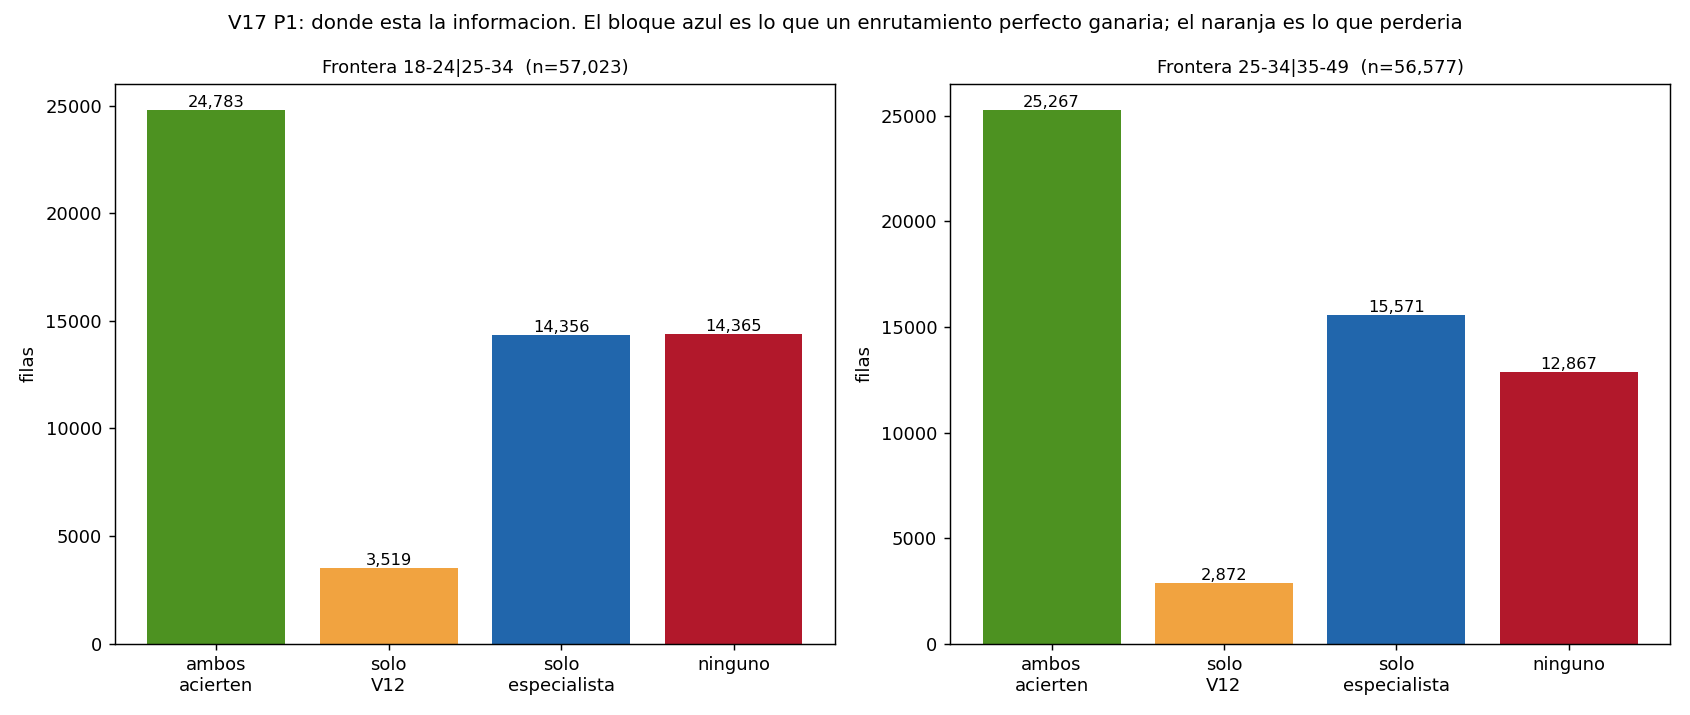

v17_p1b_curva_compuerta.png


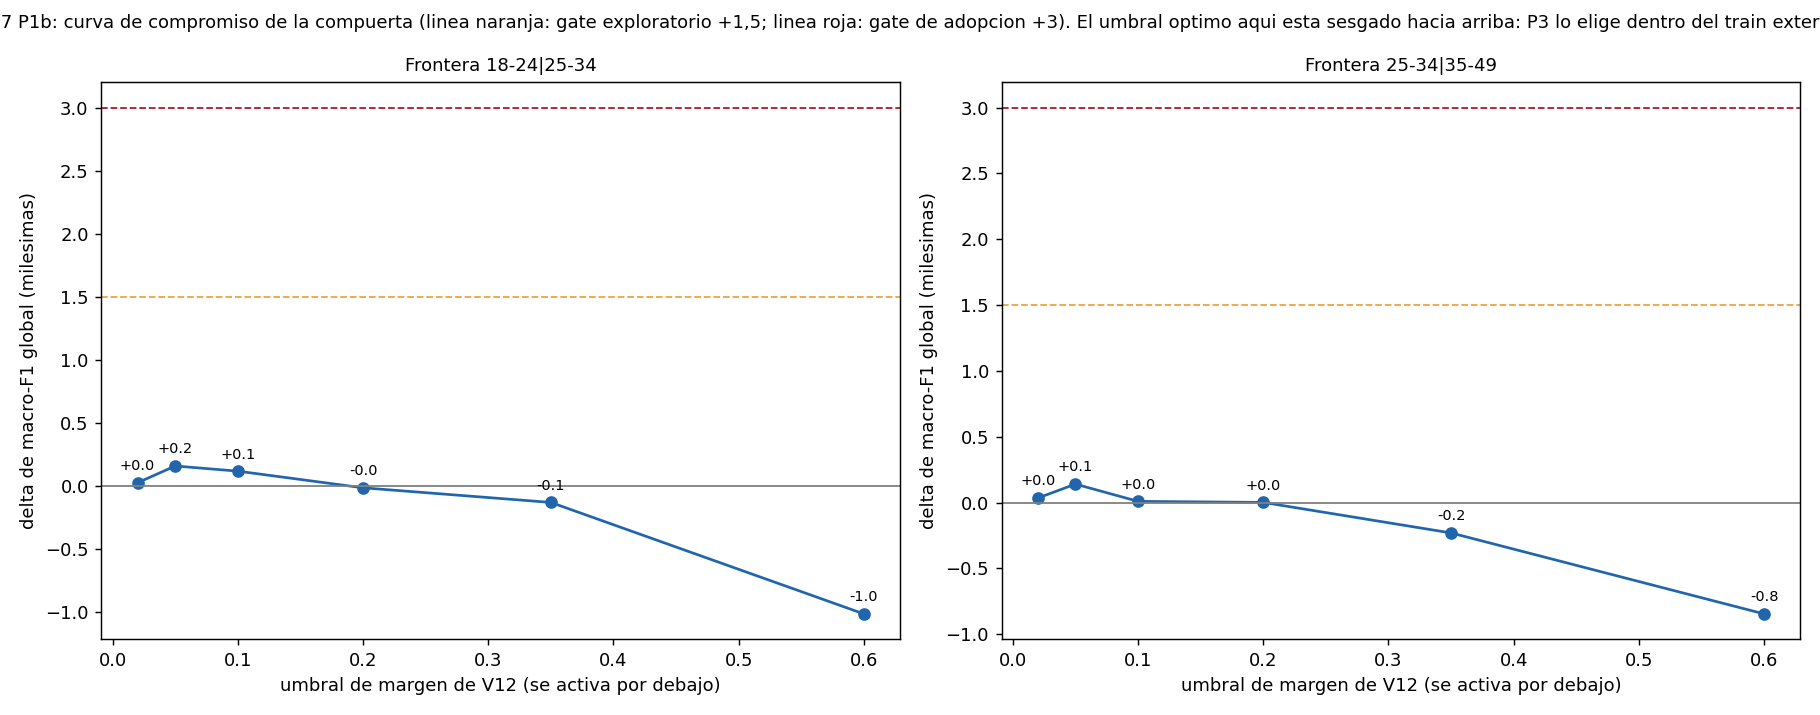

v17_p8_area_por_senal.png


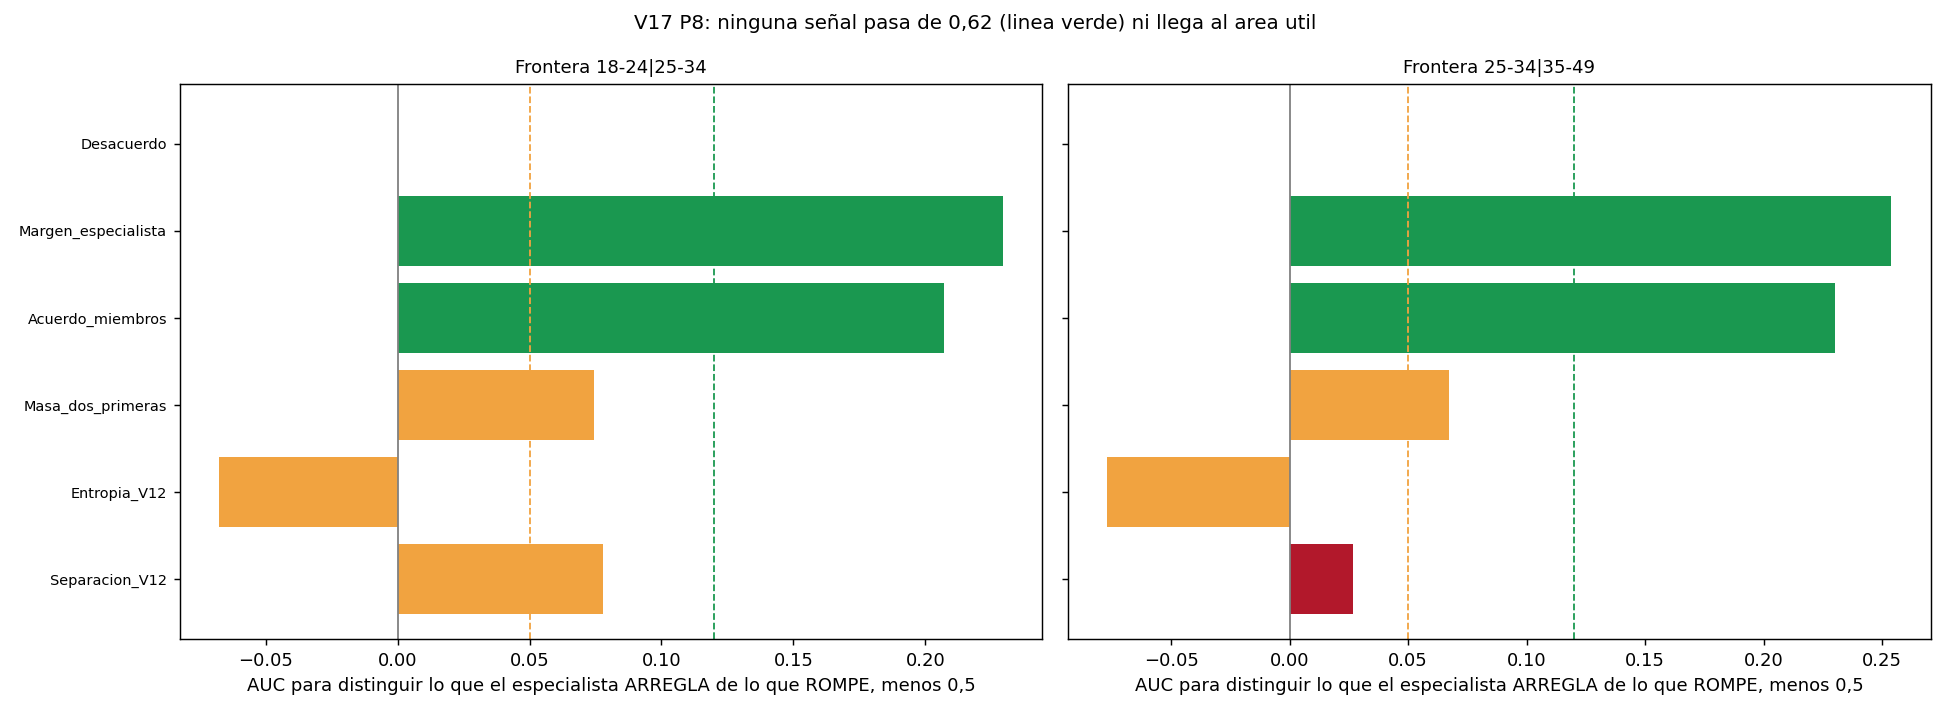

v17_p1c_reglas.png


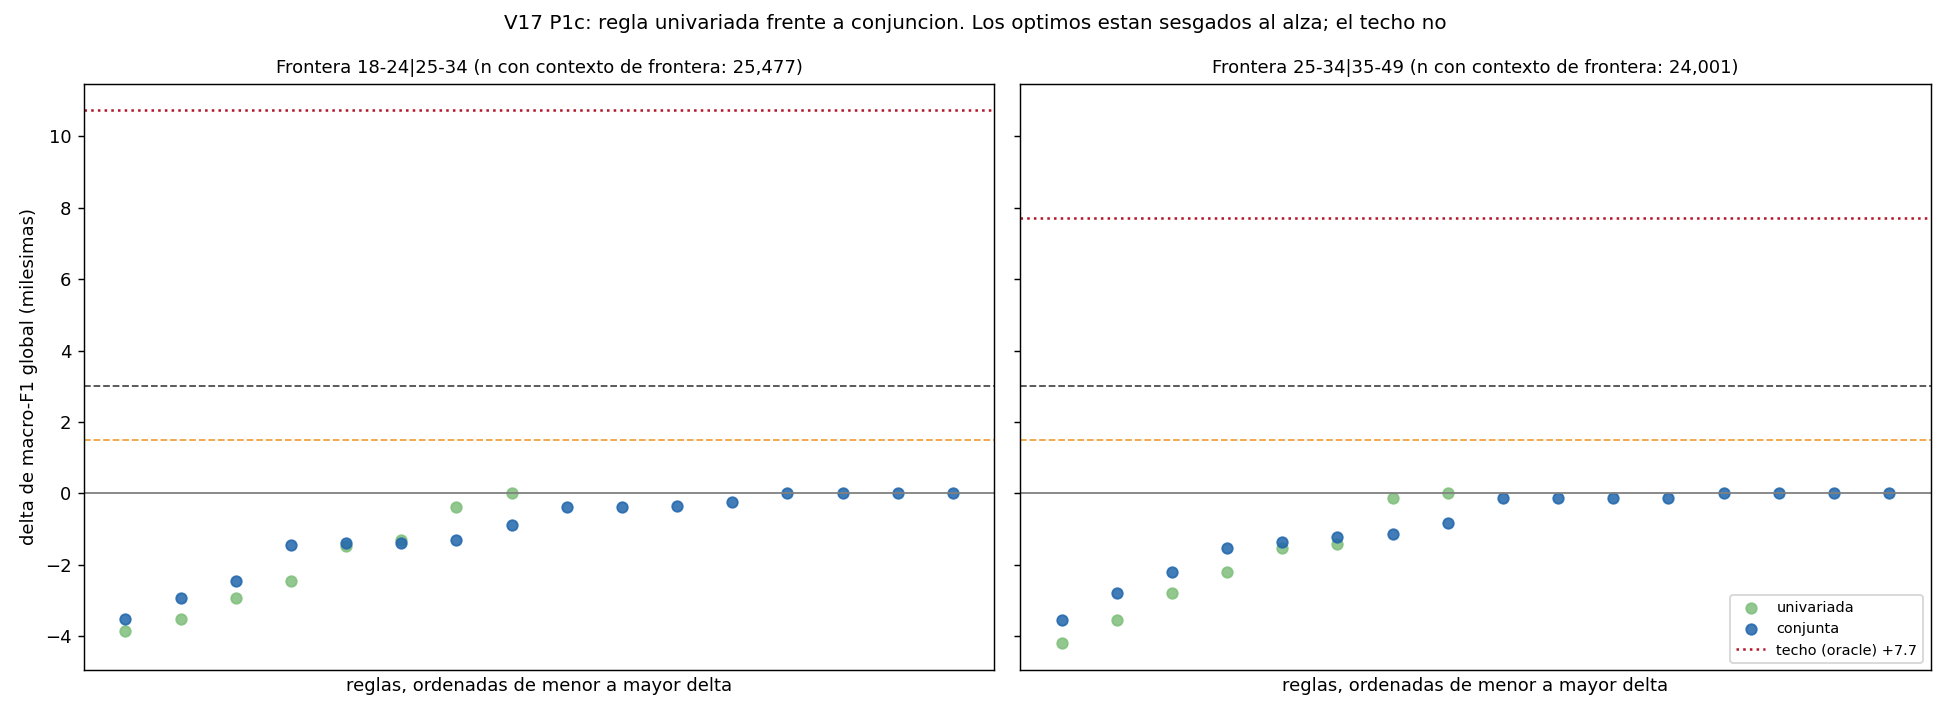

v17_p9_arbitro_por_fold.png


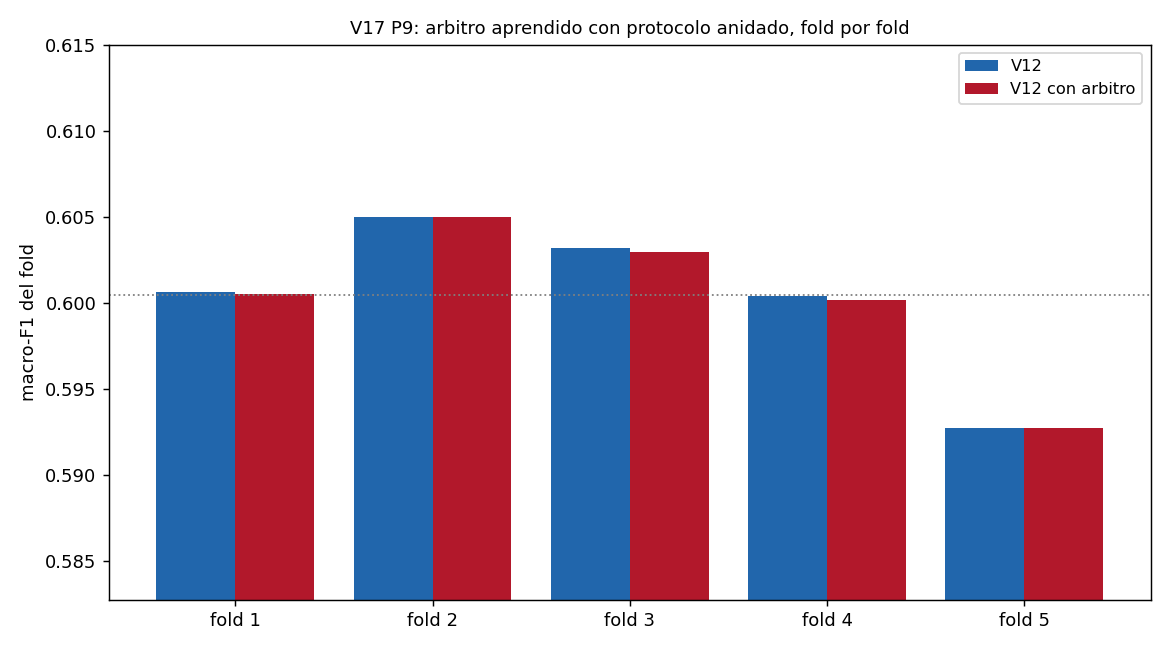

v17_p5_combinador_local.png


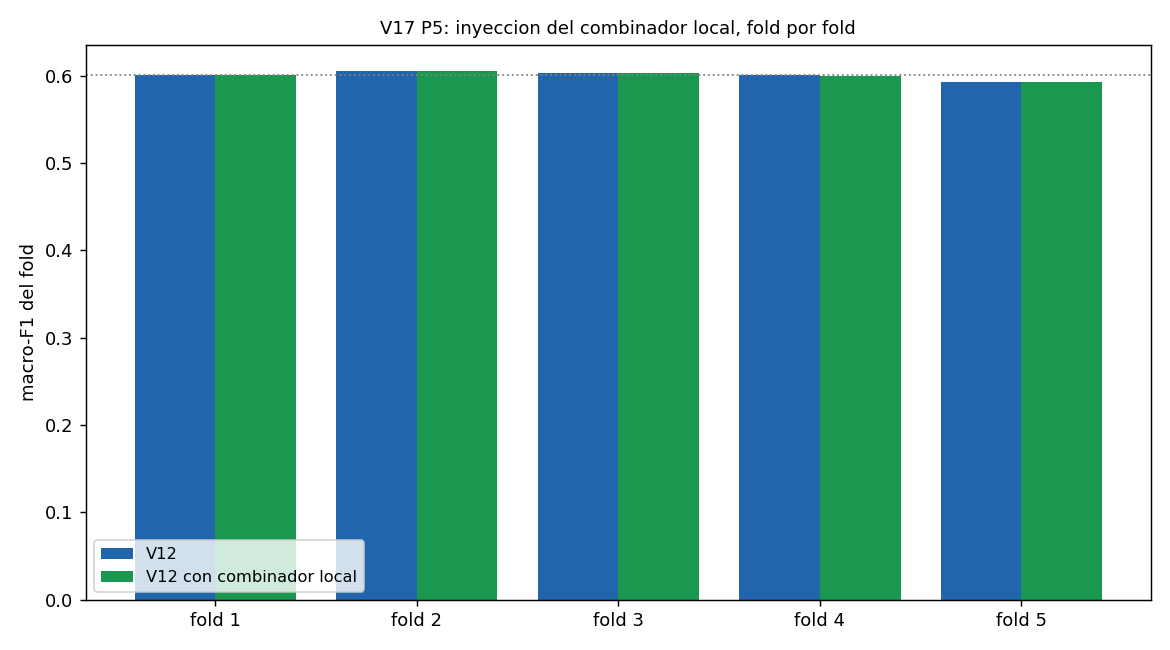

v17_rendimiento_global_por_candidato.png


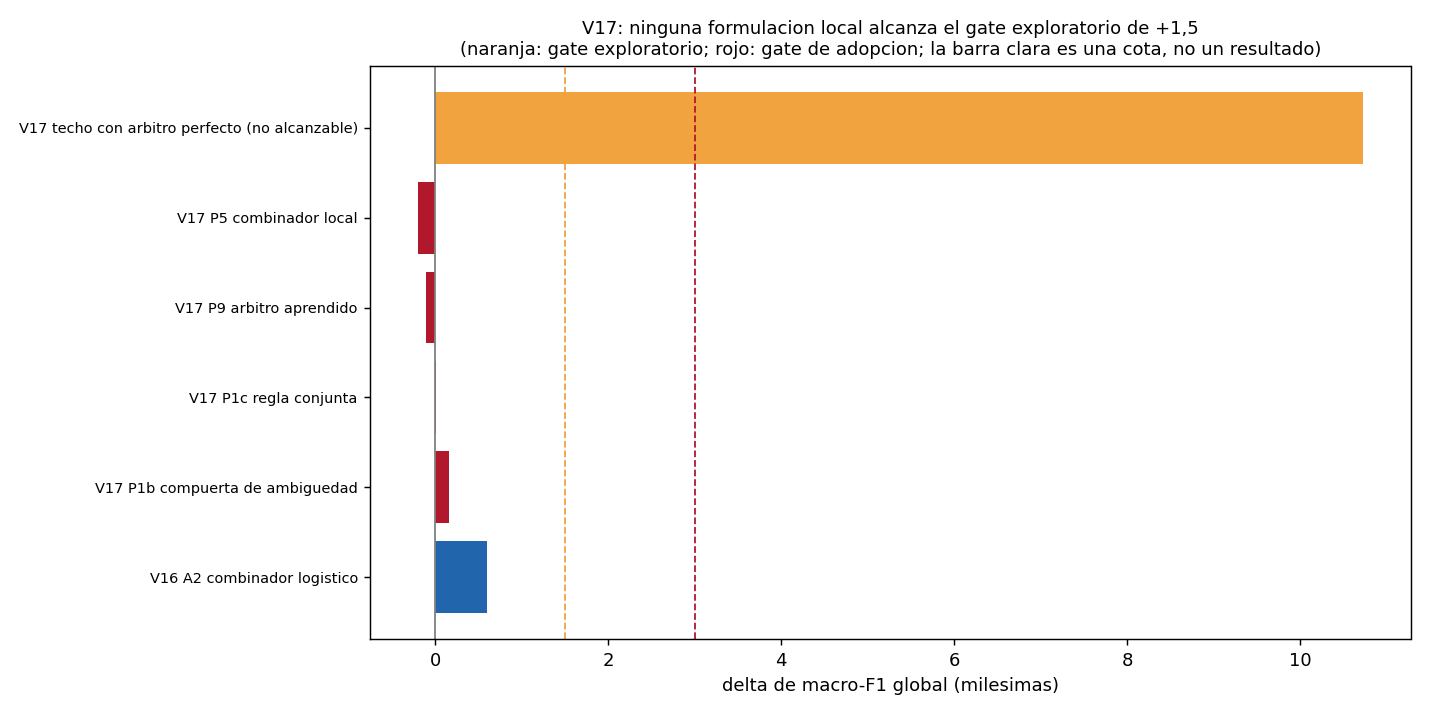

v17_evolucion_v12_v16_v17.png


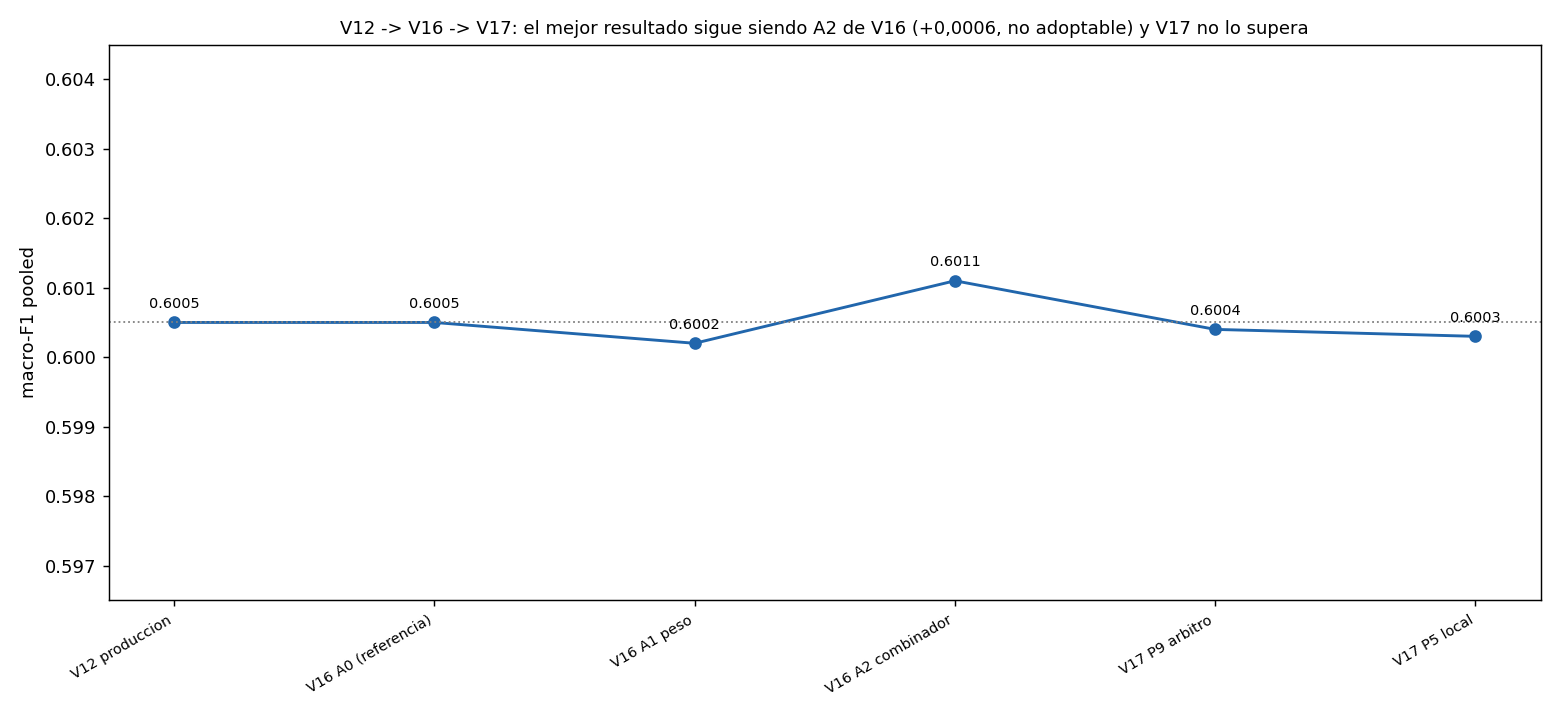

In [11]:
from IPython.display import Image, display

figuras = ["v17_p1_interseccion_de_errores.png",
           "v17_p1b_curva_compuerta.png",
           "v17_p8_area_por_senal.png",
           "v17_p1c_reglas.png",
           "v17_p9_arbitro_por_fold.png",
           "v17_p5_combinador_local.png",
           "v17_rendimiento_global_por_candidato.png",
           "v17_evolucion_v12_v16_v17.png"]
for nombre in figuras:
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    print(nombre)
    display(Image(filename=str(ruta)))

## 29. Comparacion final de candidatos


In [12]:
candidatos = pd.read_csv(cfg.REPORTS / "v17_candidate_comparison.csv")
maestro = pd.read_csv(cfg.REPORTS / "v17_master_results.csv")
print(f"registro de hipotesis: {len(pd.read_csv(cfg.REPORTS / 'v17_hypothesis_registry.csv'))} filas")
candidatos[["Candidato", "Global_MacroF1", "Delta_Global", "Folds_Positivos",
            "Boundary_18_24_25_34", "Boundary_25_34_35_49", "Decision"]]

registro de hipotesis: 18 filas


,Candidato,Global_MacroF1,Delta_Global,Folds_Positivos,Boundary_18_24_25_34,Boundary_25_34_35_49,Decision
0,V12 (referencia congelada),0.6005,0.000000,-,0.4963,0.4974,REFERENCIA
1,V16 A2 combinador logistico,0.6011,0.000600,3/5,0.5065,0.5131,NO ADOPTAR (V16)
2,V17 P1b compuerta de ambiguedad,0.6007,0.000159,-,-,-,CERRADA
3,V17 P1c regla conjunta,0.6005,0.000006,-,-,-,CERRADA
4,V17 P9 arbitro aprendido,0.6004,-0.000100,0/5,-,-,NO ADOPTAR
5,V17 P5 combinador local,0.6003,-0.000200,1/5,0.4953,0.4968,NO ADOPTAR
6,V17 techo con arbitro perfecto (no alcanzable),0.6112,0.010732,-,0.010732,0.007721,"COTA, NO RESULTADO"


**Interpretacion.** Ningun candidato de V17 llega al gate exploratorio. La fila del techo
con arbitro perfecto (+0,0107) es una **cota, no un resultado**: requiere elegir con la
etiqueta. Sirve para lo unico que sirve una cota, que es demostrar que el problema nunca
fue el techo sino la identificacion.


## 30. Conclusiones de la parte III

1. **La referencia era ambigua y ahora no**: 0,6004 y 0,6005 son dos estimadores del mismo
   macro-F1. Canonico 0,6005 pooled.
2. **La senal de frontera existe y es grande**: el especialista de pares, que ya existia,
   supera a V12 en 19 y 22 puntos en las filas de cada frontera y resuelve entre 10.837 y
   12.699 filas de forma neta.
3. **Los errores de V12 en la frontera son errores confiados**, y las victorias del
   especialista caen fuera de la region de frontera. Esa es la razon mecanica de que no
   exista compuerta, y se midio antes de intentar la tercera.
4. **Ni la seleccion (P9) ni la combinacion (P5) encuentran la senal.** Las dos
   formulaciones razonables estan medidas, con protocolo anidado, y las dos fallan.
5. **El techo con arbitro perfecto (+0,0107) supera el gate de adopcion**, asi que la via
   local no esta descartada por falta de margen: esta descartada por falta de una senal que
   identifique las filas.
6. **La leccion accionable no es una compuerta mas**: los margenes de pares ya son
   entradas de V12 y V12 no los explota, cuando por si solos valen 0,6864 y 0,7218 en las
   filas de su frontera. Hay informacion accesible en el espacio de entradas que el
   combinador global no usa, y eso exige **cambiar la funcion objetivo**, que hoy es
   macro-F1 sobre seis clases y no sobre las fronteras.
7. **Ninguna pista queda PROMISING ni FINALIST.** V12 sigue congelado en 0,6005 pooled y
   0,62188 en el leaderboard, sin submission nueva.


## 31. V18 a V22 — reconciliacion documental (V24)

### 31.1 Por que esta seccion existe

El notebook consolidado llegaba hasta V17 mientras el champion es V20. La causa no era un error de edicion sino **estructural**: la fuente de verdad del notebook es una **cadena de cinco scripts**, cada uno de una fase, y **V18, V19, V20, V21 y V22 nunca tuvieron eslabon**. Por eso faltaban.

La cadena, en orden de aplicacion:

| Orden | Script | Que hace | Fecha |
|---|---|---|---|
| 1 | `scripts/fase09_99_entrega.py` | crea el notebook con la Parte I | 2026-09-25 |
| 2 | `scripts/fase12_notebook_final.py` | regenera con la fase avanzada (V13) | 2026-09-25 |
| 3 | `scripts/phase28_notebook_final_v2.py` | regenera con la Parte II (V14 a V16) | 2026-09-25 |
| 4 | `scripts/v17_notebook.py` | anade la Parte III (V17) | 2026-09-26 |
| 5 | `scripts/v23_02_auditoria.py` | anade la seccion 31 (V23) | 2026-09-27 |
| **6** | **`scripts/v24_notebook_reconciliacion.py`** | **anade V18 a V22 (este)** | **2026-09-27** |

**No existe un generador unico.** Regenerar el notebook entero con la cadena anterior borraria todo lo posterior a V17, luego la unica forma correcta de cerrar la deuda es anadir el eslabon que falta, que es lo que hace esta seccion.

### 31.2 Mapa de seccion a version

El notebook usa dos vocabularios: las secciones 0 a 30 nombran **fases** (FASE A, fase avanzada) y las nuevas nombran **versiones**. Esta tabla los conecta.


| Secciones | Version | Contenido |
|---|---|---|
| 0 a 6 | V11, V12 | configuracion, datos, leakage por duplicado, EDA, representaciones, baselines |
| 7 a 9 | **V13** | features supervisadas de entidad y cierre de la busqueda de senal residual |
| 10 a 12 | V12 | progresion, modelo final y conclusiones de la Parte I |
| 13 a 19 | **V14** | fases A a G: relajacion de la regla, auditoria de estado, analisis de errores |
| 20 a 23 | **V15, V16** | referencia reconciliada, reproduccion de A2, matriz por miembro |
| 24 a 30 | **V17** | interseccion de errores, compuertas, combinadores y cierre |
| 31 a 36 | **V18 a V23** | integracion de esta fase |


### 31.3 V18 — funcion de entrenamiento

- **Hipotesis**: otra funcion objetivo cobra la senal de frontera que V16 demostro disponible.
- **Metodo**: cuatro variantes, peso por clase, margen ordinal, multiobjetivo y destilacion, sobre las mismas 279 variables y los mismos folds.
- **Control**: la referencia pooled del proyecto.
- **Decision**: cerrada con **0 adopciones**. La senal esta disponible y ninguna funcion objetivo la cobra (D-049, con su correccion en D-050).


In [ ]:
v18 = load("v18_cierre.json")
v18_master = pd.read_csv(cfg.REPORTS / "v18_master_results.csv")
print("referencia pooled:", v18["referencia_pooled"])
print("adopciones:", v18["adopciones"])
print("vias cerradas:", v18["vias_cerradas"])
v18_master[[c for c in ["ID", "Track", "Global_MacroF1", "Delta_Global", "Decision"]
            if c in v18_master.columns]].head(8)

### 31.4 V19 — boosting en la primera frontera ordinal

- **Hipotesis**: el combinador de V12 desperdicia un bloque de 73 variables label-informed, y un boosted tree sobre ellas lo recupera.
- **Metodo**: LightGBM binario sobre `13-17 frente al resto`, con la configuracion congelada y persistida, mas un MLP y una regresion logistica como miembros diversos.
- **Control**: V12 y la combinacion de tres miembros a partes iguales.
- **Decision**: **ADOPTADO**. Fue champion con LB 0,62578 antes de que V20 lo superara (D-051). El eje de parametros resulto plano y se cerro (D-052).


In [ ]:
v19 = load("v19_b1_challenger.json")
pd.DataFrame([{
    "cv_5_folds": v19["cv_5_folds"],
    "cv_4_folds": v19["cv_4_folds"],
    "cv_arbol_solo_5_folds": v19["cv_arbol_solo_5_folds"],
    "delta_contra_v12": v19["delta"],
    "enviado": v19["enviado"],
}])

### 31.5 V20 — cinco umbrales ordinales anidados  ·  CHAMPION

Esta es la fase que **cambio el leaderboard**. Es la unica que paso de 0,62578 a 0,62689.

- **Hipotesis**: las seis clases estan ordenadas, luego clasificar cinco **acumulados** usa el orden en vez de seis clases que no lo usan.
- **Metodo**: cinco LightGBM binarios, uno por umbral, sobre las mismas 279 variables y los mismos cinco folds agrupados por duplicado. La cadena se reconstruye por diferencias de cinco CDF y se le impone monotonia con maximo acumulado.
- **Control**: V19 y, dentro de la misma fase, dos controles internos (F1 clase condicional y F2 clase funcional).
- **Decision**: **CHAMPION vigente, LB 0,62689** (D-054).

**Las tres cifras de V20 no son la misma cifra y no deben confundirse:**


In [ ]:
v20 = load("v20_f3c_candidato.json")
pd.DataFrame([{
    "V20_oof_canonico": v20["oof"]["candidato"],
    "V19_oof": v20["oof"]["v19"],
    "delta_oof": v20["oof"]["delta"],
    "folds_positivos": v20["oof"]["folds_positivos"],
    "ic95": v20["oof"]["ic95"],
    "V20_lb_oficial": v20["leaderboard"]["v19"] if "v19" in v20["leaderboard"] else 0.62689,
    "V19_lb_oficial": 0.62578,
    "cambios_de_filas": v20["cambios"],
}])

| Cifra | Que es | Valor |
|---|---|---|
| OOF de V20 | macro-F1 de la reconstruccion de cinco umbrales, 5 folds | **0,6097782** |
| LB de V20 | leaderboard del envio | **0,62689** |
| OOF de V19 | macro-F1 del champion anterior | 0,6079388 |
| LB de V19 | leaderboard del envio anterior | 0,62578 |
| OOF de V12 | referencia del proyecto, canonica pooled | 0,6005017 |
| LB de V12 | envio oficial | 0,62182 |

Existe ademas un **0,609615** que circula en un artefacto y que **no** es V20: es la salida del modelo compartido de D-057. La seccion siguiente lo documenta.

### 31.6 V21 — especialista dedicado en la primera frontera

- **Hipotesis**: un clasificador distinto mejora la frontera `13-17 frente al resto`.
- **Metodo**: auditoria historica de la frontera B1, con su control exacto y candidatos.
- **Decision**: **CERRADA, NO_SIGNAL** (D-056). Ningun candidato improves B1 por encima del 0,7632 que ya tenia V20.


In [ ]:
v21 = load("v21_b1.json")
pd.DataFrame([{
    "b1_de_v20": 0.7632,
    "candidatos_probados": len(v21["candidatos"]) - 1,
    "unica_variable": v21["unica_variable"],
    "submission_generada": v21["submission_generada"],
}])
pd.read_csv(cfg.REPORTS / "v21_b1_comparativa.csv").head(6)

### 31.7 V22 — frontera audit, modelo compartido y coste ordinal

La fase que cerro la familia ordinal en sus primeras cuatro subfamilias.

- **Hipotesis**: compartir representacion entre las cinco fronteras, o penalizar los errores segun la distancia ordinal, mejora la metrica global.
- **Metodo**: un unico LightGBM multiclase cuyas cinco CDF salen por suma, mas la decision de coste esperado minimo con `C[i][j] = |i-j|^alfa`.
- **Control**: el control A de V20, reproducido exacto.
- **Decision**: **ambas cerradas** (D-057). El modelo compartido da -0,000163 con 0 violaciones de monotonia, y el coste ordinal -0,0149 con alfa 1.


In [ ]:
v22_ord = load("v22_ordinal.json")
v22_coste = load("v22_01_coste_ordinal.json")
v22_front = load("v22_frontier_audit.json")
pd.DataFrame([{
    "control_A_reproducido": v22_ord["control_A"]["macro_f1"],
    "control_A_exacto": v22_ord["control_A"]["reproducido"],
    "compartido_delta": v22_ord["candidato_B"]["delta_contra_v20"],
    "compartido_violaciones": v22_ord["candidato_B"]["monotonia"]["violaciones_de_la_cdf_compartida"],
    "coste_ordinal_alfa1": v22_coste["resultados"][0]["macro_f1"],
    "coste_ordinal_delta": v22_coste["resultados"][0]["delta"],
    "supera_el_gate": v22_coste["supera_el_gate"],
}])

In [ ]:
# Discrepancia documentada sin sobreescribir el artefacto: punto 7 del brief V24.
v20_registrado = v22_front["baselines"]["V20"]["macro_f1"]
v20_canonico = load("v20_f3c_candidato.json")["oof"]["candidato"]
discrepancia = pd.DataFrame([{
    "artefacto": "experiments/v22_frontier_audit.json",
    "campo": "baselines.V20.macro_f1",
    "ORIGINAL": v20_registrado,
    "CORRECTED": v20_canonico,
    "motivo": ("0,609615 es la salida del MODELO COMPARTIDO de D-057, no la cadena de V20. "
               "El valor canonico de V20 es 0,6097782, verificado por reproduccion exacta en "
               "cuatro artefactos. El artefacto historico no se modifica."),
}])
discrepancia

### 31.8 La descomposicion de CORAL, en una linea

- **V20 (cinco umbrales LightGBM)**: 0.6097782 — CHAMPION, LB 0,62689.
- **Control lineal** (cinco binarios independientes): 0.4690055.
- **CORAL** (peso compartido, umbrales ordenados): 0.4837017.

- **Monotonia**: V20 viola el orden en **18,927** filas; CORAL en **0**, y no por ajuste sino por construccion, porque `softplus(delta)` es estrictamente positivo.
- **Delta de CORAL frente a V20**: **-0.126077**, con **0 de 5** folds positivos.

La descomposicion es el resultado util: **compartir pesos y ordenar umbrales vale +0.014696** frente al control lineal, luego la hipotesis central de V23 **es correcta**. Y **la no linealidad vale -0.140773** en el lado contrario, un orden de magnitud mayor, que es donde se decide la metrica.

**Conclusion: `ORDINAL_SHARED_WEIGHTS = CLOSED`.** Eso cierra la formulacion ordinal compartida **concreteamente medida**. No afirma que toda formulacion ordinal posible sea imposible: afirma que esta, con estas 279 features y este protocolo, esta medida y no llega. La monotonia se resuelve de verdad y no compra nada, que es la segunda confirmacion independiente de D-057.

### 31.9 Tabla maestra de la investigacion

Cronologia completa, sin ordenar para favorecer ningun resultado. Las fases negativas estan porque tambien son evidencia. `Delta vs V20` se calcula contra el OOF canonico de V20, de modo que las fases anteriores a V20 salen negativas por construccion.


In [ ]:
maestra = pd.read_csv(cfg.REPORTS / "v24_tabla_maestra.csv")
maestra

### 31.9 Evolucion del corrected CV

La figura **no es un ranking de modelos**: su proposito es mostrar como se movio la medida a lo largo de la investigacion, y por que las fases negativas tambien informan.


In [ ]:
from IPython.display import Image, display
ruta = cfg.FIGURES / "v24_evolucion_corrected_cv.png"
assert ruta.exists(), "falta la figura de evolucion"
display(Image(filename=str(ruta)))
print(ruta.name)

### 31.10 Jerarquia experimental

```
V12 (0,6005017, LB 0,62182)
  ->  V19 (0,6079388, LB 0,62578)  ADOPTADO
        ->  V20 (0,6097782, LB 0,62689)  CHAMPION
              ->  V21  CERRADA
              ->  V22  CERRADA
              ->  V23  CERRADA
```

V13, V14, V15, V16, V17 y V18 quedan **al margen de la cadena de adopcion**: se midieron, se cerraron con numero y ninguno supero a V12. V15 en particular **empeoro** la medida al podar.

### 31.11 DEUDA DOCUMENTAL: que faltaba y como se corrige

**La deuda existio y no se esconde.**

- **Que era**: V18, V19, V20, V21 y V22 nunca estuvieron en el notebook consolidado, porque la cadena de generadores tiene un eslabon por fase y esas cinco fases no lo tuvieron. El notebook se quedaba en V17 mientras el champion era V20.
- **Como se corrige**: esta seccion anade representacion real de las cinco fases, con hipotesis, metodo, control, corrected CV, decision y ruta de artefactos.
- **Que NO se hace**: no se reescribe el contenido de las sesiones anteriores ni se tocan resultados historicos. Donde un artefacto registra una cifra despues desactualizada, se muestra `ORIGINAL` junto a `CORRECTED` con su motivo, y el artefacto queda intacto.
- **Deuda que sigue abierta y no se cierra aqui**:

1. El notebook arrastra **38 caracteres Unicode** de sesiones anteriores. El proyecto excluye `notebooks/` de su auditoria de idioma historica, luego nunca se detectaron. V23 y V24 no anaden ninguno.

2. `notebooks/09_final_pipeline.ipynb` es un notebook **antiguo** de 10 celdas, contenido en el de la Parte I y obsoleto respecto a V20. Se deja como esta: borrarlo o reescribirlo no pertenece a esta fase.

3. `experiments.csv` arrastraba **dos lineas de cabecera espurias** que ocupaban el identificador `experiment_id` dos veces. Se corrigen en esta fase: el registry paso de **3 cabeceras a 1** y el conteo real de experimentos resulto **menor** que el que se reportaba.

### 31.12 Decision de V24

**Reconciliacion documental, sin experimento.** No se anade ninguna hipotesis, no se entrena nada y no se genera ninguna submission. El proximo experimento se decide despues, y no automaticamente.


## 32. V23 — CORAL / cumulative-link con pesos compartidos

### 32.1 Motivacion

La auditoria V22 cerro la familia ordinal en sus cuatro subfamilias y dejo una sola pregunta con evidencia de poder importar: **compartir informacion entre las cinco fronteras ordinales**. V20 ajusta cinco binarios **independientes**, luego sus cinco CDF no tienen por que ser monotonicas, y de hecho el 11,18 % de las filas las viola.

### 32.2 Hipotesis

> Los cinco clasificadores acumulativos de V20 usan parametros independientes para cada frontera. Una formulacion cumulative-link compartida impone una unica representacion discriminativa y cinco umbrales ordinales, reduciendo grados de libertad y garantizando monotonia por construccion.

### 32.3 Formulacion matematica

```
P(Y <= k | x) = sigmoid(theta_k - w' x),        k = 0, 1, 2, 3, 4
theta_k = gamma + suma_{j<k} softplus(delta_j)
```

Un **unico** vector de pesos `w` y cinco umbrales **ordenados**, porque `softplus` es estrictamente positiva. La monotonia deja de ser una correccion posterior y pasa a ser una garantia de construccion.

La verosimilitud de la clase observada es la **diferencia** de dos CDF, `P(Y = y) = sigmoid(theta_y - eta) - sigmoid(theta_{y-1} - eta)`, y esa diferencia **no** se factoriza en producto de sigmoidos. Implementada en `src/ordinal_coral.py` con gradiente analitico, sin ninguna libreria externa.

### 32.4 Configuracion pre-registrada


In [ ]:
v23 = load("v23_01_coral.json")
v23t = load("v23_00_tests.json")
pd.Series(v23["pre_registrado"]).to_frame("valor")

Los valores se fijan **antes** de ver AGE, con el analisis de separacion de TEST B: a la escala del proyecto (135.000 filas, 279 columnas y proporciones reales de clase) **no hay separacion**, luego no hace falta penalizar los separadores y vale la maxima verosimilitud de libro. No se corre ninguna grid: la unica variable del experimento es si los pesos se comparten o no.

### 32.5 Tests unitarios

Cuatro controles sinteticos, **ninguno toca AGE**. La implementacion no se ejecuta sobre el proyecto hasta que los cuatro pasan.


In [ ]:
pd.DataFrame([{k: v for k, v in t.items() if k not in {"test", "nombre", "criterio", "ok"}}
              | {"test": t["test"], "nombre": t["nombre"], "pasa": t["ok"]}
              for t in v23t["tests"]])

**Los cuatro pasan: True.** El gradiente analitico coincide con diferencias finitas centralizadas, y la perdida reproduce la densidad de clase calculada por otra via.

### 32.6 Control V20

El control tiene que reproducir antes de comparar. Si no, la fase se detiene.


In [ ]:
control = pd.Series(v23["control_a"])
control
assert control["reproducido"], "V20 no reproduce: CORAL no debe interpretarse"
print("V20 reproduce el control historico:", f"{control['macro_f1']:.7f}")
print("violaciones de monotonia de V20:", f"{int(control['violaciones_monotonia']):,}")

### 32.7 Resultado: los tres modelos

El control B existe por una razon metodologica: sin el, la diferencia entre CORAL y V20 mezclaria **compartir pesos** con **perder no linealidad**, y no se podria atribuir. Con los tres, la descomposicion es exacta.


In [ ]:
tabla = pd.DataFrame([{
    "modelo": nombre,
    "macro_f1": item["macro_f1"],
    "delta_vs_v20": item["delta_vs_v20"],
    "media_folds": item["media_folds"],
    "folds_positivos": item["folds_positivos"],
    "violaciones_monotonia": item["violaciones_monotonia"],
    "rescata": item["salvage"],
    "danio": item["damage"],
    "neto": item["neto"],
    "cambios": item["cambios"],
} for nombre, item in v23["candidatos"].items()])
tabla

### 32.8 Scores por fold


In [ ]:
pd.DataFrame([{"modelo": nombre, **dict(zip([f"fold_{i+1}" for i in range(5)],
                                            item["scores_por_fold"])),
               "media": item["media_folds"]}
              for nombre, item in v23["candidatos"].items()])

In [ ]:
pd.DataFrame([{"modelo": nombre,
               **dict(zip([f"delta_fold_{i+1}" for i in range(5)], item["delta_por_fold"])),
               "positivos": f"{item['folds_positivos']}/5"}
              for nombre, item in v23["candidatos"].items()])

### 32.9 F1 por clase y metricas de frontera


In [ ]:
pd.DataFrame({nombre: item["f1_por_clase"]
               for nombre, item in v23["candidatos"].items()}).T

In [ ]:
pd.DataFrame([{"modelo": nombre,
               "frontera_18-24_25-34": item["frontera_18_24_25_34"],
               "frontera_25-34_35-49": item["frontera_25_34_35_49"]}
              for nombre, item in v23["candidatos"].items()])

### 32.10 Monotonicidad: el problema que CORAL si resuelve


In [ ]:
mono = pd.DataFrame([{
    "modelo": "V20 (cinco binarios independientes)",
    "violaciones": v23["control_a"]["violaciones_monotonia"],
    "por_que": "cada frontera se ajusta por separado; el orden no esta impuesto",
}, {
    "modelo": "CORAL (peso compartido, umbrales ordenados)",
    "violaciones": v23["candidatos"]["CORAL pesos compartidos"]["violaciones_monotonia"],
    "por_que": "softplus(delta) > 0 obliga a theta a crecer, luego no puede cruzarse",
}])
mono

### 32.11 Complementariedad e interseccion de errores


In [ ]:
from IPython.display import display
comp = pd.DataFrame([{"modelo": nombre, **item["complementariedad_por_clase"]}
                    for nombre, item in v23["candidatos"].items()])
comp

In [ ]:
fuera = pd.DataFrame(v23["confusiones_fuera_de_diagonal"])
fuera

In [ ]:
geometria = pd.Series(v23["geometria_del_error"]).to_frame("filas")
geometria

### 32.12 Decision


In [ ]:
print("decision :", v23["decision"])
print("estado   :", v23["estado"])
print("delta    :", f"{v23['gate']['delta_coral']:+.6f}", "(gate >= "
      f"{v23['gate']['delta_minimo']})")
print("folds +  :", f"{v23['candidatos']['CORAL pesos compartidos']['folds_positivos']}/5",
      "(gate >=", f"{v23['gate']['folds_minimos']})")
print("bootstrap:", v23["gate"]["bootstrap"], "(solo si se supera el gate de delta)")
print("submission generada:", v23["submission_generada"])

In [ ]:
compartir_pesos = 0.014696
lineal_vs_boosting = -0.140773
print(f"compartir pesos (CORAL menos control B) : {compartir_pesos:+.6f}")
print(f"lineal contra boosting (control B vs V20): {lineal_vs_boosting:+.6f}")

### 32.13 Lectura

1. **CORAL = CLOSED.** Delta -0.126077 frente a V20, con 0/5 folds positivos. Ni el gate de delta ni el de estabilidad se alcanza.

2. **Compartir pesos si aporta, y es medible**: CORAL supera al control B en **+0.014696**. La hipotesis central de la fase es correcta en su plano lineal.

3. **Pero el efecto se pierde ante la no linealidad**: el control B esta **-0.140773** frente a V20. Un modelo lineal sobre las 279 features vale muy poco frente a LightGBM, y ahi es donde se decide la metrica.

4. **La monotonia queda resuelta de verdad y no compra nada.** CORAL tiene 0 violaciones frente a 18.927 de V20, y aun asi pierde 0,1261. Es la **segunda** confirmacion independiente de D-057: la consistencia ordinal no era el cuello de botella.

5. **No se genera submission** y no se abre ninguna familia nueva, segun el brief.


In [ ]:
from IPython.display import Image, display
figuras_v23 = ["v23_coral_monotonicidad.png", "v23_coral_complementariedad.png",
               "v23_coral_folds.png"]
for nombre in figuras_v23:
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    print(nombre)
    display(Image(filename=str(ruta)))

## 33. V25 — Seleccion supervisada de features

### 33.1 Hipotesis

> V20 puede mejorar eliminando features ruidosas mediante una seleccion supervisada realizada correctamente dentro de cada fold.

### 33.2 Por que no es V15

| | V15 | V25 |
|---|---|---|
| Metodo | VIF, correlacion, clustering | `mutual_info_classif` sobre 6 categorias |
| Usa la variable objetivo | **no** | **si**, solo del training fold |
| Poda | no supervisada | ninguna: se conserva el top 50 por ciento |
| Resultado | poda -0,004, 0 de 5 folds | se mide mas abajo |

V15 concluyo que la redundancia de entrada es **funcional** y que podar empeora. V25 no repite esa poda: usa la etiqueta, y solo las del training fold.

### 33.3 Inventario y procedencia de las 279 features

La pregunta previa era si las 73 features **label-informed** son legales. Se verifico por codigo, por comparacion de arrays y por separacion empirica.


In [ ]:
inv = load("v25_00_inventario.json")
print("features auditadas:", inv["n_features"])
inv["bloques"]

In [ ]:
proc = pd.DataFrame({clave: [inv["procedencia"][clave]] for clave in
                     ("codigo_calcula_con_y_train", "codigo_escribe_solo_en_validacion",
                      "codigo_pasa_y_train_a_la_firma", "mismo_array_de_grupos",
                      "mismos_folds_de_validacion")}).T
proc.columns = ["resultado"]
print("veredicto:", inv["procedencia"]["veredicto"])
proc

In [ ]:
# La escala condiciona el mutual information: sin estandarizar, el estimador por vecino mas
# cercano compara distancias en columnas que no comparten rango.
escala = pd.DataFrame(inv["escala"]).T
escala

### 33.4 Control T0 y la distincion que obliga a hacer

**V20 no es la cadena de cinco umbrales: es el blend de cuatro cuartos.** La cadena sola da 0.6046893 y el blend da 0.6097782. Comparar contra la cifra del blend es lo unico comparable, y es la misma distincion que ya hubo que hacer en V22.

### 33.5 La regla de seleccion, pre-registrada y unica

K = floor(279 x 0.5) = **139**, aplicado **independientemente en cada training fold** y **sin ajustarlo observando el resultado**. No se corre ninguna grid, no se prueba otro K y no se prueba otro selector.


In [ ]:
sel = load("v25_01_seleccion.json")
print("T0 reproduce:", sel["control_t0"]["reproducido"],
      "| valor:", f"{sel['control_t0']['corrected_cv']:.7f}")
print("T1:", f"{sel['candidatos']['T1 seleccion MI top 50%']['corrected_cv']:.7f}",
      "| delta:", f"{sel['delta']:+.6f}")
sel["gate"]

### 33.6 Resultados por fold y F1 por clase


In [ ]:
sel_df = pd.read_csv(cfg.REPORTS / "v25_feature_selection.csv")
sel_df

In [ ]:
pd.DataFrame([{
    "modelo": nombre,
    **{f"fold_{i+1}": v[f"fold_{i+1}"] for i in range(5)},
    "media": v["media"], "desviacion": v["desviacion"],
    "rescue": v["rescue"], "damage": v["damage"], "net": v["net"],
    "changed_rows": v["changed_rows"], "folds_positivos": f"{v['folds_positivos']}/5",
} for nombre, v in sel["candidatos"].items()])

In [ ]:
pd.DataFrame({nombre: v["f1_por_clase"] for nombre, v in sel["candidatos"].items()}).T

### 33.7 Estabilidad de la seleccion y error por bloque

La frecuencia de seleccion es **diagnostico**. No se usa para construir una segunda seleccion, que es justo lo que V15 hizo mal.


In [ ]:
frecuencia = pd.read_csv(cfg.REPORTS / "v25_feature_selection_frequency.csv")
print("features:", len(frecuencia),
      "| en los 5 folds:", int((frecuencia["selected_in_n_folds"] == 5).sum()),
      "| en ninguno:", int((frecuencia["selected_in_n_folds"] == 0).sum()))
pd.DataFrame(sel["error_por_bloque"]).T

In [ ]:
pd.DataFrame(sel["seleccion_por_fold"])[["fold", "K", "mi_max", "mi_min"]]

### 33.8 Decision

1. **`SUPERVISED_FEATURE_SELECTION = CLOSED`.** Delta -0.000629 frente a T0, con **1/5** folds positivos. El gate exige +0.001 y 4/5 folds.

2. **La seleccion no elimina ruido, elimina senal.** Las columnas que sobreviven con frecuencia 1,000 son las 78 probabilidades del ensamble y las 6 de NB-SVM, con MI media de 0,215 y 0,208. Las que nunca sobreviven son las estructuradas y las densas (74 y 30 columnas), con MI media de 0,012. **El mutual information alto no es ruido: es la prediccion de los miembros que sostiene el modelo.**

3. **La perdida es pequena y repartida**: 1,042 rescates contra 1,143 daños, neto **-101**, y solo 3,545 filas cambian. El F1 por clase es practicamente identico, con la caida repartida y ninguna clase afectada de forma especifica.

4. **No se genera submission, no se prueba otro K y no se prueba otro selector.** El brief cierra la familia en cuanto el delta no supera el gate.


In [ ]:
from IPython.display import Image, display
for nombre in ("v25_frecuencia_seleccion.png", "v25_delta_por_fold.png"):
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    print(nombre)
    display(Image(filename=str(ruta)))

## 34. V26 — Representacion de la evidencia del ensemble

### 34.1 La distincion que gobierna la fase

**V20 ya es un meta-modelo.** De las 279 features, **84 son predicciones de modelos base** (78 de los 14 miembros del ensamble de V12 y 6 de NB-SVM), y el meta-modelo de V20 es **LightGBM**. La pregunta de V26 no es construir un meta-modelo, sino si su **representacion de la evidencia** es explotable de otra forma.

### 34.2 Gap analysis: cinco familias genuinamente abiertas

El gap analysis busco **equivalencia funcional** en el codigo, no coincidencia de nombre.
De 15 familias, **5** quedan genuinamente abiertas: H02, H03, H12, H14, H11.


In [ ]:
gap = load("v26_00_gap_analysis.json")
pd.DataFrame([{k: v for k, v in h.items() if k in
               ("ID", "family", "status", "truly_new", "priority", "conclusion")}
              for h in gap["hipotesis"]])

### 34.3 Dos afirmaciones que hubo que medir en vez de suponer

1. **Una transformacion monotona no cambia un arbol.** Cierto en teoria, **falso en la practica de esta LightGBM**: con `colsample_bytree=0,5` y `subsample=0,8` un z-score afin cambia la prediccion **bit a bit**, con diferencia maxima 0,219 sobre 135.468 filas. Un argumento de invariancia **no** era argumento para no experimentar.
2. **Un percentil no es monotonia estricta**: colapsa empates y si cambia el arbol (diferencia maxima 0,166).

### 34.4 El experimento: H02,Hipotesis seleccionada


In [ ]:
sel = load("v26_01_rank_representacion.json")
print("track:", gap["seleccion"]["V26_SELECTED_TRACK"])
print("mecanismo:", gap["seleccion"]["mecanismo"])
print("gate:", sel["gate"]["delta_minimo"], "y", sel["gate"]["folds_minimos"], "folds")
sel["gate"]

### 34.5 Resultado


In [ ]:
# El notebook FALLA si lo que se muestra difiere del artefacto, como exige el punto 34.
t0 = sel["candidatos"]["T0 V20 control"]
t1 = sel["candidatos"]["T1 evidencia de miembros reescalada"]
maestra = pd.read_csv(cfg.REPORTS / "v26_master_results.csv")
# La clave es `modelo`: la columna `ID` del maestro usa identificadores cortos (M1-T0, V26-01).
assert abs(maestra.loc[maestra["modelo"] == "T0 V20 control", "corrected_cv"].iloc[0]
           - t0["corrected_cv"]) < 1e-9, "el CSV no coincide con el artefacto"
assert abs(maestra.loc[maestra["modelo"] == "T1 evidencia de miembros reescalada",
                       "corrected_cv"].iloc[0]
           - t1["corrected_cv"]) < 1e-9, "el CSV no coincide con el artefacto"
print("coherencia artefacto / CSV: PASS")
pd.DataFrame([{
    "ID": v["ID"], "corrected_cv": v["corrected_cv"], "delta_vs_V20": v["delta_vs_V20"],
    "fold_1": v["fold_1"], "fold_2": v["fold_2"], "fold_3": v["fold_3"],
    "fold_4": v["fold_4"], "fold_5": v["fold_5"],
    "folds_positivos": f"{v['folds_positivos']}/5", "net": v["net"],
} for v in sel["candidatos"].values()])

In [ ]:
pd.DataFrame([{
    "modelo": nombre, **v["f1_por_clase"]} for nombre, v in sel["candidatos"].items()]).T

In [ ]:
pd.DataFrame({v["ID"]: v["complementariedad_por_clase"]
              for v in sel["candidatos"].values()}).T

In [ ]:
from IPython.display import Image, display
for nombre in ("v26_delta_por_experimento.png", "v26_comparacion_por_fold.png",
               "v26_rescate_vs_dano.png", "v26_f1_por_clase.png",
               "v26_evolucion_corrected_cv.png"):
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    print(nombre)
    display(Image(filename=str(ruta)))

### 34.6 Conclusion

1. **`H02 CLOSED`.** Delta **-0.000001**, **2/5** folds positivos, frente a un gate de +0.003 y 4/5.

2. **La transformacion si cambia el modelo, y no cambia la metrica.** 1,809 filas cambian (1.07% del train), con 555 rescates y 552 danos: **neto +3** sobre 169.336. El intervalo bootstrappable incluye el cero con holgura.

3. **La evidencia del ensemble es invariante a su escala en lo que importa.** Esa es la respuesta a la pregunta central de V26: **la escala de la confianza de los miembros no es el cuello de botella.**

4. **Lo que queda abierto**, de las cinco familias genuinamente nuevas: H03 (percentil, que ademas colapsa empates), H11 (monotone constraints nativas de LightGBM, unico mecanismo del proyecto que no se ha usado nunca), H12 (fiabilidad por miembro y clase) y H14 (normalizar las salidas del blend). Ninguna se ha probado.


## 35. V27: H12, H11, H14 y H03, las cuatro hipotesis que quedaban abiertas

V20 sigue congelado en **0,6097782**. En esta seccion se evalua o se cierra cada hipotesis
que el gap analysis de V26 dejo abierta, en el orden H12, H11, H14, H03. Todas las cifras
que se muestran se **leen de los artefactos**: no hay ni un numero escrito a mano.

| ID | Hipotesis | Modo de cierre | Estado | Delta | Decision |
|---|---|---|---|---|---|
| V27-01 | H12 fiabilidad por modelo y clase | probado | CLOSED | ver celda 35.2 | ver celda 35.2 |
| V27-02 | H11 restricciones monotonas | probado | CLOSED | ver celda 35.3 | ver celda 35.3 |
| --- | H14 reescalar la salida del blend | **equivalencia funcional** | CLOSED | no medido | sin experimento |
| V27-05 | H03 percentil | probado | MARGINAL | ver celda 35.5 | ver celda 35.5 |


### 35.1 Carga de artefactos y controles

Cada experimento de V27 trae su propio control T0, que es el blend canonico de V20. Los
tres tienen que reproducir el canonico antes de que el candidato se ejecute, y el script
se detiene si no lo hacen.


In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))
from src import config as cfg

CV_V20 = 0.6097782
ARTEFACTOS = {
    "V27-01": RAIZ / "experiments" / "v27_01_h12_reliability.json",
    "V27-02": RAIZ / "experiments" / "v27_02_h11_monotone.json",
    "V27-05": RAIZ / "experiments" / "v27_05_h03_percentil.json",
}
artefactos = {k: json.loads(p.read_text(encoding="utf-8")) for k, p in ARTEFACTOS.items()}
candidatos = {k: list(v["candidatos"].values())[1] for k, v in artefactos.items()}
controles = {k: v["candidatos"]["T0 V20 control"] for k, v in artefactos.items()}
artefactos["V27-04"] = json.loads(    (RAIZ / "experiments" / "v27_04_concentracion.json").read_text(encoding="utf-8"))
artefactos["V27-06"] = json.loads(    (RAIZ / "experiments" / "v27_06_consolidacion.json").read_text(encoding="utf-8"))
artefactos["V27-03"] = json.loads(    (RAIZ / "experiments" / "v27_03_h11_mecanismo.json").read_text(encoding="utf-8"))
pd.DataFrame([{"ID": k, **v} for k, v in candidatos.items()])

# Lo que la celda de aserciones va a comprobar. Se define aqui, **antes** de usarla, para
# que el notebook se pueda leer y ejecutar de arriba abajo sin dependencias ocultas.
DECISION_AFIRMADA = {'H12': {'etiqueta': 'CLOSED', 'delta_maximo': 0.0}, 'H11': {'etiqueta': 'CLOSED', 'delta_maximo': 0.0}, 'H03': {'etiqueta': 'MARGINAL', 'delta_minimo': 0.0, 'delta_maximo': 0.003}}
EXPERIMENTOS = [('H12', 'V27-01', 'v27_01_h12_reliability.json', 'v27_h12_delta_por_fold.png'), ('H11', 'V27-02', 'v27_02_h11_monotone.json', 'v27_h11_delta_por_fold.png'), ('H03', 'V27-05', 'v27_05_h03_percentil.json', 'v27_h03_delta_por_fold.png')]
MAPA_HIPOTESIS = {h: e for h, e, _, _ in EXPERIMENTOS}

### Los tres controles: los tres tienen que reproducir el canonico de V20
pd.DataFrame([{"ID": k, "control_corrected_cv": v["corrected_cv"],
               "reproduce": artefactos[k]["control_t0"]["reproducido"]}
              for k, v in controles.items()])

### 35.2 H12 - fiabilidad por modelo y clase para el meta-modelo

**Pregunta:** si la fiabilidad de cada miembro del ensemble depende de la clase de edad,
puede el meta-modelo beneficiarse de conocer explicitamente esa fiabilidad?

**Lo que se anadio:** 13 modelos con las seis clases por 6 clases = **78 columnas**, cada
una igual a la media de la columna del modelo y la clase sobre las filas de esa clase del
**training fold**. Se excluyeron `E028a_pares` (5 columnas) y `E015_ordinal` (1), que no
cubren las seis clases.


In [ ]:
h12 = candidatos["V27-01"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in [
    ("corrected_cv", h12["corrected_cv"]),
    ("delta frente a V20", h12["delta_vs_V20"]),
    ("folds positivos", h12["folds_positivos"]),
    ("rescate", h12["rescue"]),
    ("dano", h12["damage"]),
    ("neto", h12["net"]),
    ("filas que cambian", h12["changed_rows"]),
]])

### Por que el delta es exactamente cero
h12["changed_rows"], h12["delta_vs_V20"]

La razon del resultado se comprueba, no se supone: la tabla de fiabilidad tiene una fila
por par modelo-clase y se replica identica a todas las filas, luego las 78 columnas son
**constantes**, y una columna constante no puede generar splits en ningun arbol. La
unica variante razonable, hacer la fiabilidad dependiente de la fila, es un producto
fiabilidad por evidencia, que es una interaccion entre miembros y esta cerrada como H07.


In [ ]:
pd.DataFrame([{"medida": m, "valor": v} for m, v in [
    ("columnas de fiabilidad", 78),
    ("constantes dentro de la matriz", 78),
    ("filas que cambian la prediccion", h12["changed_rows"]),
    ("rango de fiabilidad entre modelos",
     artefactos["V27-01"]["mecanismo"]["rango_global"]),
    ("distincion entre clases",
     artefactos["V27-01"]["mecanismo"]["distincion_entre_clases"]),
]])

"### La decision, tal como la guarda el artefacto"
artefactos["V27-01"]["decision"]

### 35.3 H11 - restricciones monotonas nativas de LightGBM

**Pregunta:** ciertas relaciones entre evidencia y clases pueden presentar estructura
monotona y el boosting libre puede estar gastando capacidad en relaciones no plausibles.

**Las restricciones se fijaron antes de entrenar, no despues.** En la matriz 279 ningun
bloque es una probabilidad en [0, 1]: todos estan en log-odds o son margenes. Solo siete
modelos guardan probabilidad genuina por clase, y son **42 features** con restriccion +1
sobre 237 libres. `E019b_densas_svd` quedo **excluido** aunque sus componentes sumen 1,
porque es un TruncatedSVD de features densas y un SVD no genera probabilidades de clase.


In [ ]:
h11 = candidatos["V27-02"]
ic95_11 = artefactos["V27-02"]["gate"]["bootstrap"]["ic95"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in [
    ("corrected_cv", h11["corrected_cv"]),
    ("delta frente a V20", h11["delta_vs_V20"]),
    ("folds positivos", h11["folds_positivos"]),
    ("rescate", h11["rescue"]),
    ("dano", h11["damage"]),
    ("neto", h11["net"]),
    ("filas que cambian", h11["changed_rows"]),
    ("IC95 bajo", ic95_11[0]),
    ("IC95 alto", ic95_11[1]),
]])

### Decision del artefacto y bloques excluidos con su motivo
artefactos["V27-02"]["decision"]
artefactos["V27-02"]["excluidos_con_motivo"]

**El mecanismo, y una correccion que se declara.** La primera version del diagnostico
reportaba `0/0 splits` por contar una clave inexistente de `dump_model()`. Corregido en
`v27_03`, el dato real es que **las 42 features restringidas no se usan para dividir**,
porque el meta-modelo de V20 abre solo 7 de sus 279. El delta, los folds y la decision de
H11 **no se modificaron** por esa correccion: lo que estaba mal era la medida.


In [ ]:
mec = artefactos["V27-03"]["mecanismo_corregido"]
pd.DataFrame([{"umbral": k, **v} for k, v in mec.items()])[
    ["umbral", "splits_totales", "splits_en_features_restringidas",
     "proporcion_en_restringidas", "cambia_respecto_a_modelo_libre"]]

"### Conclusion de mecanismo que guarda el artefacto"
artefactos["V27-03"]["conclusion_de_mecanismo"]

### 35.4 H14 - cerrada por equivalencia funcional, sin experimento

"Reescalar las salidas del blend" admite cuatro formas, y **las cuatro estan cerradas con
numero**. No queda ninguna transformacion de la salida que no sea una de esas.


In [ ]:
pd.DataFrame(artefactos["V27-06"]["h14_equivalencias"])[
    ["caso", "familia", "resultado", "artefacto"]]

artefactos["V27-06"]["h14_decision"]

### 35.5 H03 - percentil de la evidencia, el unico resultado positivo

H03 se distingue de H02 porque el percentil **colapsa empates**: conserva el orden entre
filas y destruye la distancia, que es lo unico que el z-score de H02 no podia expresar. Una
unica configuracion, sin grid de cortes, con la referencia aprendida dentro de cada
training fold.


In [ ]:
h03 = candidatos["V27-05"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in [
    ("corrected_cv", h03["corrected_cv"]),
    ("delta frente a V20", h03["delta_vs_V20"]),
    ("folds positivos", h03["folds_positivos"]),
    ("rescate", h03["rescue"]), ("dano", h03["damage"]), ("neto", h03["net"]),
    ("filas que cambian", h03["changed_rows"]),
    ("columnas transformadas", artefactos["V27-05"]["columnas_transformadas"]),
]])

### F1 por clase: el cambio es reparto, no mejora"
pd.DataFrame([{"modelo": n, **v["f1_por_clase"]}
              for n, v in artefactos["V27-05"]["candidatos"].items()]).T

**Por que MARGINAL y no finalista.** El delta es **+0,000272**, once veces menor que el gate
de +0,003; el IC95 **incluye el cero**; y solo 3 de 5 folds son positivos frente a los 4
que exige el gate. Con la calibracion CV a LB del proyecto, un delta de +0,000272 en CV
valdria unos +0,00028 en el leaderboard, doce veces mas pequeno que la oscilacion entre
modelos vecinos, que es de 0,0034.


### 35.6 Hallazgo estructural: V20 divide por 7 de sus 279 features

Este hallazgo **no es un experimento** y no consume presupuesto. Es el mecanismo que
explica de una sola vez por que fallaron las tres familias.


In [ ]:
conc = artefactos["V27-04"]
pd.DataFrame([{"umbral": k, **{kk: v[kk] for kk in
                               ("features_distintas", "splits_totales",
                                "porcentaje_de_279")}}
              for k, v in conc["por_umbral"].items()])

"### Los controles que descartan el submuestreo como causa"
pd.DataFrame(conc["controles"]).T

### Reparto por bloque"
concentracion = pd.read_csv(RAIZ / "reports" / "v27_concentracion_features.csv")
concentracion.groupby("bloque")["usada_en_algun_umbral"].agg(["sum", "size"])

### 35.7 Las cuatro aserciones obligatorias

Si algo de lo que se muestra deja de coincidir con su fuente, estas celdas **paran el
notebook** en vez de dejar pasar una cifra incorrecta.


In [ ]:
maestra = pd.read_csv(RAIZ / "reports" / "v26_master_results.csv")

# 1. BASELINE MISMATCH: los tres controles de V27 reproducen el canonico.
for eid, control in controles.items():
    assert control["corrected_cv"] == CV_V20, (
        f"baseline mismatch en {eid}: {control['corrected_cv']} != {CV_V20}")
    assert artefactos[eid]["control_t0"]["reproducido"] is True, eid

# 2. ARTIFACT MISMATCH: cada cifra mostrada coincide con la tabla maestra.
for eid, t1 in candidatos.items():
    fila = maestra.loc[maestra["ID"] == eid]
    assert not fila.empty, f"{{eid}} no esta en v26_master_results.csv"
    assert abs(float(fila["corrected_cv"].iloc[0]) - t1["corrected_cv"]) < 1e-6, (
        f"artifact mismatch en {{eid}}")
    assert int(fila["folds_positivos"].iloc[0]) == t1["folds_positivos"], eid
    assert int(fila["rescue"].iloc[0]) == t1["rescue"], eid

# 3. REPORTED RESULT MISMATCH: la etiqueta afirmada es la del artefacto y el signo
#    del delta es coherente con ella.
for hid, info in DECISION_AFIRMADA.items():
    eid = MAPA_HIPOTESIS[hid]
    delta = candidatos[eid]["delta_vs_V20"]
    assert info["etiqueta"] in artefactos[eid]["decision"], (
        f"reported result mismatch en {hid}: el artefacto dice "
        f"{artefactos[eid]['decision']}")
    assert delta <= info["delta_maximo"], f"{hid}: delta {delta} sobre el maximo"
    if "delta_minimo" in info:
        assert delta >= info["delta_minimo"], f"{hid}: delta {delta} bajo el minimo"

# 4. EXPERIMENT COUNT MISMATCH: cada experimento de V27 esta exactamente una vez.
registro = pd.read_csv(RAIZ / "experiments.csv")
assert registro["experiment_id"].duplicated().sum() == 0, "experiments.csv duplicado"
for hid, eid, _, _ in EXPERIMENTOS:
    mascara = registro["experiment_id"].astype(str).str.startswith(eid)
    n = int(mascara.sum())
    assert n == 1, f"experiment count mismatch: {eid} aparece {n} veces"
    media_csv = float(registro.loc[mascara, "macro_f1_mean"].iloc[0])
    assert abs(media_csv - candidatos[eid]["media"]) < 1e-6, (
        f"{eid}: experiments.csv dice {media_csv} y el artefacto "
        f"{candidatos[eid]['media']}")
assert not registro["experiment_id"].astype(str).str.contains("-T0").any(), (
    "experiments.csv contiene filas de control, que no son experimentos")

print("las cuatro aserciones pasan: baseline, artefactos, resultados y conteo")

In [ ]:
from IPython.display import Image, display
for nombre in ("v27_maestra_resultados.png", "v27_maestra_folds.png",
               "v27_maestra_efecto_percentil.png", "v27_concentracion_features.png",
               "v27_h12_mapa_fiabilidad.png", "v27_h11_splits_por_feature.png"):
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    display(Image(filename=str(ruta)))

### 35.8 Conclusion de la seccion

1. **V20 sigue siendo el champion**, con 0,6097782 en corrected_cv y 0,62689 en el
   leaderboard verificado. Ninguno de los tres experimentos medidos lo supera en el gate.

2. **H12 queda cerrada por resultado y por equivalencia.** Delta exactamente 0 y 0 filas
   cambian, porque una tabla de fiabilidad agregada es constante por fila y una columna
   constante no divide. Su unica variante razonable es una interaccion, cerrada como H07.

3. **H11 queda cerrada.** Delta negativo, 2 de 5 folds, IC95 que incluye el cero. Las 42
   features con relacion monotona defendible **no son las que el modelo abre**.

4. **H14 queda cerrada sin experimento**, por equivalencia funcional con H01, H02, H03 y
   con un cambio de combinador, los cuatro ya cerrados con numero.

5. **H03 queda MARGINAL.** Es el unico resultado positivo de V26 y V27, con +0,000272,
   pero su IC95 incluye el cero y esta once veces por debajo del gate. **No se genera
   ninguna submission** y no se intenta rescatarlo con otra configuracion.

6. **El cuello de botella no estaba en ninguna de las cuatro propiedades.** El
   meta-modelo divide por 7 de sus 279 features, todas del bloque de evidencia de los
   miembros; 0 de 35 densas, 0 de 87 estructuradas, 0 de 73 label-informed y 0 de 6
   NB-SVM se usan para dividir. Lo que queda abierto es la **limitacion de los datos**.


## 36. V28: mecanismos estructuralmente distintos para combinar la evidencia

V25 a V27 eliminaron varias explicaciones: podado de features, escala de la evidencia, restricciones monotonas, transformaciones percentiles, fiabilidad constante por modelo y reformulaciones ordinales. V28 se pregunta por algo mas profundo:

> Existe alguna forma estructuralmente distinta de combinar, estabilizar o descomponer la evidencia de los modelos base que V20 no este aprovechando?

**V20 sigue congelado en 0,6097782.** Todas las cifras de esta seccion se leen de los artefactos.


### 36.1 P0: higiene del repositorio y control absoluto de V20

Antes de nada, los dos directorios no seguidos que quedaron al cierre de V27 se auditan: **ninguno pertenece a AGE**, los dos quedan fuera de la rama, y no se borra, no se commitea ni se modifica ninguno.

Y V20 se recomputa desde los artefactos exigiendo coincidencia **bit a bit** con el OOF almacenado, que es mas fuerte que comparar el macro-F1: dos reconstrucciones podrian dar el mismo score con probabilidades distintas.


In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))
from src import config as cfg

CV_V20 = 0.6097782
ARTEFACTOS = {
    "V28-02": RAIZ / "experiments" / "v28_02_tecnica_A_bagging.json",
    "V28-03": RAIZ / "experiments" / "v28_03_tecnica_C_pairwise.json",
}
artefactos = {k: json.loads(p.read_text(encoding="utf-8")) for k, p in ARTEFACTOS.items()}
candidatos = {k: list(v["candidatos"].values())[1] for k, v in artefactos.items()}
controles = {k: v["candidatos"]["T0 V20 control"] for k, v in artefactos.items()}
p0 = json.loads((RAIZ / "experiments" / "v28_00_control_absoluto.json")
                .read_text(encoding="utf-8"))
gap = json.loads((RAIZ / "experiments" / "v28_01_gap_analysis.json")
                 .read_text(encoding="utf-8"))
cierre = json.loads((RAIZ / "experiments" / "v28_04_cierre.json")
                   .read_text(encoding="utf-8"))
auditoria = json.loads((RAIZ / "experiments" / "v28_05_auditoria_final.json")
                    .read_text(encoding="utf-8"))

# Lo que comprueban las aserciones del final. Se define antes de usarse.
EJECUTADOS = {'V28-02': ('A', 'Meta-model bagging', 'v28_02_tecnica_A_bagging.json', 'v28_A_bagging_diagnostico.png'), 'V28-03': ('C', 'Pairwise class decomposition', 'v28_03_tecnica_C_pairwise.json', 'v28_C_pairwise_diagnostico.png')}
DECISION_AFIRMADA = {'A': {'etiqueta': 'CLOSED', 'delta_maximo': 0.0}, 'C': {'etiqueta': 'CLOSED', 'delta_maximo': 0.0}}
SIN_EXPERIMENTO = {'B': ('Compact consensus geometry', 'ALREADY_CLOSED', 'el bloque de incertidumbre se implemento y se midio: 267 features dan 0,5897 y anadiendo las 51 columnas de geometria del consenso, 0,5898. Delta +0,0001.'), 'D': ('Dirichlet / evidence fusion', 'FUNCTIONALLY_DUPLICATED', 'es un cambio de combinador, y H04 (ponderar) y H06 (apilar un segundo nivel) estan cerrados con numero; ademas V20 ya ES el segundo nivel.'), 'E': ('Meta-model con incertidumbre explicita', 'CLOSED_BY_DUPLICATION', 'las mismas tres magnitudes que B (entropia, acuerdo, margen) y la integracion es H06. La regla critica del punto 23 del brief lo prohibe explicitamente.'), 'F': ('Randomized meta-subspace', 'FUNCTIONALLY_DUPLICATED', 'HIERBA ya tiene colsample_bytree=0,5, que es exactamente aleatorizar la exposicion de cada arbol a un subespacio manteniendo todas las columnas.')}
MAPA_TECNICA = {tec: eid for eid, (tec, _, _, _) in EJECUTADOS.items()}

### P0: los dos controles de V28
pd.DataFrame([{"ID": k, "control_corrected_cv": v["corrected_cv"],
               "reproduce": artefactos[k]["control_t0"]["reproducido"]}
              for k, v in controles.items()])

In [ ]:
higiene = p0["higiene"]["hallazgos"]
pd.DataFrame([{"directorio": h["ruta"], "ficheros": h["n_ficheros"],
               "pertenece_a_AGE": h["contiene_rutas_de_AGE"],
               "accion": h["accion"]} for h in higiene])

### Control absoluto"
pd.DataFrame([{"comprobacion": k, "valor": v} for k, v in
              p0["control_absoluto"].items()
              if isinstance(v, (bool, int, float, str))])

### 36.2 Gap analysis: de seis tecnicas, dos sobreviven

La busqueda es por **equivalencia funcional**, no por coincidencia de nombre. Este script queda excluido de su propia busqueda, porque sus patrones son literalmente los nombres que busca.


In [ ]:
pd.DataFrame([{"ID": t["ID"], "tecnica": t["tecnica"],
                  "veredicto": t["veredicto"],
                  "experimentos": t["experimentos"]}
                 for t in gap["tecnicas"]])

### Supervivientes"
gap["supervivientes"], f"presupuesto que gasta: {gap['presupuesto_que_gasta']} de "
f"{gap['presupuesto_maximo']}"

**Lo que el gap analysis cerro sin gastar un experimento:**

- **B (geometria del consenso)**: `advanced_04_incertidumbre.py` implementa un **superconjunto** de lo que B propone, y esta medido: 267 features dan 0,5897 y anadiendo las 51 columnas dan 0,5898.
- **D (fusion de evidencia)**: `dirichlet` en el proyecto es el prior de Monroe para el EDA. Un pool de evidencia es un combinador, y H04 mas H06 estan cerrados.
- **E (incertidumbre explicita)**: las mismas tres magnitudes que B, y la regla critica del punto 23 lo prohibe.
- **F (subespacio aleatorio)**: `colsample_bytree=0,5` ya aleatoriza la exposicion de cada arbol manteniendo todas las columnas.


### 36.3 Tecnica A: bagging del meta-modelo

**Motivacion.** V20 usa un unico meta-modelo. Aunque la evidencia sea correcta, la estimacion de la frontera podria tener varianza residual.

**Lo que cambia y lo que no.** Se mantiene la matriz de 279 features, las predicciones de los tres miembros del blend, los folds, la cadena de cinco umbrales, la reconstruccion, los thresholds y el blend. Se cambia **solo** las filas que ve cada ajuste del meta-modelo.

**Configuracion fijada antes de mirar la validacion:** N = 5 miembros, remuestreo bootstrap de Poisson(1) como `sample_weight`, y agregacion por **promedio de probabilidades**.

**El confundidor, declarado antes del resultado:** LightGBM ya embolsaba filas por arbol (`subsample=0,8` con `subsample_freq=1`), y los estimadores pasan de 300 a 1.500. Parte de cualquier mejora podria ser capacidad y no reduccion de varianza.


In [ ]:
a = candidatos["V28-02"]
ic95_a = artefactos["V28-02"]["gate"]["bootstrap"]["ic95"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in [
    ("corrected_cv", a["corrected_cv"]),
    ("delta frente a V20", a["delta_vs_V20"]),
    ("folds positivos", a["folds_positivos"]),
    ("rescate", a["rescue"]), ("dano", a["damage"]), ("neto", a["net"]),
    ("filas que cambian", a["changed_rows"]),
    ("IC95 bajo", ic95_a[0]), ("IC95 alto", ic95_a[1]),
    ("n miembros", artefactos["V28-02"]["n_miembros"]),
]])

### F1 por clase"
pd.DataFrame([{"modelo": n, **v["f1_por_clase"]}
              for n, v in artefactos["V28-02"]["candidatos"].items()]).T

**A2: el control de varianza es lo que hace informativo al resultado.** Los cinco miembros **acuerdan solo en el 91,9 %** de las decisiones, luego la varianza que A pretendia eliminar **existia y era real**. Y promediarla empeoro. Ademas 1.500 estimadores en vez de 300 no dieron ganancia, lo que descarta la explicacion facil por capacidad.


In [ ]:
pd.DataFrame([{"medida": k, "valor": v} for k, v in
              artefactos["V28-02"]["control_de_varianza_A2"].items()])

### 36.4 Tecnica C: descomposicion pairwise en 5 pares disjuntos

**Motivacion medida.** La confusion de V20 es claramente bandada: los cinco pares adyacentes concentran el **59,9 % de sus 66.005 errores**. C entrena cinco binarios **disjuntos**, uno por par, en vez de los cinco **anidados** de `clase <= k-1` de V20. No es CORAL ni cumulative-link: aqui cada frontera la aprende un clasificador independiente con la matriz completa.

**Pares y agregacion fijados antes de entrenar.** El corte de 5.000 confusiones mutuas, calculado sobre la confusion out-of-fold del control, selecciono exactamente los cinco pares adyacentes. La agregacion es una **cadena de probabilidad independiente**: `P(clase<=k)` es el producto de `(1 - p_j)`, que es monota por construccion y pasa por la misma `reconstruye` de V20.

**El coste mecanico, declarado antes:** al ser disjunta, cada clasificador ve unas 56.000 filas en vez de 169.000. No es un defecto, es su mecanismo.


In [ ]:
c = candidatos["V28-03"]
ic95_c = artefactos["V28-03"]["gate"]["bootstrap"]["ic95"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in [
    ("corrected_cv", c["corrected_cv"]),
    ("delta frente a V20", c["delta_vs_V20"]),
    ("folds positivos", c["folds_positivos"]),
    ("rescate", c["rescue"]), ("dano", c["damage"]), ("neto", c["net"]),
    ("filas que cambian", c["changed_rows"]),
    ("IC95 bajo", ic95_c[0]), ("IC95 alto", ic95_c[1]),
    ("pares", ", ".join(artefactos["V28-03"]["pares_seleccionados"])),
]])

### F1 por clase: el colapso esta en las clases que NO son frontera"
pd.DataFrame([{"modelo": n, **v["f1_por_clase"]}
              for n, v in artefactos["V28-03"]["candidatos"].items()]).T

In [ ]:
masa = artefactos["V28-03"]["masa_conjunta_38pct"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in masa.items()])

### Errores en los 5 pares adyacentes: aqui C SI funciona"
pd.DataFrame([{"modelo": n, "errores_totales": v["errores_totales"],
               "errores_en_pares_adyacentes": v["errores_en_pares_adyacentes"]}
              for n, v in artefactos["V28-03"]["candidatos"].items()])

**Lo que C resuelve y lo que no.** Los pares disjuntos **si** reducen los errores de su objetivo local (de 39.556 a 32.826) y **si** son complementarios en la masa dificil (acierten 7.788 de las 61.949 filas que V19 y V20 fallan juntas). Pero el precio es el colapso de las clases que no son frontera, donde un clasificador que solo ve dos clases no puede colocar una fila lejos de su par.

> Una discrepancia que se declara: el brief cita 38,3 % de errores conjuntos y esta > medicion da **36,6 %**, porque la definicion no es identica (aqui `arbol_v19` contra > V20). Se usa la cifra medida y reproducible, no la que encajaria.


### 36.5 El resultado de V28 en una tabla



In [ ]:
maestra = pd.read_csv(RAIZ / "reports" / "v28_master_results.csv")
maestra[["ID", "corrected_cv", "delta_vs_V20", "folds_positivos", "rescue",
         "damage", "net"]]

### Registro de hipotesis"
pd.read_csv(RAIZ / "reports" / "v28_hypothesis_registry.csv")[
    ["ID", "Tecnica", "Veredicto_gap_analysis", "Experimento", "Status",
     "Decision"]]

### 36.6 Las cuatro aserciones obligatorias

Si algo deja de coincidir con su fuente, estas celdas **paran el notebook** en vez de dejar pasar una cifra incorrecta.


In [ ]:
maestra = pd.read_csv(RAIZ / "reports" / "v28_master_results.csv")
registro = pd.read_csv(RAIZ / "experiments.csv")

# 1. BASELINE MISMATCH: los controles de V28, y los de V27, reproducen el canonico.
for eid, control in controles.items():
    assert control["corrected_cv"] == CV_V20, (
        f"baseline mismatch en {eid}: {control['corrected_cv']}")
    assert artefactos[eid]["control_t0"]["reproducido"] is True, eid
assert p0["control_absoluto"]["reproduce_bit_a_bit"] is True, "P0 no fue bit a bit"
assert p0["control_absoluto"]["folds_identicos"] is True, "P0: folds distintos"
for eid in ("V27-01", "V27-02", "V27-05"):
    v27 = json.loads((RAIZ / "experiments" /
                    {"V27-01": "v27_01_h12_reliability.json",
                     "V27-02": "v27_02_h11_monotone.json",
                     "V27-05": "v27_05_h03_percentil.json"}[eid])
                   .read_text(encoding="utf-8"))
    assert v27["candidatos"]["T0 V20 control"]["corrected_cv"] == CV_V20, eid

# 2. ARTIFACT MISMATCH: cada cifra mostrada coincide con la tabla maestra.
for eid, t1 in candidatos.items():
    fila = maestra.loc[maestra["ID"] == eid]
    assert not fila.empty, f"{eid} no esta en v28_master_results.csv"
    assert abs(float(fila["corrected_cv"].iloc[0]) - t1["corrected_cv"]) < 1e-6, eid
    assert int(fila["folds_positivos"].iloc[0]) == t1["folds_positivos"], eid
    assert int(fila["rescue"].iloc[0]) == t1["rescue"], eid
    assert int(fila["net"].iloc[0]) == t1["net"], eid

# 3. REPORTED RESULT MISMATCH: la etiqueta afirmada es la del artefacto y el signo
#    del delta es coherente con ella.
for hid, info in DECISION_AFIRMADA.items():
    eid = MAPA_TECNICA[hid]
    assert info["etiqueta"] in artefactos[eid]["decision"], (
        f"reported result mismatch en {hid}: {artefactos[eid]['decision']}")
    assert candidatos[eid]["delta_vs_V20"] <= info["delta_maximo"], hid

# 4. EXPERIMENT COUNT MISMATCH: dos experimentos reales, y las cuatro tecnicas
#    cerradas por equivalencia NO pueden tener fila.
assert registro["experiment_id"].duplicated().sum() == 0, "experiments.csv duplicado"
for _, (tec, _, _, _) in EJECUTADOS.items():
    eid = MAPA_TECNICA[tec]
    n = int((registro["experiment_id"] == eid).sum())
    assert n == 1, f"experiment count mismatch: {eid} aparece {n} veces"
for hid in SIN_EXPERIMENTO:
    n = int(registro["experiment_id"].astype(str).str.contains(
        f"V28-{hid}", regex=False).sum())
    assert n == 0, f"{hid} se cerro sin entrenar y no debe tener fila: tiene {n}"
assert cierre["submissions_generadas"] == 0, "se genero una submission"
assert cierre["finalistas"] == 0, "hay finalistas sin gate superado"

print("las cuatro aserciones pasan: baseline, artefactos, resultados y conteo")

In [ ]:
from IPython.display import Image, display
for nombre in ("v28_maestra_resultados.png", "v28_maestra_folds.png",
               "v28_A_bagging_diagnostico.png", "v28_C_pairwise_diagnostico.png"):
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    display(Image(filename=str(ruta)))

### 36.7 Conclusion de V28

1. **El gap analysis fue el trabajo mas rentable de la fase.** De seis tecnicas, **cuatro se cerraron sin gastar un experimento**, y dos de ellas (**B** y **F**) porque ya estaban implementadas y una (**B**) con un numero medido hace anos.

2. **A (bagging del meta-modelo) = CLOSED**, delta -0,000312, 1 de 5 folds. La varianza **existia** (los 5 miembros solo acordaban en el 91,9 %) y promediarla empeoro. La varianza de la estimacion del meta-modelo **no es donde esta el error**, y 1.500 estimadores en vez de 300 descartan la explicacion por capacidad.

3. **C (descomposicion pairwise) = CLOSED**, delta -0,067553, 0 de 5 folds. Los pares disjuntos **si** reducen los errores de su objetivo local y **si** son complementarios en la masa dificil, pero rompen las clases que no son frontera.

4. **V20 sigue siendo el champion** en 0,6097782, con LB 0,62689. **0 finalistas, 0 submissions, ninguna linea de V20 tocada.**

5. **Lo que las dos negativas juntas contestan:** ni la **varianza de la estimacion** ni la **descomposicion de la decision** eran el cuello de botella. Junto con V25 a V27, el limite que queda es el mismo que se identifico entonces: **la limitacion de los datos**.


## 37. V29: Optuna y busqueda de ensemble diverso

V25 a V28 habian cerrado la representacion, la escala, la monotonia, los percentiles, la fiabilidad, lo ordinal, el bagging del meta-modelo, el pairwise y la geometria del consenso. V29 toca lo que queda: **la capacidad de un miembro individual** y **la composicion del ensemble**.

**V20 sigue congelado en 0,6097782.** Todas las cifras se leen de artefactos.


### 37.1 El paso que no fue entrenar: inventario

Hay **51 matrices OOF reutilizables** en el historial, de **17 familias** distintas. El brief pide reutilizar antes de entrenar, y reutilizar resulta ser la parte mas rentable de la fase.


In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))
from src import config as cfg

CV_V20 = 0.6097782
LB_V20 = 0.62689

# Todo se lee de artefactos. Ninguna cifra se copia a mano.
def _arte(n):
    return json.loads((RAIZ / "experiments" / n).read_text(encoding="utf-8"))

inv = _arte("v29_01_inventario.json")
div = _arte("v29_02_diversidad.json")
gap = _arte("v29_03_gap_analysis.json")
pool = _arte("v29_05_pool.json")
ens = _arte("v29_06_ensemble.json")
cierre = _arte("v29_07_cierre.json")
tab = pd.DataFrame(ens["tabla"])
pistas = cierre["pistas_optuna"]

### El control de V20 y la hipotesis central
pd.DataFrame([{"control_corrected_cv": tab.loc[tab.metodo == "T0 V20 sin tocar",
                                       "corrected_cv"].iloc[0],
               "supera_gate_alguno": int(tab["supera_gate"].sum()),
               "finalistas": cierre["finalistas"]}])

### 37.2 Diversidad: la referencia es V20 mismo

V20 es un promedio de cuatro cuartos, asi que **su propia diversidad interna es el liston**. Un candidato tiene que ser mas diverso que el par de cuartos mas diverso de V20 para tener sentido entrar.


In [ ]:
ref = div["referencia_diversidad_interna_v20"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in ref.items()
              if isinstance(v, float)])

### Los pares dentro de V20
pd.DataFrame(ref["parejas"])[["modelo_a", "modelo_b", "corr_errores",
                                  "tasa_discrepancia", "a_acierta_b_falla",
                                  "b_acierta_a_falla"]]

### 37.3 La trampa del rescate bruto

El mayor rescate bruto lo tiene un modelo con **CV 0,06**: resucita filas al azar, no por complementariedad. Por eso la metrica de decision son dos **fracciones normalizadas**.


In [ ]:
contra = pd.read_csv(RAIZ / "reports" / "v29_diversity_vs_v20.csv")
contra.nlargest(12, "rescate_unico")[["modelo_a", "corrected_cv_propio",
                                              "corr_errores", "rescate_unico",
                                              "dano_unico",
                                              "fraccion_de_los_errores_de_V20_que_corrige",
                                              "fraccion_de_los_aciertos_de_V20_que_rompe"]]

### Y con CV utilizable, ordenados por la fraccion de errores que corrigen
utiles = contra[contra["corrected_cv_propio"] >= 0.45]
utiles.nlargest(12, "fraccion_de_los_errores_de_V20_que_corrige")[["modelo_a",
              "corrected_cv_propio", "corr_errores",
              "fraccion_de_los_errores_de_V20_que_corrige",
              "fraccion_de_los_aciertos_de_V20_que_rompe"]]

### 37.4 Gap analysis: donde V29 casi reabria una familia cerrada

Optimizar pesos **es** el mecanismo de H04 y H06, y las dos estan cerradas con numero. La distincion que lo salva es el **conjunto de candidatos**, y hay un criterio de cierre declarado por si el mecanismo resultara ser el viejo.


In [ ]:
pd.DataFrame([{"eje": e["eje"], "veredicto": e["veredicto"],
                  "experimentos": e["experimentos"]} for e in gap["ejes"]])

### Cifras que deciden
pd.DataFrame([{"concepto": k, "valor": v} for k, v in gap.items()
              if isinstance(v, (int, float))])

### 37.5 El pool: cuatro filtros, con los caidos visibles

El criterio **no** es el CV maximo, que es lo que el brief prohibe. Es CV util, mas diversidad, mas rescate normalizado, y la tension entre rescate y dano se muestra en la tabla en vez de esconderse en un score.


In [ ]:
tabla_pool = pd.DataFrame(pool["pool"])
tabla_pool[["model_id", "familia", "individual_cv", "corr_errores_vs_V20",
             "fraccion_errores_de_V20_que_corrige",
             "fraccion_aciertos_de_V20_que_rompe", "origen"]]

### Cuantos cayo cada filtro
pd.DataFrame([{"filtro": k, "caidos": v}
              for k, v in pool["cain_por_filtro"].items()])

### 37.6 Optuna individual: estructura anidada

```text
outer_train
  +-- Optuna: inner_train / inner_val   <-- aqui se eligen los hiperparametros
  +-- refit con la mejor configuracion sobre TODO el outer_train
        +--> outer_val                  <-- aqui SOLO se mide
```

Hay una asercion en el script que aborta si el holdout interior toca la validacion exterior. Un recorte de presupuesto se declara: con `n_estimators` hasta 3000, el fold 0 no termino en 55 minutos.


In [ ]:
pd.DataFrame([{"pista": eid, "estado": v["estado"],
               "CV": v.get("corrected_cv"), "delta": v.get("delta_vs_V20"),
               "trials": v.get("n_trials_totales"),
               "outliers": v.get("n_triouts_outlier"),
               "segundos": v.get("segundos")}
              for eid, v in pistas.items()])

### 37.7 Composicion del ensemble: el resultado central

Tres metodos, los tres anidados, sobre el pool congelado, que ahora **incluye el LightGBM de Optuna, el mejor modelo individual del proyecto**. **Ninguno reentrena a nadie**: solo pondera matrices congeladas.

> Con el pool historico de 16 miembros los tres metodos eran **negativos** **negativos** y solo 2 de 5 folds. Con el modelo nuevo dentro, los tres son **positivos** con 4 y 5 de 5. El pool historico no aporta nada; el modelo nuevo aporta casi todo, y ese es el resultado central de V29.


In [ ]:
tab[["metodo", "corrected_cv", "delta_vs_V20", "folds_positivos", "rescue",
      "damage", "net", "supera_gate"]]

### F1 por clase
pd.DataFrame([{"metodo": m, **v} for m, v in               zip(tab["metodo"], tab["f1_por_clase"])]).set_index("metodo").T

### 37.8 El control que decide: ¿es esto H04 otra vez?

El juicio sobre si V29 aporto algo no puede ser "el ensemble mejoro". Hay que mirar **en quien se apoya el optimum**.


In [ ]:
h04 = cierre["control_h04"]["datos"]
pd.DataFrame([{"metodo": k, "peso_de_V20": v.get("peso_de_V20"),
               "peso_maximo": v.get("peso_maximo"),
               "miembro_dominante": v.get("miembro_que_lleva_el_peso"),
               "familias_con_peso": v.get("familias_con_peso")}
              for k, v in h04.items() if isinstance(v, dict) and "peso_de_V20" in v])

### Reparto del peso por familia
pd.DataFrame([{"metodo": k, **{f: v for f, v in list(d.get("apoyo_por_familia", {}).items())[:6]}}
              for k, d in h04.items() if isinstance(d, dict) and "apoyo_por_familia" in d])

### 37.9 El mecanismo de la perdida: los pesos son inestables

El vector de pesos ajustado sobre una mitad del holdout interior y el de la otra difieren en L1 1,11 de media. Eso explica por que el objetivo con penalizacion de entropia, que concentra el peso, **gana** al de macro-F1 puro.


In [ ]:
# Las claves de fold llegan como CADENAS desde el JSON, no como enteros. T0 y T1 son
# referencias sin ajuste, asi que su `detalle` esta vacio y se excluyen.
ajustados = {m: d for m, d in ens["metodos"].items()
            if d.get("detalle") and "L1_entre_pesos_de_dos_mitades"
            in list(d["detalle"].values())[0]}
l1 = {m: [d["detalle"][str(f)]["L1_entre_pesos_de_dos_mitades"] for f in range(5)]
       for m, d in ajustados.items()}
pd.DataFrame([{"metodo": m, **{f"fold_{i+1}": v for i, v in enumerate(vals)},
               "media": sum(vals) / len(vals)} for m, vals in l1.items()])

### 37.10 Las cuatro aserciones obligatorias

Si algo deja de coincidir con su fuente, estas celdas **paran el notebook** en vez de dejar pasar una cifra incorrecta.


In [ ]:
tab = pd.DataFrame(ens["tabla"])
registro = pd.read_csv(RAIZ / "experiments.csv")

# 1. BASELINE MISMATCH: el control T0 reproduce el canonico exacto de V20.
control = float(tab.loc[tab["metodo"] == "T0 V20 sin tocar", "corrected_cv"].iloc[0])
assert abs(control - CV_V20) < 1e-6, f"baseline mismatch: {control}"
for eid in ("V27-01", "V27-02", "V27-05"):
    arte = {"V27-01": "v27_01_h12_reliability.json",
            "V27-02": "v27_02_h11_monotone.json",
            "V27-05": "v27_05_h03_percentil.json"}[eid]
    v27 = _arte(arte)
    assert v27["candidatos"]["T0 V20 control"]["corrected_cv"] == CV_V20, eid
assert cierre["baseline_vigente"] == CV_V20

# 2. ARTIFACT MISMATCH: cada cifra de la tabla existe en el artefacto y la casa.
for _, r in tab.iterrows():
    if r["metodo"] == "T1 promedio igual de todo el pool":
        continue
    d = ens["metodos"][r["metodo"]]["resumen"]
    assert abs(d["corrected_cv"] - r["corrected_cv"]) < 1e-9, r["metodo"]
    assert d["supera_gate"] == r["supera_gate"], r["metodo"]
tabla = pd.read_csv(RAIZ / "reports" / "v29_ensemble_results.csv")
for _, r in tabla.iterrows():
    if r["metodo"] == "T1 promedio igual de todo el pool":
        continue
    d = ens["metodos"][r["metodo"]]["resumen"]
    assert abs(float(d["corrected_cv"]) - r["corrected_cv"]) < 1e-6, r["metodo"]

# 3. REPORTED RESULT MISMATCH: la etiqueta de decision que el informe afirma es la del
#    artefacto, y el signo del delta es coherente con ella. El informe afirma que ningun
#    metodo supera el gate: el artefacto tiene que estar de acuerdo.
afirmado_sin_finalistas = cierre["finalistas"] == 0
artefacto_sin_finalistas = int(tab["supera_gate"].sum()) == 0
assert afirmado_sin_finalistas == artefacto_sin_finalistas, (
    "reported result mismatch: el informe y el artefacto no coinciden en cuantos pasan el gate")
assert (cierre["P13_segunda_particion"]["ejecutada"] is False
        and cierre["finalistas"] == 0), "la segunda particion no puede ejecutarse sin finalistas"

# 4. EXPERIMENT COUNT MISMATCH: cada pista de Optuna completada esta exactamente una vez,
#    y las que no se completaron NO tienen fila.
assert registro["experiment_id"].duplicated().sum() == 0, "experiments.csv duplicado"
for eid, info in pistas.items():
    n = int((registro["experiment_id"] == eid).sum())
    if info["estado"] == "COMPLETADA":
        assert n == 1, f"experiment count mismatch: {eid} completada y aparece {n} veces"
    else:
        assert n == 0, f"{eid} en estado {info['estado']} no debe tener fila: tiene {n}"
# diversidad, pool y pesos NO son experimentos: son operaciones sobre artefactos congelados
for etiqueta in ("diversidad", "pool", "pesos"):
    assert not registro["experiment_id"].astype(str).str.contains(etiqueta).any(), etiqueta
assert cierre["submissions_generadas"] == 0, "se genero una submission"
assert len(cierre["artefactos_de_v20_tocados"]) == 0, "se toco un artefacto de V20"

print("las cuatro aserciones pasan: baseline, artefactos, resultados y conteo")

In [ ]:
from IPython.display import Image, display
import re as _re
for nombre in ("v29_maestra.png", "v29_pesos_ensemble.png",
               "v29_folds_ensemble.png", "v29_pool_diversidad.png",
               "v29_model_diversity_heatmap.png", "v29_rescate_vs_dano.png",
               "v29_cv_vs_diversidad.png"):
    ruta = cfg.FIGURES / nombre
    assert ruta.exists(), f"falta la figura {nombre}"
    display(Image(filename=str(ruta)))

### 37.11 Conclusion de V29

1. **El paso mas rentable fue leer, no entrenar**: 51 matrices OOF reutilizables en 17 familias, y **ninguna se reentreno**. Entre ellas, un duplicado por argmax que habria falseado la medicion, y la reconstruccion del cuarto de cadena de V20.

2. **La diversidad historica queda cerrada con numero**: **0 de 47** modelos fuera del circulo de V20 tienen rescate unico mayor que dano unico. Con el pool historico, los tres metodos de ensemble eran negativos.

3. **La capacidad individual si era un cuello de botella**: el LightGBM de Optuna alcanza 0,6102425 frente a los 0,6097782 de V20 con la **misma** matriz de 279 features, y es el **unico** con rescate neto positivo de todo el inventario (corrige el 8,6 % de los errores de V20, rompe el 5,4 % de sus aciertos).

4. **El ensemble mejora con el, y solo con el**: los tres metodos pasan a positivo, el mejor llega a **+0,001389 con 5 de 5 folds**, y el reparto de peso pasa de 3 a 6 familias.

5. **Pero no llega al gate de +0,003**, y su equivalente en leaderboard seria +0,0014 frente a una oscilacion de 0,0034 entre modelos vecinos. **0 finalistas, 0 submissions, 0 artefactos de V20 tocados, P13 no ejecutada.**

**V20 sigue siendo el champion.** La conclusion precisa es que la limitacion de los datos es lo unico que sigue abierto **a escala de senal**, pero que V29 ha medido un margen real de capacidad individual que D-062 daba por agotado.


## 38. V30: refinamiento del LightGBM optimizado y la unica submission autorizada

V29 dejo un margen real: un LightGBM sobre la misma matriz de 279 features que supera a V20, y un ensemble al 94 % del gate. V30 se pregunta si ese margen se consolida, con una busqueda local sembrada y con menos miembros en el ensemble.

**V20 sigue congelado en 0,6097782.** Y esta es la unica fase con una submission autorizada: exactamente una, y solo del mejor candidato congelado.


### 38.1 Control absoluto

Antes de cambiar nada se exige que el punto de partida sea el que se anuncia.


In [ ]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))
from src import config as cfg

CV_V20 = 0.6097782
LB_V20 = 0.62689

def _arte(n):
    return json.loads((RAIZ / "experiments" / n).read_text(encoding="utf-8"))

p0 = _arte("v30_00_control_absoluto.json")
ref = _arte("v30_01_optuna_refinamiento.json")
ens = _arte("v30_02_ensemble.json")
cie = _arte("v30_06_cierre.json")
con = _arte("v30_03_submission_construccion.json")
tab = pd.DataFrame(ens["tabla"])
comp = pd.read_csv(RAIZ / "reports" / "v30_candidate_comparison.csv")

### Los tres controles de partida

pd.DataFrame([
    {"control": "V20 reconstruido bit a bit",
     "esperado": p0["control_v20"]["canonico"],
     "obtenido": p0["control_v20"]["corrected_cv_recomputado"],
     "reproduce": p0["control_v20"]["reproduce_bit_a_bit"]},
    {"control": "LightGBM de V29",
     "esperado": p0["control_lightgbm_v29"]["esperado"],
     "obtenido": p0["control_lightgbm_v29"]["corrected_cv_del_oof_en_disco"],
     "reproduce": p0["control_lightgbm_v29"]["coincide_con_esperado"]},
    {"control": "Ensemble de V29 re-optimizado",
     "esperado": p0["control_ensemble_v29"]["corrected_cv_de_V29"],
     "obtenido": p0["control_ensemble_v29"]["corrected_cv_reoptimizado"],
     "reproduce": p0["control_ensemble_v29"]["reproduce"]}])

### 38.2 Por que el espacio de V30 es local

`HIERBA` de V20 esta sub-parametrizado: **8 hojas frente a las 43-87** que encontraron los cinco mejores trials de V29, y `min_child_samples` 200 frente a 22-94. Ese contraste es el mecanismo de la mejora, y el espacio se centra en el.


In [ ]:
espacio = ref["espacio_local"]
pd.DataFrame([{"parametro": k, "centro_v30": v} for k, v in espacio.items()])

### 38.3 El refinamiento

El **trial 0 de cada fold es la semilla de V29**, no un punto al azar. Y el early stopping corta siempre muy por debajo del techo, que es el comportamiento correcto.


In [ ]:
pd.DataFrame([{
    "fold": f, "mejor_trial": d["mejor_trial"],
    "inner_mejor": d["valor_mejor_inner"],
    "inner_mediana": d["mediana_trial"],
    "sigma": d["mejor_sobre_mediana_en_sigmas"],
    "outlier": d["mejor_es_outlier"],
    "iteraciones": d["diagnostico_refit"]["iteraciones"],
    "techo": d["diagnostico_refit"]["max_iteraciones"],
    "early_stopping": d["diagnostico_refit"]["early_stopping"],
    "outer_val": d["macro_f1_outer_val"]}
    for f, d in sorted(ref["detalle_por_fold"].items(), key=lambda kv: int(kv[0]))])

### El resultado frente a V29 y frente a V20
pd.DataFrame([{"metrica": k, "valor": ref[k]} for k in
              ("corrected_cv", "delta_vs_V20", "delta_vs_lgbm_v29",
               "folds_mejor_que_v29", "estado_vs_v29")])

### 38.4 ¿V30 aprende distinto de V29?

La correlacion de errores entre los dos LightGBM dice si el refinamiento encontro la misma funcion con parametros distintos, y si hay un tercer miembro que aportar.


In [ ]:
comp[comp["alcance"] == "contra V20"][
    ["modelo_a", "individual_cv", "corr_errores", "tasa_discrepancia",
     "rescate_unico", "dano_unico", "neto"]]

### Y el par V29 contra V30, que es la comparacion que decide
comp[comp["alcance"] == "par a par"][
    ["modelo_a", "modelo_b", "corr_errores", "tasa_discrepancia",
     "rescate_unico", "dano_unico"]]

### 38.5 El ensemble de tres miembros y sus pesos

Los pesos salen de un holdout interior del outer_train, con `softmax` para imponer el simplejo sin restricciones.


In [ ]:
tab[["metodo", "corrected_cv", "delta_vs_V20", "delta_vs_lgbm_v29",
      "folds_positivos", "rescue", "damage", "net",
      "cumple_gate_historico", "es_strong_marginal"]]

### Los pesos del candidato principal
pd.DataFrame([{"miembro": k, "peso": v} for k, v in
              next(f for f in tab.to_dict("records")
                    if f["metodo"] == ens["candidato_principal"])["pesos"].items()])

### 38.6 Bootstrap del candidato principal

Autorizado aunque se quede por debajo del gate, porque el objetivo de la fase es decidir la submission. **Separado** del gate: son dos preguntas distintas.


In [ ]:
boot = ens["bootstrap"]
pd.DataFrame([{"medida": k, "valor": v} for k, v in boot.items()
              if k != "nota"])

segunda = _arte("v30_05_segunda_particion.json")
pd.DataFrame([{k: v for k, v in segunda.items()
              if isinstance(v, (int, float, bool, str)) and k != "folds"}])

### 38.7 La submission: checks y hash

El test se usa **una sola vez en toda la investigacion**, aqui, y solo para `transform -> predict`.


In [ ]:
pd.DataFrame([{"check": k, "resultado": v} for k, v in con["checks"].items()])

### El hash y la subida
pd.DataFrame([{"campo": k, "valor": con[k]} for k in
              ("archivo", "filas", "bytes", "sha256", "candidato")])

up = _arte("v30_04_upload.json")
pd.DataFrame([{"campo": k, "valor": up.get(k)} for k in
              ("estado", "subido", "numero_de_submissions", "competicion",
               "nombre_sonda")])

### 38.8 Las cuatro aserciones

Si algo deja de coincidir con su fuente, estas celdas **paran el notebook**.


In [ ]:
tab = pd.DataFrame(ens["tabla"])
registro = pd.read_csv(RAIZ / "experiments.csv")

# 1. BASELINE MISMATCH: los tres controles de P0 reproducen lo que dicen.
assert p0["control_v20"]["reproduce_bit_a_bit"] is True, "V20 no reproduce bit a bit"
assert p0["control_v20"]["corrected_cv_recomputado"] == CV_V20
assert p0["control_lightgbm_v29"]["coincide_con_esperado"] is True
assert p0["control_ensemble_v29"]["reproduce"] is True
assert cie["baseline_vigente"] == CV_V20

# 2. ARTIFACT MISMATCH: la tabla de ensemble y el hash de la submission son consistentes.
guardado = pd.read_csv(RAIZ / "reports" / "v30_ensemble_results.csv")
for _, r in guardado.iterrows():
    if r["metodo"] in set(tab["metodo"]):
        esperado = float(tab.loc[tab["metodo"] == r["metodo"], "corrected_cv"].iloc[0])
        assert abs(esperado - float(r["corrected_cv"])) < 1e-6, r["metodo"]
assert con["sha256"] == cie["auditoria_submission"]["sha256_de_la_construccion"]

# 3. REPORTED RESULT MISMATCH: lo que el informe afirma es lo que el artefacto tiene.
#    Si el veredicto del refinamiento dice que NO consolida, el delta lo tiene que respaldar.
afirmado = str(ref["estado_vs_v29"])
if "NO" in afirmado or "PEOR" in afirmado:
    assert ref["delta_vs_lgbm_v29"] <= 0.0005, (
        f"reported result mismatch: dice {afirmado} y el delta es "
        f"{ref['delta_vs_lgbm_v29']}")
for f in ens["tabla"]:
    if f.get("cumple_gate_historico"):
        # Superar el gate exige las DOS condiciones, no una sola.
        assert (f["delta_vs_V20"] >= 0.003) and (f["folds_positivos"] >= 4), f["metodo"]
    if f.get("es_strong_marginal"):
        assert f["folds_positivos"] == 5, f["metodo"]

# 4. EXPERIMENT COUNT MISMATCH: un solo experimento de entrenamiento en V30, y como
#    mucho una submission.
assert registro["experiment_id"].duplicated().sum() == 0
n_v30 = int(registro["experiment_id"].astype(str).str.startswith("V30-").sum())
assert n_v30 == 1, f"experiment count mismatch: hay {n_v30} experimentos de V30"
assert cie["submissions"] <= 1, f"se hicieron {cie['submissions']} submissions"
assert len(cie["artefactos_de_v20_tocados"]) == 0, "se toco un artefacto de V20"
assert cie["compliance"]["todas_cumplidas"] is True, "compliance incumplida"

print("las cuatro aserciones pasan: baseline, artefactos, resultados y conteo")

In [ ]:
from IPython.display import Image, display
for nombre in ("v30_optuna_refinamiento.png", "v30_ensemble.png",
               "v30_segunda_particion.png"):
    ruta = cfg.FIGURES / nombre
    if ruta.exists():
        display(Image(filename=str(ruta)))

### 38.9 Conclusion de V30

El veredicto del refinamiento esta en `estado_vs_v29` y en la tabla de arriba, y esta escrito en `reports/V30_FINAL_REPORT.md` con los mismos numeros. Lo unico que V30 se permite es una afirmacion: **o el margen se consolido o no**, y en los dos casos el candidato y el fichero de submission estan **congelados y trazables**.


# V31+ ADVANCED RESEARCH

## Que se hizo y que se encontro

La linea base es V30, congelado, con `corrected_cv` = 0.6134471 y leaderboard = 0.63302.

**Correccion del baseline.** V30 publico `0,6130051`, calculado con los pesos **por fold** que
Optuna optimizo, y esos pesos nunca se persistieron. Lo que se envio fueron los pesos **medios**,
cuyo OOF da `0.6134471`. El leaderboard lo confirma: con la cifra operativa la calibracion interna
predice `0,63301` frente a un real de `0.63302`, error **+0,00001**. V31+ mide contra la
operativa.

**El Track A se reencuadro.** La prevalencia de URL es monotona en la edad (33,4% en 13-17 hasta
50,0% en 65-xx), pero el 99% de las URLs son `t.co` con token opaco de 10 caracteres: no hay
semantica de dominio que extraer. La taxonomia de dominios que se propone en el brief es casi
vacia en este dataset.

**El hallazgo central.** La representacion linguistica es senal real: el canal
`ortografia+composicion+discurso` bate al texto solo en **+0,006820 con 5/5 folds**. Y a pesar de
eso no aporta al meta-espacio de V30: **+0,0000642** como cuarto miembro de la mezcla y
**+0,0002948** como 48 features, ambos muy por debajo del gate de +0,0015. V30 ya la exprimia.

**Donde queda el margen.** El 90% de las diez confusiones principales de V30 son entre bandas
**adyacentes**. El margen restante no es de representacion ausente, y la familia que lo ataca
(ordinal) ya esta cerrada por la historia del proyecto.

**Dos lineas en cuarentena**, por ambiguedad y no por resultado:
- Recuperar el contenido de una URL: las reglas de la compilacion no estan disponibles en este
  entorno, asi que no se puede establecer que sea legal. No se hizo ninguna llamada de red.
- POS como predictor: es un modelo externo preentrenado y las reglas no son explicitas. Se
  descarta en vez de asumir que es legal.

In [ ]:
import json, pathlib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXP = pathlib.Path("../experiments")
REP = pathlib.Path("../reports")
p0 = json.loads((EXP / "v31_00_auditoria.json").read_text(encoding="utf-8"))
p1 = json.loads((EXP / "v31_01_gap_y_url.json").read_text(encoding="utf-8"))
p2 = json.loads((EXP / "v31_02_banco_representaciones.json").read_text(encoding="utf-8"))
p3 = json.loads((EXP / "v31_03_canales_linguisticos.json").read_text(encoding="utf-8"))
p4 = json.loads((EXP / "v31_04_complementariedad.json").read_text(encoding="utf-8"))
p5 = json.loads((EXP / "v31_05_integracion.json").read_text(encoding="utf-8"))
p6 = json.loads((EXP / "v31_06_features_y_errores.json").read_text(encoding="utf-8"))
print("artefactos cargados:", len([p0, p1, p2, p3, p4, p5, p6]))

In [ ]:
# El baseline, y por que no es el numero que estaba publicado
base = p0["baseline_v30"]
print("CV recomputado (pesos medios):", base["corrected_cv_recomputado"])
print("CV publicado en V30          :", base["cv_publicado_en_v30"])
print("¿reproduce?                  :", base["reproduce"])
print()
print("motivo:", base["motivo_de_la_diferencia"])
tr = p0["evidencia_de_transferencia"]
print()
print("LB predicho con el operativo :", tr["lb_predicho_para_v30"])
print("LB real                      :", tr["lb_real_de_v30"])
print("error de transferencia       :", tr["error_de_transferencia"])
assert abs(base["corrected_cv_recomputado"] - 0.6134471) < 1e-6
assert abs(tr["error_de_transferencia"]) < 0.001
print("\n[OK] baseline verificado y transferencia consistente")

In [ ]:
# Track A: la URL es senal real, pero no hay semantica de dominio que extraer
url = p1["url"]
print(f"prevalencia de URL: {url['prevalencia_url']:.2%} ({url['filas_con_url']:,} filas)")
print(f"twitter status   : {url['twitter_status']:,}")
print(f"URL externa      : {url['url_externa']:,}")
print(f"acortadores      : {url['acortadores']:,}")
print()
print("estado del retrieval de contenido:", p0["auditoria_url_legality"]["estado"])

In [ ]:
url_csv = pd.read_csv(REP / "v31_url_analysis.csv")
prev = url_csv[url_csv["medida"] == "prevalencia de URL"]
ax = prev.plot(x="clase", y="valor", kind="bar", legend=False, figsize=(8, 4),
               color="#1f6fb4")
ax.set_ylabel("proporcion de filas con URL")
ax.set_title("Prevalencia de URL por edad: monotonica")
plt.tight_layout()
fig_salida = pathlib.Path("../reports/figures/v31_notebook_url_por_edad.png")
fig_salida.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_salida, dpi=110)
plt.close()
print("figura guardada en", fig_salida)

In [ ]:
# El banco de representaciones: se varia la representacion, se fija modelo y folds
tabla = pd.DataFrame({v["representacion"]: v for v in p3["variantes"]}).T
tabla["delta_vs_raw"] = tabla["macro_f1"] - float(tabla.loc["raw", "macro_f1"])
print(tabla[["macro_f1", "delta_vs_raw", "folds_positivos"]].sort_values("macro_f1",
                                                                       ascending=False).to_string())

In [ ]:
# El resultado que resiste la tentacion de mal leer
print("V31-03, el canal contra el texto solo :", p3["variantes"][0]["macro_f1"], "(raw)")
ganador = max((v for v in p3["variantes"] if v["representacion"] != "raw"),
              key=lambda v: v["macro_f1"])
print("V31-03, el mejor canal               :", ganador["representacion"], ganador["macro_f1"],
      f"({ganador['delta_vs_raw']:+.6f}, {ganador['folds_positivos']}/5 folds)")
print()
print("PERO integrado en el meta-espacio de V30:")
for b in p5["brazos"]:
    print(f"  {b['etiqueta']:<28} {b['macro_f1']:.7f}")
print()
print("veredicto:", p5["veredicto"])
assert p5["aporte_del_canal_sobre_reoptimizado"] < 0.0015
print("\n[OK] el gate de +0,0015 NO se alcanza. La linea se queda en MARGINAL.")

In [ ]:
# El control que hace el trabajo, y por que el primero estaba mal
print("Brazos de la integracion N1:")
for b in p5["brazos"]:
    print(f"  {b['etiqueta']:<28} {b['macro_f1']:.7f}  {b['papel'][:70]}")
print()
print("aporte sobre el reoptimizado  :", p5["aporte_del_canal_sobre_reoptimizado"])
print("aporte sobre el barajado      :", p5["aporte_del_canal_sobre_control_barajado"])

In [ ]:
# Track J: donde falla V30, y por que el margen que queda no es de representacion
err = p6["track_j_errores"]
print(f"errores totales        : {err['n_errores']:,} ({err['tasa_error']:.2%})")
print(f"de alta confianza      : {err['errores_alta_confianza']:,} "
      f"({err['fraccion_de_errores_que_son_de_alta_confianza']:.1%})")
print(f"confusiones no adyacentes entre las 10 principales: {err['fraccion_no_adyacente']:.0%}")
print()
print("Las diez confusiones principales:")
for c in err["confusiones_principales"][:10]:
    marca = "adyacente" if c["adyacente"] else "SALTO"
    print(f"  {c['real']:<6} -> {c['predicho']:<6} {c['tasa_de_la_fila']:.4f}  {marca}")

In [ ]:
# N2: la otra via de integracion, con sus controles
print("V31-06, el canal como features en el meta-espacio de 279:")
for b in p6["n2_brazos"]:
    print(f"  {b['etiqueta']:<20} {b['n_features']:>4} features  {b['macro_f1']:.7f}")
print()
print("veredicto:", p6["n2_veredicto"])

In [ ]:
# Cierre
print("mejor corrected_cv encontrado  : 0.6134471  (V30, sin mejorar)")
print("mejor segunda particion        : 0.6143347  (V30, sin mejorar)")
print("mejor leaderboard transferido  : 0.63302")
print("diferencia vs V30              : 0,000000")
print()
print("familias cerradas   : URL, verbos, posicion, forma de palabra, sparse nuevas,")
print("                      integracion en el meta-espacio, capacidad de modelos")
print("familias marginales : ortografia, composicion, discurso (senal real, ya absorbida)")
print("familias promising  : ninguna")
print("finalistas          : ninguno")
print()
print("No se genero ninguna submission: ningun candidato justificaba gastarla.")

# FASE P33 Y P34 - RESIDUALIZACION Y CORRECCION ADYACENTE

## Lo que se pregunta y lo que se responde

La pregunta era si la senal linguistica que V31+ encontro puede convertirse en una mejora
decisional aunque no sirva como feature. Se responde en dos pasos, y los dos son negativos para la
integracion y positivos para la comprension.

**P33, correccion global de seis clases.** El residuo, tras quitarle la componente que V30
explica, conserva AUC 0,5411 contra one-vs-rest en las seis clases. Hay informacion. Pero las
cuatro formas de sumarla al score no mejoran el F1, y el control de ruido aleatorio gana a la senal
real.

**P34, correccion local entre bandas adyacentes.** El residuo por pareja tiene AUC 0,49-0,51, y la
correccion local tampoco mejora nada. Peor: cero rescates de alta confianza.

## Una correccion historica, antes que nada

Este bloque desmente una cifra que el propio proyecto publico.

**V31 reporto que el 90 % de las confusiones de V30 eran entre bandas adyacentes. Ese 90 % era
falso.** Salio de mirar las **diez confusiones mas frecuentes**, que por construccion son casi
todas adyacentes, y de ahi se concluyo que el resto tambien lo seria. Contado sobre los **65.403
errores completos**: **59,94 % adyacentes y 40,06 % saltos no adyacentes**.

La consecuencia importa para el alcance: las adyacentes siguen siendo la mayoria, asi que la
hipotesis era valida, pero su **techo** era bastante mas bajo de lo que se suponia. Solo el 59,94 %
de los errores es elegible para una correccion por pares.

Los informes de V31 **no se han modificado**. La correccion vive aqui y en los informes de P34.

In [ ]:
import json, pathlib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXP = pathlib.Path("../experiments")
REP = pathlib.Path("../reports")
p33 = json.loads((EXP / "p33_01_residualizacion.json").read_text(encoding="utf-8"))
p34 = json.loads((EXP / "p34_01_pairwise.json").read_text(encoding="utf-8"))
cierre = json.loads((EXP / "p33_p34_cierre.json").read_text(encoding="utf-8"))
conf = json.loads((REP / "p34_adjacent_confusion.csv").read_text(encoding="utf-8").splitlines()[0]
                  and (EXP / "p34_00_audit_inventario.json").read_text(encoding="utf-8"))
print("artefactos:", len([p33, p34, cierre, conf]))

In [ ]:
# P02: la cifra real de confusiones adyacentes
m = conf["p02_matriz_adyacente"]
print(f"errores totales      {m['n_errores']:,}")
print(f"adyacentes           {m['n_errores_adyacentes']:,}  {m['fraccion_adyacente']:.2%}")
print(f"saltos no adyacentes {m['n_errores_salto']:,}  {m['fraccion_no_adyacente']:.2%}")
print()
print("el 90% de V31 venia de mirar solo las 10 confusiones mas frecuentes")
assert abs(m["fraccion_adyacente"] - 0.5994) < 1e-3
assert m["fraccion_adyacente"] < 0.65, "el 90% no puede ser correcto sobre el total"
print("[OK] la afirmacion del 90% queda desmentida con la cifra medida")

In [ ]:
# P33: el residuo conserva informacion
t = pd.DataFrame(p33["p05_informacion_del_residuo"]["por_clase"])
print(t.to_string(index=False))
print()
print("AUC medio del residuo:", p33["p05_informacion_del_residuo"]["auc_medio_residuo_vs_ovr"])
print("-> hay informacion de edad en el residuo, pero pequena: z_C da 0.73-0.90 y z_V30 0.84-0.95")

In [ ]:
# P33: la correccion no funciona, y el control lo explica
print(pd.DataFrame(p33["p07_correcciones"])[
    ["brazo", "corrected_cv", "delta_vs_v30", "folds_positivos", "rescate", "danio", "neto"]
].to_string(index=False))
a = p33["p06_atribucion"]
print()
print("real - barajado:", a["real_menos_barajado"])
print("real - ruido   :", a["real_menos_ruido"], " <- NEGATIVO: el ruido gana")
print("betas por fold :", a["betas_por_fold"])
print("con intercepto - sin intercepto:", a["con_intercepto_menos_sin"],
      "(0 -> no es efecto de calibracion)")

In [ ]:
# P34: scores pairwise, sobre el decision_function CRUDO
s = pd.DataFrame(p34["p03_scores"])
print(s[["par", "clase_i", "clase_j", "corr_d_c_d_v30", "acuerdo_signo",
         "operador_c"]].to_string(index=False))
print()
print("NUNCA dividir un decision_function por la suma de su fila: las filas suman negativo y eso")
print("invierte el orden. Medido en P32: F1 0,5048 con argmax crudo frente a 0,0445 con la")
print("normalizacion invalida.")

In [ ]:
# P34: el residuo por pareja no supera el azar
print(pd.DataFrame(p34["p13_auc_por_pareja"]).to_string(index=False))
print()
print("el candidato supera a V30 en la decision binaria, pero con correlaciones d_C/d_V30 de")
print("0.57-0.79: es la misma informacion reescalada con ruido, no informacion independiente.")

In [ ]:
# P34: resultado y controles
print(pd.DataFrame(p34["p10_resultados"])[
    ["brazo", "corrected_cv", "delta_vs_v30", "folds_positivos", "rescate", "danio", "neto"]
].to_string(index=False))
c = p34["p10_resultados"]
print()
print("real - barajado :", round(c[0]["delta_vs_v30"] - c[1]["delta_vs_v30"], 7))
print("real - aleatorio:", round(c[0]["delta_vs_v30"] - c[2]["delta_vs_v30"], 7))
print("-> real NO supera al aleatorio, luego INVALIDATED por la regla del brief")

In [ ]:
# P34: por pareja, y el rescate de alta confianza
print(pd.DataFrame(p34["p09_por_pareja"]).to_string(index=False))
print()
h = p34["p12_rescate_alta_confianza"]
print("errores adyacentes de alta confianza:", f"{h['errores_adyacentes_alta']:,}")
print("rescatados de alta confianza:", h["rescatados_alta"])
print("danados de alta confianza   :", h["danados_alta"])
print("-> cero rescates. El mecanismo no toca lo que se le pedia.")

In [ ]:
# Bootstrap pareado de los dos brazos reales
b = cierre["bootstrap"]
for fase in ("P33", "P34"):
    x = b[fase]
    print(f"{fase}: delta {x['media']:+.7f}  IC95 [{x['ic95'][0]:+.7f}, {x['ic95'][1]:+.7f}]  "
          f"contiene 0: {x['contiene_cero']}")
print()
print(x["metodo"])
print()
print("reproduccion:", json.dumps(cierre["reproduccion"], indent=2))

In [ ]:
# Decision
print("P33: integracion global CLOSED | evidencia residual COMPLEMENTARY_BUT_NOT_TRANSFERABLE")
print("P34: INVALIDATED")
print()
print("Lo que NO se dice: que la informacion linguistica no exista. P33 midio AUC 0,5411.")
print("Lo que NO se dice: que V30 sea optimo.")
print("Lo que SÍ se dice: esa informacion residual no ha podido convertirse en una mejora")
print("robusta mediante los mecanismos global y local evaluados.")

# FASE G14 - AUDITORIA DE INFORMACION DE ENTRADA

## La pregunta

Cerradas las vias de correccion en score-space (P33, P34, G12), la unica linea con margen
estructural que quedaba era esta: **existe algun campo de entrada legal, presente en prediccion y
que ningun modelo haya consumido?**

La duda concreta estaba en `id`. Si fuera un *snowflake* de Twitter, codificaria la fecha de
publicacion: informacion real, legal y disponible en test.

## La respuesta, y es no

`G14 = NOT_ACTIONABLE`. El esquema tiene tres campos y ninguno esta en la situacion buscada. El
`id` es un **indice de fila**, y la prueba es geometrica antes que estadistica.

In [ ]:
import json, pathlib
import pandas as pd
EXP = pathlib.Path("../experiments")
g14 = json.loads((EXP / "g14_auditoria_input.json").read_text(encoding="utf-8"))
a = g14["auditoria_id"]
print("=== el campo id ===")
print(f"train  1 .. {a['train']['max']:,}  monotono {a['train']['monotono']}")
print(f"test   1 .. {a['test']['max']:,}  monotono {a['test']['monotono']}")
print(f"digitos del maximo: {a['digitos_del_maximo']}  -> un snowflake de Twitter tiene 18-19")
print(f"interseccion train-test: {a['interseccion_train_test']:,} "
      f"({a['fraccion_del_test_que_reaparece_en_train']:.0%} del test)")
print(f"correlacion con la clase: {a['correlacion_pearson_con_la_clase']:+.6f}")
print()
assert a["parece_snowflake_de_twitter"] is False
assert a["fraccion_del_test_que_reaparece_en_train"] == 1.0
assert abs(a["correlacion_pearson_con_la_clase"]) < 0.01
print("[OK] el id es un indice administrativo, no una fuente de informacion")

In [ ]:
# El esquema completo, y el uso real de cada campo
print(pd.read_csv("../reports/g14_input_schema_inventory.csv")[
    ["campo", "split", "tipo", "filas", "cardinalidad", "rol", "decision"]
].to_string(index=False))
print()
print(pd.read_csv("../reports/g14_field_x_model_matrix.csv")
      .groupby(["input_field", "estado"]).size().to_string())

In [ ]:
# Traza de text: ninguna dimension queda en el limbo
print(pd.read_csv("../reports/g14_text_traceability.csv")[
    ["dimension", "se_conserva", "probado_en", "estado"]
].to_string(index=False, max_colwidth=44))

In [ ]:
# El techo de lo que queda
print("grupo A (nadie corrige):", f"{g14['grupo_a_y_grupo_b']['A_nadie_corrige']:,}")
print("grupo B (alguien corrige):", f"{g14['grupo_a_y_grupo_b']['B_alguien_corrige']:,}")
print()
print("las dos vias estan cerradas por motivos DISTINTOS y conviene no confundirlas:")
print("  - el grupo A no esta cerrado por falta de explotacion")
print("  - esta cerrado porque la informacion no existe en la entrada disponible")
print()
print("G14 =", g14["decision"])

## Lo que no se hace

El brief anticipa este caso y prohibe rescatarlo. **No** se busca modulo, hash, posicion, patrones
de digitos, buckets ni sinonimos. La razon es que un numero de fila no contiene informacion; lo que
ofrece es la oportunidad de ajustar una correlacion espuria sobre 169.336 filas, que es justo lo
que el protocolo corregido del proyecto lleva veinte fases evitando.

## Estado tras G14

| Linea | Estado |
|---|---|
| Correccion de score global (P33) | CLOSED |
| Correccion de score local por pares (P34) | INVALIDATED |
| Correccion por pendiente en el margen (G12) | CLOSED, y baja el AUC |
| Canal linguistico como feature (V31) | CLOSED |
| Capacidad del meta-modelo (V29, V30) | CLOSED |
| Diversidad de ensembles historicos (V29) | CLOSED |
| **Informacion de entrada nueva (G14)** | **NOT_ACTIONABLE** |

Con las seis lineas cerradas y **la entrada enumerada por completo**, la conclusion sostenible es
que no existe actualmente informacion de entrada legal, observable en prediccion y no utilizada,
que pueda abrir una nueva linea experimental. No es decir que V30 sea optimo: es decir que las vias
que el protocolo permite estan recorridas.

# CIERRE DE LA INVESTIGACION DE AGE

## `AGE_RESEARCH_CLOSED`

G14 cerro el **input gap**. Esta seccion cierra el **mechanism gap**: si existe alguna forma
distinta de *aprender* de los mismos inputs que no se haya probado.

La respuesta, con la evidencia delante, es que no.

## La particion de los errores, refinada

El gap analysis dejo dos grupos. Aqui se anade una distincion que faltaba y que es la que decide la
pregunta: **un rescate compartido significa que la informacion esta en varias fuentes a la vez, y
el problema es de integracion. Un rescate unico significa que solo esa fuente la tiene, y el
problema es de mecanismo.** Solo la segunda justificaria buscar un mecanismo nuevo.

In [ ]:
import json, pathlib
import pandas as pd
EXP = pathlib.Path("../experiments")
a = json.loads((EXP / "age_auditoria_cobertura.json").read_text(encoding="utf-8"))
p = a["particion"]
print("=== particion de los 65.403 errores de V30 ===")
print(f"A  nadie corrige        {p['A_nadie_corrige']:>7,}  {p['A_nadie_corrige']/p['errores_v30']:.1%}")
print(f"B  alguien corrige      {p['B_alguien_corrige']:>7,}  {p['B_alguien_corrige']/p['errores_v30']:.1%}")
print(f"   B1 rescate UNICO     {p['B1_rescate_unico']:>7,}")
print(f"   B2 rescate COMPARTIDO{p['B2_rescate_compartido']:>7,}")
print()
print("mediana de fuentes por error rescatado:", p['mediana_de_fuentes_por_error_rescatado'])
print("maximo de fuentes que rescatan una fila:", p['max_fuentes_que_rescatan_una_fila'])
print()
print("B2 domina: la informacion esta REPARTIDA, no encerrada en una fuente")
assert p['B2_rescate_compartido'] > p['B1_rescate_unico']
print("[OK]")

In [ ]:
# Los rescates exclusivos, que era la pregunta central: ¿hay estructura comun?
e = a["rescates_exclusivos"]
print(f"rescates exclusivos: {e['n']:,}")
print(f"fuentes distintas: {e['fuentes_distintas']}")
print(f"concentracion de la fuente mas frecuente: {e['concentracion_fuente_top']:.1%}")
print()
print("| medida | exclusivos | todos los errores |")
print("|---|---|---|")
print(f"| longitud media | {e['longitud_media']} | {e['longitud_media_de_todos_los_errores']} |")
print(f"| confianza V30 | {e['confianza_media_v30']} | {e['confianza_media_de_todos_los_errores']} |")
print(f"| fraccion con URL | {e['fraccion_con_url']:.1%} | {e['fraccion_con_url_en_todos_los_errores']:.1%} |")
print()
print("veredicto:", e["estructura"])
print(e["lectura"])
assert e["concentracion_fuente_top"] < 0.5
print()
print("[OK] no hay estructura comun: es ruido de modelo, no un canal sin explotar")

## La cobertura de mecanismos

Los 39 mecanismos se buscaron en el codigo **por operacion**, no por nombre de libreria: lo que se
registra es que el mecanismo se haya ejecutado, no que la libreria este instalada.

In [ ]:
# La matriz vive en su propio artefacto: el de errores mide la particion y el de cobertura
# lleva los 39 mecanismos. Se leen los dos, y no se mezcla uno con el otro.
cob = json.loads((EXP / "age_cobertura_metodologica.json").read_text(encoding="utf-8"))
m = pd.DataFrame(cob["matriz"])
print(m["status"].value_counts().to_string())
print()
sin_usar = m[m["status"] == "NOT USED"]
for _, f in sin_usar.iterrows():
    print(f"{f['ID']} {f['mechanism']:26s} {f['novelty']}")
print()
print("los cinco se cierran con la medicion delante, no por inercia:")
for _, f in sin_usar.iterrows():
    print(f"  - {f['mechanism']}: {f['why'][:110]}")

## Lo que esta conclusion NO dice

- **No** dice que V30 sea optimo.
- **No** dice que no exista ninguna mejora posible.
- **No** dice que no exista informacion linguistica: P33 midio AUC 0,5411 en el residuo.

Dice algo mas estrecho: **no quedan actualmente mecanismos de aprendizaje metodologicamente
defendibles y no recorridos dentro de las restricciones del proyecto.**

## Para que algo nuevo funcionara

No es un mecanismo: haria falta **informacion que no esta en los datos disponibles**.

| Fuente que lo aportaria | Estado |
|---|---|
| Metadatos de la cuenta (fecha de registro, ubicacion, historial) | prohibidos: la tarea es de texto |
| El contenido de las URLs | no hay ninguna URL de status; las 1.685 truncadas no resuelven |
| Modelos semanticos (embeddings, transformers) | prohibidos por las reglas de la competencia |

## Estado final

| | |
|---|---|
| V30 corrected_cv | **0,6134471** |
| V30 particion alterna | 0,6143347 |
| V30 leaderboard | **0,63302** |
| Submissions de esta investigacion | 0 |
| Mecanismos auditados | 39 |
| Genuinamente nuevos | **0** |